# 04 — Chunking e recuperação do suporte decisório da jurisprudência

Este notebook compara **três versões-base e três variantes híbridas** sobre os mesmos acórdãos da base protegida. Os experimentos tem suporte e como referência três estudos: DoSSIER@COLIEE 2021: Leveraging Dense Retrieval and Summarization-Based Re-Ranking for Case Law Retrieval (2021), Query-driven Relevant Paragraph Extraction from Legal Judgments (LREC-COLING, 2024) e Rhetorical-Role-Aware Retrieval-Augmented Generation for Legal Question Answering over Indian Supreme Court Judgments (preprint, 2026). As bases são:

1. **Janela fixa de até 500 tokens**, sem sobreposição, como referência.
2. **Parágrafo do acórdão**, preservando a unidade de formatação disponível.
3. **Seção e tema do acórdão**, com vínculo conservador ao dispositivo quando identificável.
4. **Parágrafo mínimo** (junta os muito curtos)
5. **Seção com teto de tamanho**
6. **Parágrafo + seção** (busca no parágrafo, entrega a seção)

O critério principal é **Cobertura@T**: a fração da evidência esperada coberta pelo contexto montado até T tokens. Os budgets são 500, 1.000, 2.500 e 5.000. O resumo principal é a cobertura média em T=2.500. Acertar o documento ou o processo continua sendo secundário; uma menção ao pedido no relatório não comprova exame do mérito.

Os resultados estruturais usam documentos reais protegidos. Os testes de recuperação controlados usam casos autorais fictícios, apresentados separadamente. As métricas reais só são calculadas quando houver perguntas com evidências exatas de jurisprudência; ausência desse gabarito não significa 0% de acerto.


## 1. Desenho do teste: documento, trecho e decisão

**Métrica principal — Cobertura@T:** os resultados são consumidos em ordem de ranking até o orçamento T, cortando explicitamente o último trecho que ultrapassa o limite. Mede-se a fração dos intervalos de evidência coberta, sem duplicar caracteres. A média por pergunta com T=2.500 resume a curva. Uma seção longa no primeiro resultado ocupa o orçamento com seu prefixo, mesmo que a prova esteja no fim: não se pula a seção para favorecer seu resultado.

**Métricas secundárias:** suporte completo@5, documento@5, MRR do suporte, fragmentação da evidência, unidades necessárias e taxa de perda por truncamento simulado. A cobertura após expansão é contada sobre o contexto realmente entregue, sempre dentro de T. Essas métricas não substituem Cobertura@T.

Todas as versões usam **BM25 lexical**, `k1=1,2`, `b=0,75`, consulta original e `k=5`. O índice contém somente o texto dos trechos, sem IDs, gabaritos, nomes de seções ou rótulos artificiais acrescentados. Esta é uma comparação inicial com recuperador comum; não mede o desempenho futuro de embeddings ou reranking.

A inspiração do parágrafo vem da [tarefa de entailment do COLIEE](https://coliee.org/COLIEE2025/tasks/task2), que relaciona uma conclusão a parágrafos de um caso de referência. Aqui adaptamos a unidade ao corpus brasileiro e usamos uma métrica própria de suporte no top 5; não reproduzimos o dataset nem a avaliação oficial da competição.

O protocolo e o corpus são os mesmos entre as versões. Sem perguntas de jurisprudência com evidências, nenhum vencedor real é declarado. Não se escolhe estratégia por quantidade de chunks, tamanho ou resultado de quatro exemplos fictícios.


## 2. Importação de bibliotecas e configuração

O tokenizador BGE-M3 é carregado do cache local, sem download. As contagens excluem tokens especiais. Não há geração de embeddings nesta versão: o foco é comparar as unidades e o avaliador de suporte com o mesmo recuperador lexical.


## 1.1. Protocolo versionado, ajuste e teste final

Seed fixa **20261114**. A divisão é determinística por família temática do CSV: cerca de 80% para ajuste e 20% para teste final, sem separar IDs da mesma família reconhecida. Esse agrupamento é lexical e não prova ausência de todas as dependências semânticas. O corpus é o mesmo nas seis estratégias e é salvo inteiro em `documentos_base.parquet`, com hash do arquivo e de cada documento.

**Histórico de exposição:** as 30 perguntas já foram consultadas em execuções exploratórias anteriores. A nova reserva impede novas avaliações finais durante o ajuste, mas não constitui um teste cego inédito. Não há alegação de recuperar um ineditismo que já foi perdido.

O modo padrão executa apenas ajuste. O modo final exige protocolo congelado, código/tokenizador/corpus/CSV idênticos e evidências para todas as perguntas reservadas. Um marcador de início impede repetir o teste final para escolher uma configuração. Falhas de execução também ficam registradas por esse marcador, sem repetição silenciosa.

Os limites de contexto são **500, 1.000, 2.500 e 5.000 tokens**, contados sobre o texto realmente montado, incluindo as quebras entre fragmentos. A busca usa até 50 candidatos positivos com os mesmos parâmetros BM25. Isso é uma curva por orçamento, distinta da métrica direta de suporte@5.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(base for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (base / 'src/jurisprudencia/chunking_suporte.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from worker.ingestao.jurisprudencia import chunking_suporte as experimento

MAX_DOCUMENTOS_AMOSTRA = 120
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

from worker.ingestao.jurisprudencia import chunking_avancado as avancado
AVALIAR_TESTE_FINAL = globals().get("AVALIAR_TESTE_FINAL", False)


## 3. Entrada, recorte e perguntas reutilizáveis

A base é a versão de PLN limpa e protegida apontada por `data/processed/jurisprudencia/pln_leve/ativa.json`. Os hashes dos arquivos utilizados são verificados. A seleção determinística de até 120 registros candidatos consolidados exclui a partição documental proposta de teste; para este experimento são mantidos os registros cujo campo principal é `inteiro_teor`. Esse rótulo de origem não comprova integralidade nem qualidade jurídica. Ementas não são promovidas a acórdãos completos.

Quando o arquivo de perguntas reais contém referências fora da amostra, os documentos correspondentes são incluídos nas três versões, mantendo os demais como distratores. Portanto, a presença do documento esperado no corpus é assegurada e a tarefa mede localizar seu suporte entre os documentos presentes. Não há filtro da busca pelo ID esperado.

O conjunto fornecido contém **30 perguntas específicas de jurisprudência** e é carregado do CSV preservado com SHA-256. As perguntas utilizadas na avaliação de legislação não são carregadas nem usadas em buscas exploratórias. As evidências correspondentes aos acórdãos serão registradas no arquivo próprio deste experimento.

O arquivo opcional `data/evaluation/jurisprudencia/perguntas_suporte.jsonl` contém perguntas com evidências vinculadas à base protegida. Cada evidência exige documento, campo, offsets e SHA-256 da fatia. O [esquema e as regras de entrada](../../data/evaluation/jurisprudencia/README.md) estão disponíveis no projeto. O notebook valida todas as referências antes de calcular métricas. Isso verifica identidade do trecho, não produz um gabarito jurídico por simples correspondência lexical.

**Proteção de dados pessoais:** textos reais e chunks são salvos somente na derivada local ignorada pelo Git. O notebook exibe agregados e IDs, sem nomes, números de processo ou conteúdo real. O mascaramento de CPF não constitui anonimização integral. Os originais permanecem separados.


In [2]:
STATE = avancado.prepare(ROOT, MAX_DOCUMENTOS_AMOSTRA, final=AVALIAR_TESTE_FINAL)
display(pd.DataFrame([{
    'acordaos_reais_na_comparacao': len(STATE['docs']),
    'perguntas_csv_fornecidas': len(STATE['all_queries']),
    'perguntas_na_particao_executada': len(STATE['queries']),
    'perguntas_reais_com_suporte': len(STATE['questions']),
    'perguntas_ficticias_controladas': len(STATE['controls'])
}]))
display(Markdown('**Entradas reais com suporte:** ' +
    ('disponíveis para cálculo das métricas.' if STATE['questions'] else
     'não presentes no arquivo de entrada. As métricas reais ficarão indefinidas; não serão exibidas como zero.')))
display(pd.Series([d['tribunal'] for d in STATE['docs']]).value_counts().rename('documentos').to_frame())


,acordaos_reais_na_comparacao,perguntas_csv_fornecidas,perguntas_na_particao_executada,perguntas_reais_com_suporte,perguntas_ficticias_controladas
0,124,30,23,17,4


**Entradas reais com suporte:** disponíveis para cálculo das métricas.

,documentos
TST,62
TRT-17,33
STF,21
TRT-10,8


### 3.1. Conjunto de 30 perguntas recebido e rastreabilidade

O CSV original é preservado sem alterações em uma pasta identificada por seu SHA-256. IDs, acentos, campos vazios e metadados são mantidos. O ponteiro `data/evaluation/jurisprudencia/perguntas_ativas.json` seleciona o conjunto desta execução. As perguntas de legislação não são importadas.

Somente `pergunta` alimenta o BM25. Tema, dificuldade, tipo, alvo de chunking e pistas normativas são metadados do teste; não são instruções executadas, respostas-ouro ou evidência de relevância. Os rótulos de abstenção, risco e possível ausência no corpus não demonstram comportamento de um LLM, pois esta etapa não gera respostas.

As consultas são executadas mesmo sem gabarito. O arquivo recebido tem `trechos_esperados` e `resposta_esperada` vazios. A métrica principal requer evidências exatas vinculadas aos acórdãos. Até lá, o notebook mostra rankings, custo do contexto e estado de cada consulta, sem converter score BM25 ou quantidade de resultados em acerto.


In [3]:
PERGUNTAS_CSV = pd.DataFrame(STATE['all_queries'])
assert len(PERGUNTAS_CSV) == STATE['query_manifest']['perguntas']
assert PERGUNTAS_CSV.query_id.is_unique
display(PERGUNTAS_CSV[PERGUNTAS_CSV.query_id.isin([q['query_id'] for q in STATE['queries']])][['query_id', 'pergunta', 'tema', 'tipo', 'dificuldade']])
display(pd.DataFrame([{k: STATE['query_manifest'][k] for k in ('perguntas', 'trechos_esperados_preenchidos', 'respostas_esperadas_preenchidas', 'original_sha256')}]))


,query_id,pergunta,tema,tipo,dificuldade
0,juris_001,"Trabalho de motorista de aplicativo todo dia, ...",vínculo de emprego,só_jurisprudência,difícil
1,juris_002,"Fui contratado como PJ, mas tenho horário fixo...",vínculo de emprego (pejotização),só_jurisprudência,médio
2,juris_003,Trabalhei dois anos sem carteira assinada. Com...,vínculo de emprego (prova),só_jurisprudência,médio
3,juris_004,Meu patrão não fazia controle de ponto. Quem p...,jornada (ônus da prova),só_jurisprudência,fácil
4,juris_005,Eu fazia só 30 minutos de almoço em vez de 1 h...,intervalo intrajornada,só_jurisprudência,médio
5,juris_006,Trabalho em home office e respondo mensagens d...,teletrabalho / sobreaviso,só_jurisprudência,difícil
6,juris_007,O banco de horas combinado só de boca vale? Se...,banco de horas,mista,médio
9,juris_010,Meu salário atrasa há meses. Posso pedir resci...,rescisão indireta,mista,fácil
10,juris_011,O TST já decidiu que a falta de depósito do FG...,rescisão indireta (FGTS),só_jurisprudência,médio
11,juris_012,Fui demitida grávida e só descobri a gravidez ...,estabilidade da gestante,mista,fácil


,perguntas,trechos_esperados_preenchidos,respostas_esperadas_preenchidas,original_sha256
0,30,0,0,b2d1c26b134a4ae6f636b746933db9e241b260327b1f4a...


### 3.2. Gabarito por intervalos e suporte contínuo

O espaço de coordenadas é o **documento-base inteiro, antes do chunking**, na versão protegida usada pelo experimento. Os offsets `[inicio, fim)` contam caracteres Unicode em Python, não tokens, bytes ou posições locais de um chunk. O hash integral identifica a versão do documento; o hash da fatia identifica a evidência. O método `avancado.original_reference` cria essa estrutura sem depender da estratégia.

Essa base protegida não é o texto bruto pré-PLN, no qual HTML, Unicode e mascaramento podem deslocar posições. Offsets brutos não são reaproveitados silenciosamente: sem mapa explícito de transformações, são rejeitados. A reconstrução testada aqui é a do documento-base protegido.

**Suporte contínuo:** soma dos caracteres da evidência cobertos pela união dos trechos recuperados, dividida pelo comprimento da evidência. Sobreposições não são contadas duas vezes. Lacunas reduzem a fração. Intervalos sobrepostos do próprio gabarito também são unidos. Em um conjunto com várias evidências, a média é ponderada pelo número de caracteres; entre alternativas válidas, usa-se a melhor cobertura. Nenhuma evidência real é inventada a partir do score BM25.

O CSV fornecido continua sem `trechos_esperados` e `resposta_esperada`. Portanto, as curvas reais de suporte e a inferência estatística real permanecem indefinidas. As buscas e a montagem do contexto são executadas; as fórmulas são exercitadas em controles fictícios com evidências autorais conhecidas.


In [4]:
PARTICOES = pd.DataFrame(STATE['split_records'])
display(PARTICOES.groupby('particao').size().rename('perguntas').to_frame())
assert PARTICOES.query_id.is_unique
assert PARTICOES.groupby('familia_tematica').particao.nunique().le(1).all()
display(Markdown(f"**Partição executada:** {STATE['partition']}. "
    f"**Corpus:** {len(STATE['docs'])} documentos. **Seed:** {avancado.SEED}. "
    "A reserva final não é uma alegação de teste cego inédito."))


,perguntas
particao,
ajuste,23
teste_final,7


**Partição executada:** ajuste. **Corpus:** 124 documentos. **Seed:** 20261114. A reserva final não é uma alegação de teste cego inédito.

## 4. Teste de regressão — pedido no relatório não é decisão de mérito

O caso **Alfa é fictício**. A parte pede horas extras e o relatório repete essa pretensão. A fundamentação e o dispositivo registram que o recurso não é conhecido e que o mérito não foi examinado.

O teste abaixo força uma recuperação contendo apenas o relatório: o documento deve contar como encontrado e o suporte deve contar como ausente. Depois entrega o trecho decisório correto: ambos devem contar como encontrados. A regra usa offsets do gabarito, não uma inferência de mérito baseada na expressão “horas extras”.


In [5]:
alfa = STATE['fixtures'][0]
pergunta_alfa = STATE['controls'][0]
texto_alfa = alfa['texto']
inicio_relatorio = texto_alfa.index('No caso Alfa')
fim_relatorio = texto_alfa.index('FUNDAMENTAÇÃO')
somente_relatorio = [{'registro_id': alfa['registro_id'], 'campo_texto': 'inteiro_teor',
                     'inicio': inicio_relatorio, 'fim': fim_relatorio, 'tokens': 100}]
teste_relatorio = experimento.question_score(pergunta_alfa, somente_relatorio)
ref_decisao = pergunta_alfa['alternativas_suporte'][1][0]
teste_decisao = experimento.question_score(pergunta_alfa, [dict(ref_decisao, tokens=30)])
assert teste_relatorio['acerto_documento_5'] == 1 and teste_relatorio['acerto_suporte_5'] == 0
assert teste_decisao['acerto_documento_5'] == 1 and teste_decisao['acerto_suporte_5'] == 1
display(pd.DataFrame([dict(cenario='Somente relatório', **teste_relatorio),
                      dict(cenario='Dispositivo correto', **teste_decisao)])[
    ['cenario', 'acerto_documento_5', 'acerto_suporte_5', 'documento_sem_suporte_5']])
display(Markdown('**Trecho decisório fictício esperado:** ' + texto_alfa[ref_decisao['inicio']:ref_decisao['fim']]))


,cenario,acerto_documento_5,acerto_suporte_5,documento_sem_suporte_5
0,Somente relatório,1,0,1
1,Dispositivo correto,1,1,0


**Trecho decisório fictício esperado:** Não conhecer do recurso quanto às horas extras, sem exame do mérito.

## 5. Versão — Janela fixa de 500 tokens

### Funcionamento

Janelas de até **500 tokens BGE-M3**, sem sobreposição. A última janela pode ser menor; ajustes de fronteira evitam partir o marcador de CPF e exceder o limite por retokenização. Esta é a referência de tamanho. Uma evidência pode atravessar duas janelas; só conta como suporte se o top 5 cobrir a referência inteira.

Não há classificação de seção ou tema na recuperação desta versão.

### Resultados e gráficos

Os gráficos abaixo mostram os tamanhos das unidades e o custo do contexto recuperado nas consultas da partição executada. Tokens e quantidade de resultados não são acurácia. As métricas dos controles fictícios permanecem separadas na tabela.


,documentos,chunks,tokens_mediana,tokens_p95,tokens_maximo,chunks_acima_500_tokens,chunks_com_vinculo_dispositivo,cobertura_caracteres_pct,consultas_csv_executadas,resultados_csv_recuperados,tokens_top5_csv_mediana,segundos
0,124,1770,500.0,500.0,500,0,0,100.0,23,115,2500.0,7.07


,escopo,status,perguntas,perguntas_com_suporte_top5,hit_suporte_5,hit_documento_5,documento_sem_suporte_5,mrr_suporte_5,tokens_top5_mediana,hit_suporte_5_apos_vinculo,perguntas_fornecidas,perguntas_sem_suporte_anotado
0,Jurisprudência real,avaliado,17,4,0.235294,0.647059,7,0.07549,2500.0,0.235294,23.0,6.0
1,Controle fictício,avaliado,4,4,1.000000,1.000000,0,0.87500,1457.0,1.000000,NaN,NaN


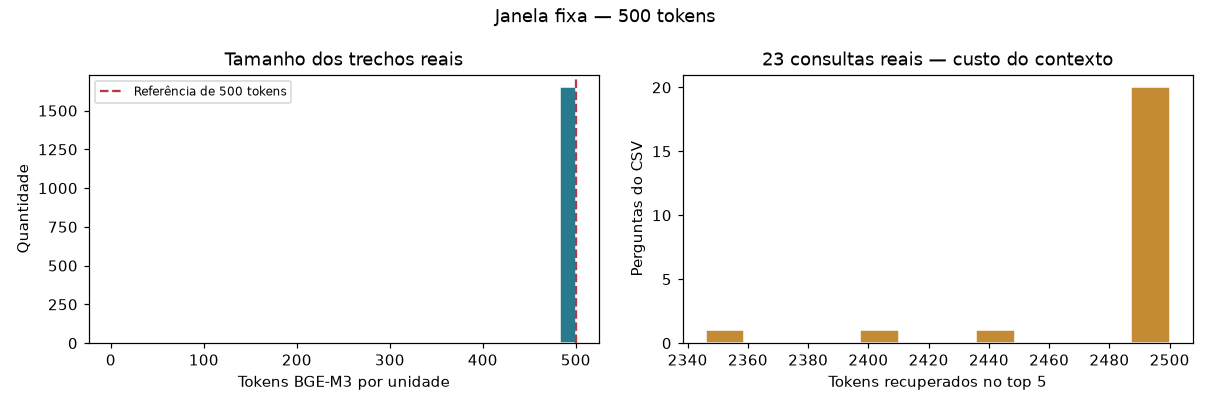

**Interpretação:** menos chunks, blocos maiores ou acerto de documento não demonstram que a resposta está sustentada. O critério principal é a fração de evidência coberta no contexto limitado por T, resumida em Cobertura@2500. Os quatro controles verificam o comportamento do pipeline; não estimam sua qualidade no corpus real.

In [6]:
FRAME_janela_500, RESULT_janela_500, CONTROL_janela_500 = avancado.experiment(STATE, 'janela_500')
display(pd.DataFrame([{k: RESULT_janela_500[k] for k in ('documentos', 'chunks', 'tokens_mediana', 'tokens_p95', 'tokens_maximo', 'chunks_acima_500_tokens', 'chunks_com_vinculo_dispositivo', 'cobertura_caracteres_pct', 'consultas_csv_executadas', 'resultados_csv_recuperados', 'tokens_top5_csv_mediana', 'segundos')}]).round(2))
display(pd.DataFrame([dict(escopo='Jurisprudência real', **RESULT_janela_500['metricas_reais']),
                      dict(escopo='Controle fictício', **RESULT_janela_500['metricas_controle_sintetico'])]))
experimento.plot_version(STATE, FRAME_janela_500, 'janela_500')
display(Markdown('**Interpretação:** menos chunks, blocos maiores ou acerto de documento não demonstram que a resposta está sustentada. O critério principal é a fração de evidência coberta no contexto limitado por T, resumida em Cobertura@2500. Os quatro controles verificam o comportamento do pipeline; não estimam sua qualidade no corpus real.'))


## 6. Versão — Parágrafo do acórdão

### Funcionamento

Cada parágrafo disponível no texto protegido é uma unidade. Linhas em branco definem a fronteira; na ausência delas, o fallback usa quebras simples. Sem quebras, o texto fica como uma unidade contínua, com esse método explicitamente registrado. Isso é uma aproximação por formatação, não uma recuperação automática da numeração oficial de parágrafos do tribunal.

Parágrafos maiores que 500 tokens **permanecem inteiros**. Seus tamanhos são medidos e não há truncamento silencioso. Isso permite comparar a unidade textual, mas também pode aumentar o custo do contexto. Na futura recuperação com embeddings, unidades acima da entrada do encoder precisarão de uma política explícita.

### Resultados e gráficos

Os gráficos abaixo mostram os tamanhos das unidades e o custo do contexto recuperado nas consultas da partição executada. Tokens e quantidade de resultados não são acurácia. As métricas dos controles fictícios permanecem separadas na tabela.


,documentos,chunks,tokens_mediana,tokens_p95,tokens_maximo,chunks_acima_500_tokens,chunks_com_vinculo_dispositivo,cobertura_caracteres_pct,consultas_csv_executadas,resultados_csv_recuperados,tokens_top5_csv_mediana,segundos
0,124,13843,24.0,198.0,4727,219,0,100.0,23,115,338.0,4.54


,escopo,status,perguntas,perguntas_com_suporte_top5,hit_suporte_5,hit_documento_5,documento_sem_suporte_5,mrr_suporte_5,tokens_top5_mediana,hit_suporte_5_apos_vinculo,perguntas_fornecidas,perguntas_sem_suporte_anotado
0,Jurisprudência real,avaliado,17,0,0.0,0.588235,10,0.0,346.0,0.0,23.0,6.0
1,Controle fictício,avaliado,4,2,0.5,1.000000,2,0.5,134.0,0.5,NaN,NaN


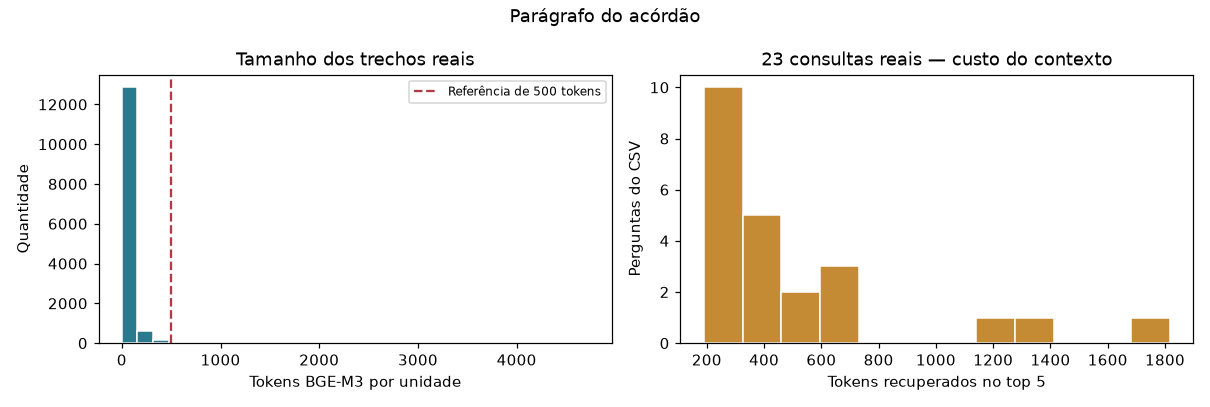

**Interpretação:** menos chunks, blocos maiores ou acerto de documento não demonstram que a resposta está sustentada. O critério principal é a fração de evidência coberta no contexto limitado por T, resumida em Cobertura@2500. Os quatro controles verificam o comportamento do pipeline; não estimam sua qualidade no corpus real.

In [7]:
FRAME_paragrafo, RESULT_paragrafo, CONTROL_paragrafo = avancado.experiment(STATE, 'paragrafo')
display(pd.DataFrame([{k: RESULT_paragrafo[k] for k in ('documentos', 'chunks', 'tokens_mediana', 'tokens_p95', 'tokens_maximo', 'chunks_acima_500_tokens', 'chunks_com_vinculo_dispositivo', 'cobertura_caracteres_pct', 'consultas_csv_executadas', 'resultados_csv_recuperados', 'tokens_top5_csv_mediana', 'segundos')}]).round(2))
display(pd.DataFrame([dict(escopo='Jurisprudência real', **RESULT_paragrafo['metricas_reais']),
                      dict(escopo='Controle fictício', **RESULT_paragrafo['metricas_controle_sintetico'])]))
experimento.plot_version(STATE, FRAME_paragrafo, 'paragrafo')
display(Markdown('**Interpretação:** menos chunks, blocos maiores ou acerto de documento não demonstram que a resposta está sustentada. O critério principal é a fração de evidência coberta no contexto limitado por T, resumida em Cobertura@2500. Os quatro controles verificam o comportamento do pipeline; não estimam sua qualidade no corpus real.'))


## 7. Versão — Seção e tema do acórdão

### Funcionamento

Títulos reconhecíveis definem **Relatório, Fundamentação, Voto e Dispositivo**; temas como **Horas extras** são identificados por título explícito ou menção lexical unívoca. Trechos contíguos da mesma seção e tema são agrupados. Mudanças de seção não são atravessadas. Quando não há evidência suficiente, a seção/tema permanece não identificada ou ambígua, sem inventar uma estrutura.

O tema explícito é preservado mesmo quando seu argumento inclui uma questão processual. A classificação é heurística: “Horas extras” identifica o assunto, não significa que horas extras tenham sido deferidas, indeferidas ou examinadas no mérito.

O vínculo ao dispositivo só é criado para fundamentação/voto quando há um único bloco decisório candidato com o mesmo tema reconhecido. Um dispositivo genérico ou vários candidatos ficam sem associação automática. A relação é uma correspondência temática documentada, não prova de entailment. O relatório não recebe vínculos decisórios.

O texto do dispositivo não é acrescentado ao índice nem aos resultados diretos para favorecer esta estratégia. Seu efeito é avaliado separadamente **depois** da busca. Blocos longos são medidos e mantidos, sem truncamento; diferenças de tokens recuperados devem acompanhar a interpretação de Hit@5.

### Resultados e gráficos

Os gráficos abaixo mostram os tamanhos das unidades e o custo do contexto recuperado nas consultas da partição executada. Tokens e quantidade de resultados não são acurácia. As métricas dos controles fictícios permanecem separadas na tabela.


,documentos,chunks,tokens_mediana,tokens_p95,tokens_maximo,chunks_acima_500_tokens,chunks_com_vinculo_dispositivo,cobertura_caracteres_pct,consultas_csv_executadas,resultados_csv_recuperados,tokens_top5_csv_mediana,segundos
0,124,2461,105.0,1270.0,34034,347,58,100.0,23,115,3258.0,3.37


,escopo,status,perguntas,perguntas_com_suporte_top5,hit_suporte_5,hit_documento_5,documento_sem_suporte_5,mrr_suporte_5,tokens_top5_mediana,hit_suporte_5_apos_vinculo,perguntas_fornecidas,perguntas_sem_suporte_anotado
0,Jurisprudência real,avaliado,17,4,0.235294,0.705882,8,0.205882,3258.0,0.235294,23.0,6.0
1,Controle fictício,avaliado,4,3,0.750000,1.000000,1,0.375000,923.0,0.750000,NaN,NaN


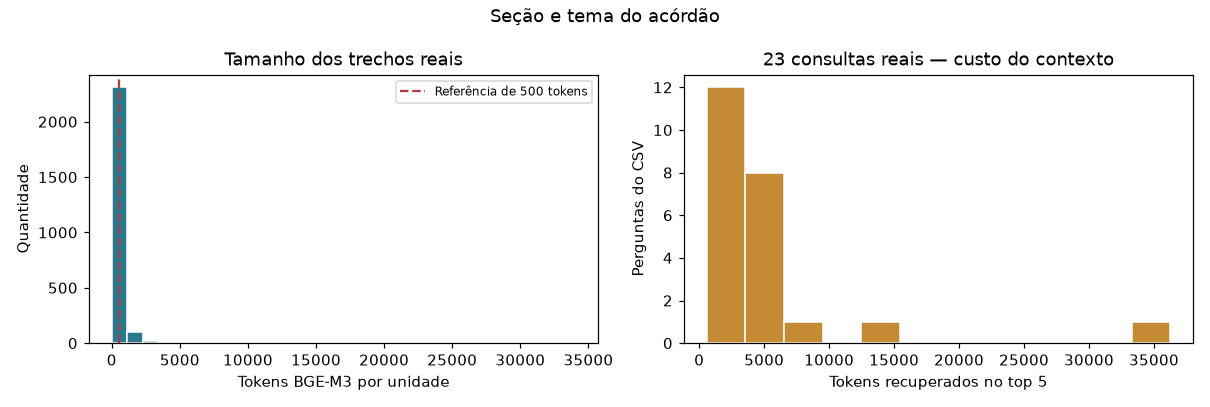

**Interpretação:** menos chunks, blocos maiores ou acerto de documento não demonstram que a resposta está sustentada. O critério principal é a fração de evidência coberta no contexto limitado por T, resumida em Cobertura@2500. Os quatro controles verificam o comportamento do pipeline; não estimam sua qualidade no corpus real.

In [8]:
FRAME_secao_tema, RESULT_secao_tema, CONTROL_secao_tema = avancado.experiment(STATE, 'secao_tema')
display(pd.DataFrame([{k: RESULT_secao_tema[k] for k in ('documentos', 'chunks', 'tokens_mediana', 'tokens_p95', 'tokens_maximo', 'chunks_acima_500_tokens', 'chunks_com_vinculo_dispositivo', 'cobertura_caracteres_pct', 'consultas_csv_executadas', 'resultados_csv_recuperados', 'tokens_top5_csv_mediana', 'segundos')}]).round(2))
display(pd.DataFrame([dict(escopo='Jurisprudência real', **RESULT_secao_tema['metricas_reais']),
                      dict(escopo='Controle fictício', **RESULT_secao_tema['metricas_controle_sintetico'])]))
experimento.plot_version(STATE, FRAME_secao_tema, 'secao_tema')
display(Markdown('**Interpretação:** menos chunks, blocos maiores ou acerto de documento não demonstram que a resposta está sustentada. O critério principal é a fração de evidência coberta no contexto limitado por T, resumida em Cobertura@2500. Os quatro controles verificam o comportamento do pipeline; não estimam sua qualidade no corpus real.'))


## 8. Variantes híbridas — regras de chunking e contexto, sem LLM

**Parágrafo com mínimo de 128 tokens:** agrupa parágrafos curtos consecutivos na mesma seção. O último grupo de uma seção pode continuar abaixo do mínimo; nunca se cruza um título reconhecido para cumprir artificialmente a meta. Parágrafos longos permanecem inteiros e seus riscos são registrados.

**Seção/tema com teto de 500 tokens:** subdivide blocos grandes, priorizando fronteiras textuais e respeitando o limite real de tokens. Preserva os rótulos e offsets do bloco-pai. O teto não reclassifica a decisão nem depende de LLM.

**Parágrafo com expansão para a seção:** indexa os mesmos parágrafos da versão-base. Após a busca, entrega o trecho encontrado primeiro e acrescenta contexto da sua seção, com deduplicação por documento/intervalo. Os pais não geram vetores extras. A expansão é submetida ao mesmo orçamento das demais estratégias.

Quando o orçamento termina, a montagem usa um prefixo explicitamente registrado, preservando o marcador de CPF. Esse corte de contexto é diferente de truncamento por encoder. Os limites de 512 e 8.192 são auditados e simulados; nenhum encoder é executado nesta comparação BM25.


### Parágrafo com tamanho mínimo

Resultados e gráficos da variante no mesmo corpus e partição.


,unidades,acima_512,acima_8192,vetores_planejados,vetores_gerados,reconstrucao_texto_base
0,3791,224,0,3791,0,aprovada


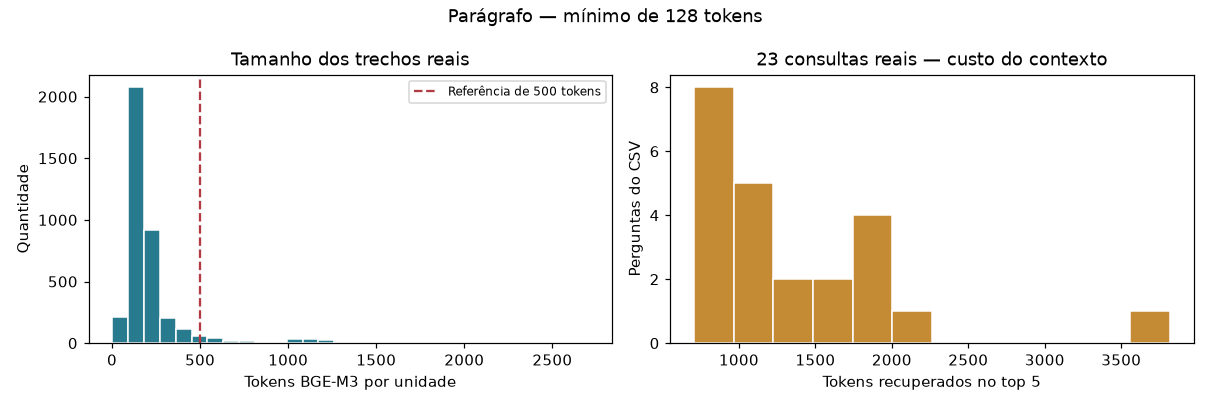

In [9]:
FRAME_paragrafo_minimo, RESULT_paragrafo_minimo, CONTROL_paragrafo_minimo = avancado.experiment(STATE, 'paragrafo_minimo')
display(pd.DataFrame([{k: RESULT_paragrafo_minimo[k] for k in ('unidades','acima_512','acima_8192','vetores_planejados','vetores_gerados','reconstrucao_texto_base')}]))
experimento.plot_version(STATE, FRAME_paragrafo_minimo, 'paragrafo_minimo')


### Seção dividida acima do teto

Resultados e gráficos da variante no mesmo corpus e partição.


,unidades,acima_512,acima_8192,vetores_planejados,vetores_gerados,reconstrucao_texto_base
0,3578,0,0,3578,0,aprovada


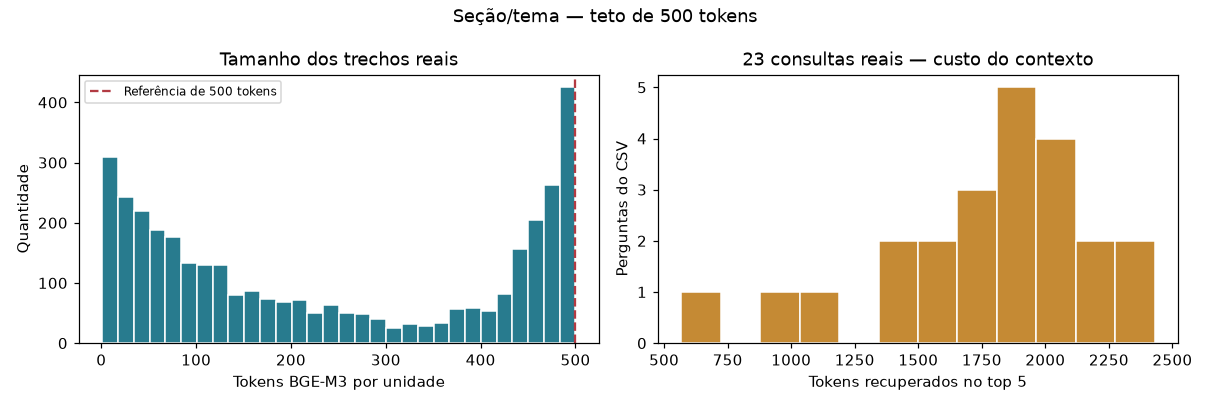

In [10]:
FRAME_secao_teto, RESULT_secao_teto, CONTROL_secao_teto = avancado.experiment(STATE, 'secao_teto')
display(pd.DataFrame([{k: RESULT_secao_teto[k] for k in ('unidades','acima_512','acima_8192','vetores_planejados','vetores_gerados','reconstrucao_texto_base')}]))
experimento.plot_version(STATE, FRAME_secao_teto, 'secao_teto')


### Parágrafo com expansão para seção

Resultados e gráficos da variante no mesmo corpus e partição.


,unidades,acima_512,acima_8192,vetores_planejados,vetores_gerados,reconstrucao_texto_base
0,13843,215,0,13843,0,aprovada


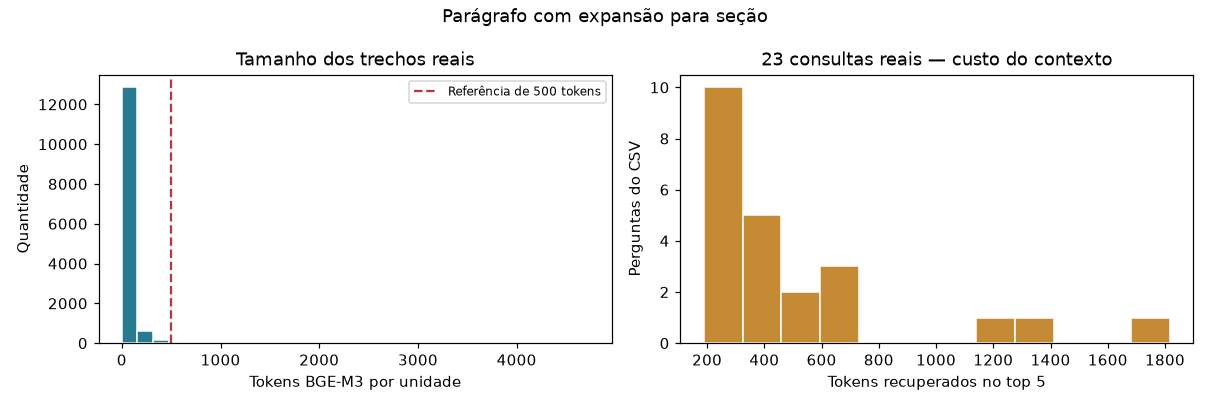

In [11]:
FRAME_paragrafo_secao, RESULT_paragrafo_secao, CONTROL_paragrafo_secao = avancado.experiment(STATE, 'paragrafo_secao')
display(pd.DataFrame([{k: RESULT_paragrafo_secao[k] for k in ('unidades','acima_512','acima_8192','vetores_planejados','vetores_gerados','reconstrucao_texto_base')}]))
experimento.plot_version(STATE, FRAME_paragrafo_secao, 'paragrafo_secao')


## 9. Caso fictício Alfa — o que apareceu no top 5?

A tabela permite inspecionar a recuperação real do BM25 no controle de horas extras/admissibilidade. Exibe trechos **somente do corpus fictício**, incluindo distratores de outros casos fictícios que possam aparecer. O rótulo de seção é informativo e não faz parte do texto indexado.

Observe a diferença entre localizar o pedido e localizar a ausência de exame do mérito. Se o recuperador não encontrar o suporte, o erro permanece registrado; o gabarito não é usado para substituir o ranking.


In [12]:
linhas_alfa = []
for versao in experimento.VERSOES:
    backend = experimento.BM25([row for doc in STATE['fixtures'] for row in experimento.make_chunks(doc, versao, STATE['tokenizer'])])
    top5 = backend.search(pergunta_alfa['pergunta'], 5)
    for row in top5:
        linhas_alfa.append({'versao': versao, 'rank': row['rank'], 'caso_ficticio': row['registro_id'],
                           'secao': row['secao'], 'tema': row['tema'], 'trecho_ficticio': row['texto']})
display(pd.DataFrame(linhas_alfa))


,versao,rank,caso_ficticio,secao,tema,trecho_ficticio
0,janela_500,1,sintetico_alfa,nao_classificada,nao_classificado,CASO FICTÍCIO ALFA\n\nRELATÓRIO\n\nNo caso Alf...
1,janela_500,2,sintetico_beta,nao_classificada,nao_classificado,CASO FICTÍCIO BETA\n\nRELATÓRIO\n\nNo caso Bet...
2,janela_500,3,sintetico_gama,nao_classificada,nao_classificado,CASO FICTÍCIO GAMA\n\nRELATÓRIO\n\nNo caso Gam...
3,janela_500,4,sintetico_delta,nao_classificada,nao_classificado,CASO FICTÍCIO DELTA\n\nRELATÓRIO\n\nNo caso De...
4,paragrafo,1,sintetico_alfa,nao_classificada,nao_classificado,Não conhecer do recurso quanto às horas extras...
5,paragrafo,2,sintetico_alfa,nao_classificada,nao_classificado,O recurso não é conhecido por ausência de pres...
6,paragrafo,3,sintetico_alfa,nao_classificada,nao_classificado,CASO FICTÍCIO ALFA\n\n
7,paragrafo,4,sintetico_alfa,nao_classificada,nao_classificado,"No caso Alfa, o pedido de horas extras foi men..."
8,paragrafo,5,sintetico_alfa,nao_classificada,nao_classificado,"No caso Alfa, o pedido de horas extras foi men..."
9,secao_tema,1,sintetico_alfa,relatorio,horas_extras,"No caso Alfa, o pedido de horas extras foi men..."


## Métrica principal — Cobertura@T

**Montagem:** consumir os trechos em ordem de ranking até T tokens, cortando o último se necessário. A busca tem profundidade máxima fixa de 50 candidatos positivos. O corte não é guiado pelo gabarito. Uma seção de 8 mil tokens em primeiro lugar não é pulada para encaixar evidência posterior: apenas seu prefixo que cabe é entregue. O contexto concatenado, incluindo separadores, nunca pode ultrapassar T.

**Curva:** T = 500, 1.000, 2.500 e 5.000. Cada ponto é a média, por pergunta com gabarito, da fração de caracteres da evidência coberta. A comparação usa o mesmo budget máximo e registra os tokens realmente utilizados. O número-resumo é **a cobertura média em T=2.500**, referência de custo das cinco janelas fixas de 500 tokens. As curvas podem se cruzar; não se declara superioridade universal sem especificar o T de uso.

**Taxa de fragmentação:** proporção de perguntas anotadas em que um intervalo contínuo de evidência precisa de duas ou mais unidades indexadas. Não se confunde com duas evidências independentes, cada uma inteira em um parágrafo. Com alternativas suficientes de suporte, escolhe-se a de menor demanda de unidades; os desempates priorizam menor fragmentação.

**Unidades necessárias:** menor quantidade de unidades distintas que cobre uma alternativa inteira do gabarito. Também se registra o tamanho do prefixo do ranking necessário para alcançar cobertura completa, incluindo os distratores encontrados antes da prova. Se não houver cobertura nos 50 candidatos, esse segundo número fica ausente, sem virar zero.

**Taxa de truncamento:** proporção das perguntas anotadas que perde alguma evidência depois do corte simulado do encoder em 512 ou 8.192 tokens, considerando tokens especiais. Unidade longa não basta para contar como evidência truncada: se a prova está no prefixo preservado, não há perda. A fração de evidência perdida é registrada separadamente. Como a execução é BM25, a taxa de truncamento real continua não aplicável; os resultados de simulação são identificados como tais.

**Buscar pequeno, entregar maior:** `paragrafo_secao` indexa os mesmos parágrafos pequenos da base e entrega o trecho encontrado antes de ampliar para a seção. A expansão é deduplicada e limitada pelo mesmo T; não gera vetores de pais nem usa LLM. Suas unidades indexadas não são substituídas por seções enormes.

O CSV ainda não contém intervalos esperados. Portanto, não há valores reais de Cobertura@T, fragmentação ou truncamento da evidência para escolher uma estratégia. O pipeline está implementado e os controles abaixo verificam as regras sem fabricar um gabarito real.


### Controle autoral — evidência no fim de uma seção acima de 8.192 tokens

O exemplo é fictício e não representa jurisprudência. A evidência fica depois de um longo bloco de contexto. A seção inteira é o primeiro resultado na versão seção/tema; seu prefixo consome T antes de alcançar a evidência. Na versão de parágrafos, o trecho específico pode ser buscado diretamente; a expansão para a seção mantém esse núcleo e respeita o budget. Este controle demonstra o mecanismo, não escolhe a estratégia vencedora no acervo real.


,versao,orcamento,tokens_utilizados,primeiro_trecho_tokens,cobertura_T,cortes_contexto
0,secao_tema,500,500,20015,0.0,1
1,secao_tema,1000,1000,20015,0.0,1
2,secao_tema,2500,2500,20015,0.0,1
3,secao_tema,5000,5000,20015,0.0,1
4,paragrafo,500,11,11,1.0,0
5,paragrafo,1000,11,11,1.0,0
6,paragrafo,2500,11,11,1.0,0
7,paragrafo,5000,11,11,1.0,0
8,paragrafo_secao,500,500,11,1.0,1
9,paragrafo_secao,1000,1000,11,1.0,1


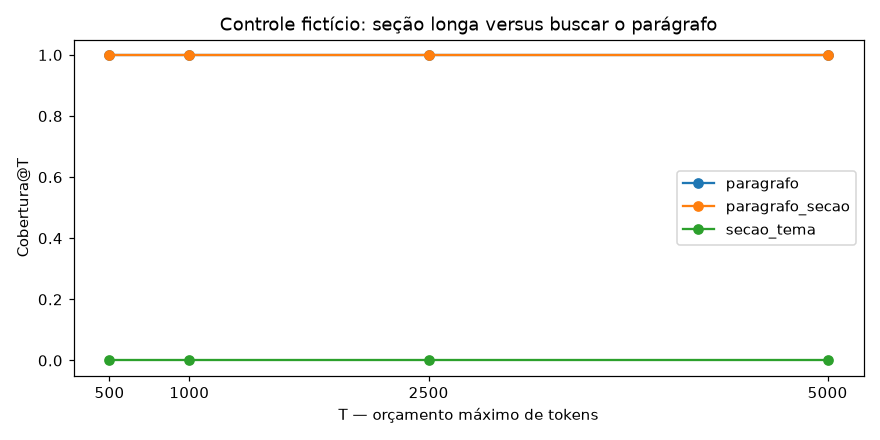

In [13]:
from worker.ingestao.jurisprudencia import cobertura_metricas
CONTROLE_SECAO_LONGA = cobertura_metricas.long_section_demo(STATE['tokenizer'])
assert CONTROLE_SECAO_LONGA.tokens_utilizados.le(CONTROLE_SECAO_LONGA.orcamento).all()
assert CONTROLE_SECAO_LONGA[CONTROLE_SECAO_LONGA.versao.eq('secao_tema')].cobertura_T.eq(0).all()
assert CONTROLE_SECAO_LONGA[CONTROLE_SECAO_LONGA.versao.eq('paragrafo_secao')].cobertura_T.eq(1).all()
display(CONTROLE_SECAO_LONGA)
(STATE['report'] / 'controle_secao_longa.json').write_text(CONTROLE_SECAO_LONGA.to_json(orient='records', force_ascii=False), encoding='utf-8')
fig, ax = plt.subplots(figsize=(8, 4))
for versao, grupo in CONTROLE_SECAO_LONGA.groupby('versao'):
    ax.plot(grupo.orcamento, grupo.cobertura_T, marker='o', label=versao)
ax.set(xlabel='T — orçamento máximo de tokens', ylabel='Cobertura@T', ylim=(-0.05,1.05),
       title='Controle fictício: seção longa versus buscar o parágrafo')
ax.set_xticks(avancado.BUDGETS); ax.legend()
fig.tight_layout(); fig.savefig(STATE['report'] / 'controle_secao_longa.png', dpi=140); plt.show()


## 10. Comparação consolidada — Cobertura@T e Cobertura@2500

As curvas comparam **Cobertura@T** nos quatro budgets, e a tabela destaca **Cobertura@2500**. Os controles fictícios ficam separados. Sem evidências reais, não se atribui um vencedor a partir de score BM25, custo do contexto ou desempenho em exemplos autorais.

A métrica direta conta apenas os cinco resultados da busca. `hit_suporte_5_apos_vinculo` é uma métrica adicional, com os dispositivos associados acrescentados posteriormente. O número de tokens deve ser considerado: um bloco enorme pode conter a referência, mas também muito conteúdo irrelevante. A referência anotada pode não esgotar todas as evidências juridicamente equivalentes, portanto o avaliador mede cobertura do gabarito disponível, não compreensão jurídica universal.


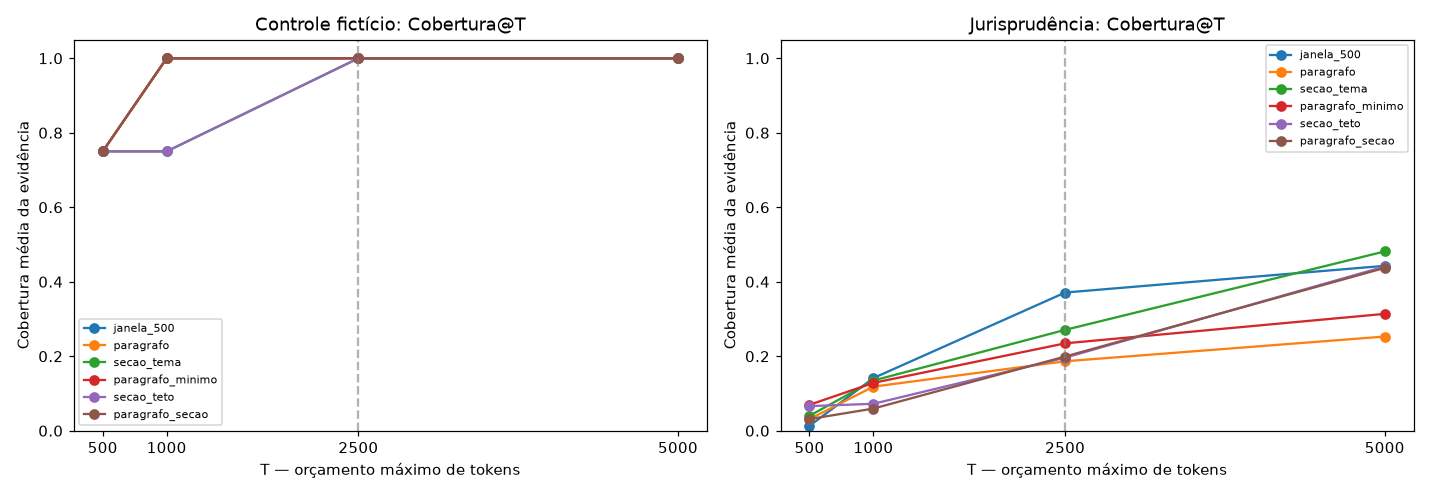

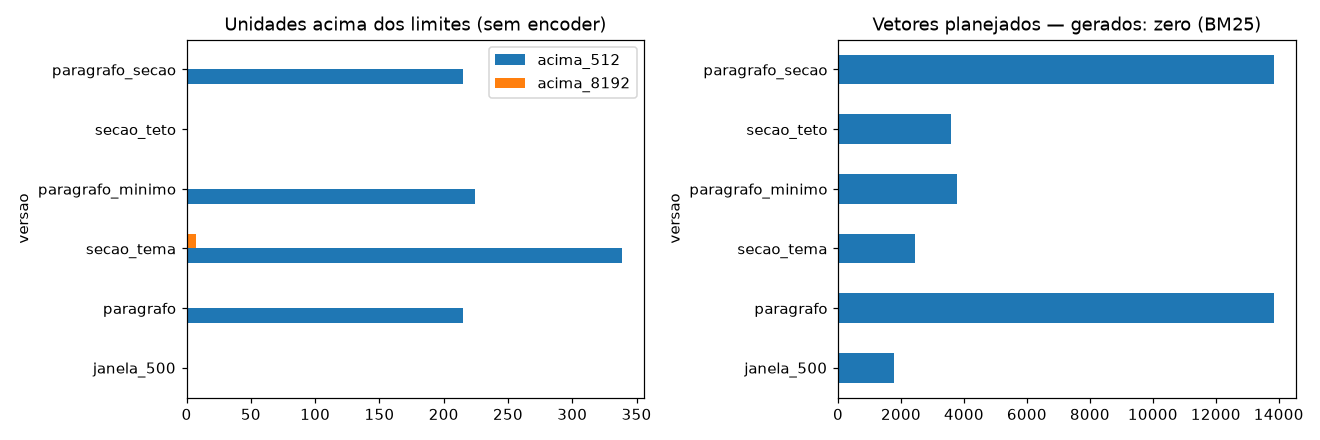

,versao,unidades,acima_512,acima_8192,fracao_secao_ambigua,fracao_secao_nao_identificada,fracao_tema_ambiguo,fracao_tema_nao_identificado,vetores_planejados,vetores_gerados,reconstrucao_texto_base
0,janela_500,1770,0,0,NaN,NaN,NaN,NaN,1770,0,aprovada
1,paragrafo,13843,215,0,NaN,NaN,NaN,NaN,13843,0,aprovada
2,secao_tema,2461,339,7,0.0,0.362454,0.051605,0.521333,2461,0,aprovada
3,paragrafo_minimo,3791,224,0,NaN,NaN,NaN,NaN,3791,0,aprovada
4,secao_teto,3578,0,0,0.0,0.357742,0.042761,0.610397,3578,0,aprovada
5,paragrafo_secao,13843,215,0,NaN,NaN,NaN,NaN,13843,0,aprovada


perguntas  ...  tokens_medios
escopo                versao           orcamento             ...               
controle_sintetico    janela_500       500                4  ...        500.000
                                       1000               4  ...       1000.000
                                       2500               4  ...       1457.000
                                       5000               4  ...       1457.000
                      paragrafo        500                4  ...        500.000
                                       1000               4  ...       1000.000
                                       2500               4  ...       1392.000
                                       5000               4  ...       1392.000
                      paragrafo_minimo 500                4  ...        500.000
                                       1000               4  ...       1000.000
                                       2500               4  ...       1444.250
                                       5000               4  ...       1444.250
                      paragrafo_secao  500                4  ...        500.000
                                       1000               4  ...       1000.000
                                       2500               4  ...       1444.250
                                       5000               4  ...       1444.250
                      secao_tema       500                4  ...        500.000
                                       1000               4  ...       1000.000
                                       2500               4  ...       1406.500
                                       5000               4  ...       1406.500
                      secao_teto       500                4  ...        500.000
                                       1000               4  ...       1000.000
                                       2500               4  ...       1406.500
                                       5000               4  ...       1406.500
jurisprudencia_ajuste janela_500       500               23  ...        499.913
                                       1000              23  ...       1000.000
                                       2500              23  ...       2500.000
                                       5000              23  ...       5000.000
                      paragrafo        500               23  ...        500.000
                                       1000              23  ...       1000.000
                                       2500              23  ...       2500.000
                                       5000              23  ...       4540.609
                      paragrafo_minimo 500               23  ...        500.000
                                       1000              23  ...       1000.000
                                       2500              23  ...       2499.957
                                       5000              23  ...       5000.000
                      paragrafo_secao  500               23  ...        500.000
                                       1000              23  ...        999.957
                                       2500              23  ...       2500.000
                                       5000              23  ...       5000.000
                      secao_tema       500               23  ...        500.000
                                       1000              23  ...       1000.000
                                       2500              23  ...       2500.000
                                       5000              23  ...       5000.000
                      secao_teto       500               23  ...        500.000
                                       1000              23  ...       1000.000
                                       2500              23  ...       2500.000
                                       5000              23  ...       5000.000

[48 rows x 4 columns]

**Resumo principal: cobertura média com T = 2.500 tokens**

,escopo,versao,perguntas_total,perguntas_com_gabarito,cobertura_media_2500,tokens_utilizados_medios,estado
0,jurisprudencia_ajuste,janela_500,23,17,0.3711,2500.0000,avaliado
1,controle_sintetico,janela_500,4,4,1.0000,1457.0000,avaliado
2,jurisprudencia_ajuste,paragrafo,23,17,0.1865,2500.0000,avaliado
3,controle_sintetico,paragrafo,4,4,1.0000,1392.0000,avaliado
4,jurisprudencia_ajuste,secao_tema,23,17,0.2708,2500.0000,avaliado
5,controle_sintetico,secao_tema,4,4,1.0000,1406.5000,avaliado
6,jurisprudencia_ajuste,paragrafo_minimo,23,17,0.2347,2499.9565,avaliado
7,controle_sintetico,paragrafo_minimo,4,4,1.0000,1444.2500,avaliado
8,jurisprudencia_ajuste,secao_teto,23,17,0.1962,2500.0000,avaliado
9,controle_sintetico,secao_teto,4,4,1.0000,1406.5000,avaliado


**Fragmentação, unidades necessárias e truncamento da evidência**

,escopo,versao,perguntas_total,perguntas_com_gabarito,taxa_fragmentacao,media_unidades_necessarias,maximo_unidades_necessarias,media_unidades_ranqueadas_ate_cobrir,perguntas_sem_cobertura_no_ranking,taxa_truncamento_encoder_real,estado_encoder,taxa_truncamento_encoder_512_simulada,fracao_media_evidencia_perdida_encoder_512_simulada,taxa_truncamento_encoder_8192_simulada,fracao_media_evidencia_perdida_encoder_8192_simulada
0,jurisprudencia_ajuste,janela_500,23,17,0.2941,1.8235,4,11.3333,8,NaN,nao_executado_bm25,0.0000,0.0000,0,0
1,controle_sintetico,janela_500,4,4,0.0000,1.0000,1,1.2500,0,NaN,nao_executado_bm25,0.0000,0.0000,0,0
2,jurisprudencia_ajuste,paragrafo,23,17,0.8824,4.1176,12,22.0000,15,NaN,nao_executado_bm25,0.0000,0.0000,0,0
3,controle_sintetico,paragrafo,4,4,0.0000,1.0000,1,9.0000,0,NaN,nao_executado_bm25,0.0000,0.0000,0,0
4,jurisprudencia_ajuste,secao_tema,23,17,0.1765,1.4706,3,9.5455,6,NaN,nao_executado_bm25,0.4118,0.2923,0,0
5,controle_sintetico,secao_tema,4,4,0.0000,1.0000,1,3.5000,0,NaN,nao_executado_bm25,0.0000,0.0000,0,0
6,jurisprudencia_ajuste,paragrafo_minimo,23,17,0.3529,2.3529,7,21.8000,12,NaN,nao_executado_bm25,0.0000,0.0000,0,0
7,controle_sintetico,paragrafo_minimo,4,4,0.0000,1.0000,1,4.5000,0,NaN,nao_executado_bm25,0.0000,0.0000,0,0
8,jurisprudencia_ajuste,secao_teto,23,17,0.4118,1.8824,3,18.5000,9,NaN,nao_executado_bm25,0.0000,0.0000,0,0
9,controle_sintetico,secao_teto,4,4,0.0000,1.0000,1,3.5000,0,NaN,nao_executado_bm25,0.0000,0.0000,0,0


,escopo,orcamento,a,b,n,status,vitorias,empates,derrotas,delta_media,ic95_inf,ic95_sup,seed,replicas
0,controle_sintetico,500,janela_500,paragrafo,4,calculado,0,4,0,0.000000,0.000000,0.000000,20261114,2000
1,controle_sintetico,500,janela_500,paragrafo_minimo,4,calculado,0,4,0,0.000000,0.000000,0.000000,20261114,2000
2,controle_sintetico,500,janela_500,paragrafo_secao,4,calculado,0,4,0,0.000000,0.000000,0.000000,20261114,2000
3,controle_sintetico,500,janela_500,secao_tema,4,calculado,0,4,0,0.000000,0.000000,0.000000,20261114,2000
4,controle_sintetico,500,janela_500,secao_teto,4,calculado,0,4,0,0.000000,0.000000,0.000000,20261114,2000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,jurisprudencia_ajuste,5000,paragrafo_minimo,secao_tema,17,calculado,2,8,7,-0.167607,-0.399390,0.053409,20261114,2000
116,jurisprudencia_ajuste,5000,paragrafo_minimo,secao_teto,17,calculado,2,10,5,-0.127105,-0.319551,0.048480,20261114,2000
117,jurisprudencia_ajuste,5000,paragrafo_secao,secao_tema,17,calculado,3,11,3,-0.044193,-0.276444,0.170625,20261114,2000
118,jurisprudencia_ajuste,5000,paragrafo_secao,secao_teto,17,calculado,4,10,3,-0.003692,-0.264255,0.248099,20261114,2000


**Protocolo concluído:** seis estratégias na partição **ajuste**, com 23 consultas e 17 perguntas com evidências reais. O teste final não é executado automaticamente. Bootstrap e resultados sintéticos permanecem separados dos resultados reais.

In [14]:
CURVAS, PARES, AUDITORIA = avancado.finish(STATE)
display(AUDITORIA[['versao','unidades','acima_512','acima_8192','fracao_secao_ambigua',
    'fracao_secao_nao_identificada','fracao_tema_ambiguo','fracao_tema_nao_identificado',
    'vetores_planejados','vetores_gerados','reconstrucao_texto_base']])
display(CURVAS.groupby(['escopo','versao','orcamento']).agg(perguntas=('query_id','size'),
    perguntas_com_gabarito=('suporte_fracao','count'), suporte_medio=('suporte_fracao','mean'),
    tokens_medios=('tokens_utilizados','mean')).round(3))
PRINCIPAL_2500 = pd.read_json(STATE['report'] / 'cobertura_2500_resumo.json')
ESTRUTURA_EVIDENCIA = pd.read_json(STATE['report'] / 'fragmentacao_unidades_truncamento.json')
display(Markdown('**Resumo principal: cobertura média com T = 2.500 tokens**'))
display(PRINCIPAL_2500[['escopo','versao','perguntas_total','perguntas_com_gabarito','cobertura_media_2500','tokens_utilizados_medios','estado']].round(4))
display(Markdown('**Fragmentação, unidades necessárias e truncamento da evidência**'))
display(ESTRUTURA_EVIDENCIA.round(4))
display(PARES)
display(Markdown(f"**Protocolo concluído:** seis estratégias na partição **{STATE['partition']}**, "
    f"com {len(STATE['queries'])} consultas e {len(STATE['questions'])} perguntas com evidências reais. "
    "O teste final não é executado automaticamente. Bootstrap e resultados sintéticos permanecem separados dos resultados reais."))


### 10.1. Resultado operacional das consultas de ajuste nas seis estratégias

Cada linha abaixo corresponde a uma pergunta de ajuste e uma das seis estratégias. As perguntas reservadas ao teste final não são consultadas nesta execução. `resultados` conta itens retornados, não acertos. `suporte_anotado` informa se a pergunta tem referências válidas para avaliação. Os rankings detalhados, com IDs, offsets, hashes e scores, ficam nos arquivos `*_ranking_csv.json`; textos reais não são publicados no notebook.

O gráfico compara tokens recuperados, sem impor truncamento aos parágrafos ou blocos longos. Um contexto grande pode conter mais material e também mais ruído; esse custo não define sozinho a melhor estratégia.

**Leitura do custo:** o eixo y da caixa usa escala logarítmica. A tabela registra mediana, p90 e máximo por estratégia. Outliers são definidos por Tukey (1,5×IQR), calculado nos tokens da escala original e por estratégia. Pxx identifica o ID da pergunta no CSV; a tabela associa cada ponto ao alvo de chunking e aos acórdãos recuperados, identificados por hashes e tribunal, sem expor texto ou número de processo.

Os tokens aqui são a soma das cinco unidades recuperadas, antes de expansão, deduplicação ou corte por orçamento. A curva por budgets é uma análise distinta. Valores zero permanecem nas tabelas e ficam fora do eixo logarítmico. Quando o IQR é zero, pequenas diferenças absolutas podem ser marcadas: um outlier é um sinal de investigação, não prova de defeito no acórdão ou no chunking.


,consultas_executadas,resultados_recuperados,perguntas_com_suporte_anotado,tokens_top5_mediana
versao,,,,
janela_500,23,115,17,2500.0
paragrafo,23,115,17,338.0
paragrafo_minimo,23,115,17,1043.0
paragrafo_secao,23,115,17,338.0
secao_tema,23,115,17,3258.0
secao_teto,23,115,17,1850.0


,query_id,versao,tipo,resultados,documentos_distintos,tokens_top5,suporte_anotado,status
0,juris_001,janela_500,só_jurisprudência,5,1,2500,True,com_referencia_de_suporte
1,juris_002,janela_500,só_jurisprudência,5,2,2500,True,com_referencia_de_suporte
2,juris_003,janela_500,só_jurisprudência,5,4,2500,True,com_referencia_de_suporte
3,juris_004,janela_500,só_jurisprudência,5,3,2500,True,com_referencia_de_suporte
4,juris_005,janela_500,só_jurisprudência,5,4,2500,True,com_referencia_de_suporte
...,...,...,...,...,...,...,...,...
133,juris_024,paragrafo_secao,temporal,5,4,295,True,com_referencia_de_suporte
134,juris_026,paragrafo_secao,só_jurisprudência,5,5,325,True,com_referencia_de_suporte
135,juris_027,paragrafo_secao,sem_resposta_no_corpus,5,4,270,False,busca_executada_sem_gabarito_de_suporte
136,juris_028,paragrafo_secao,fora_do_escopo,5,5,280,False,busca_executada_sem_gabarito_de_suporte


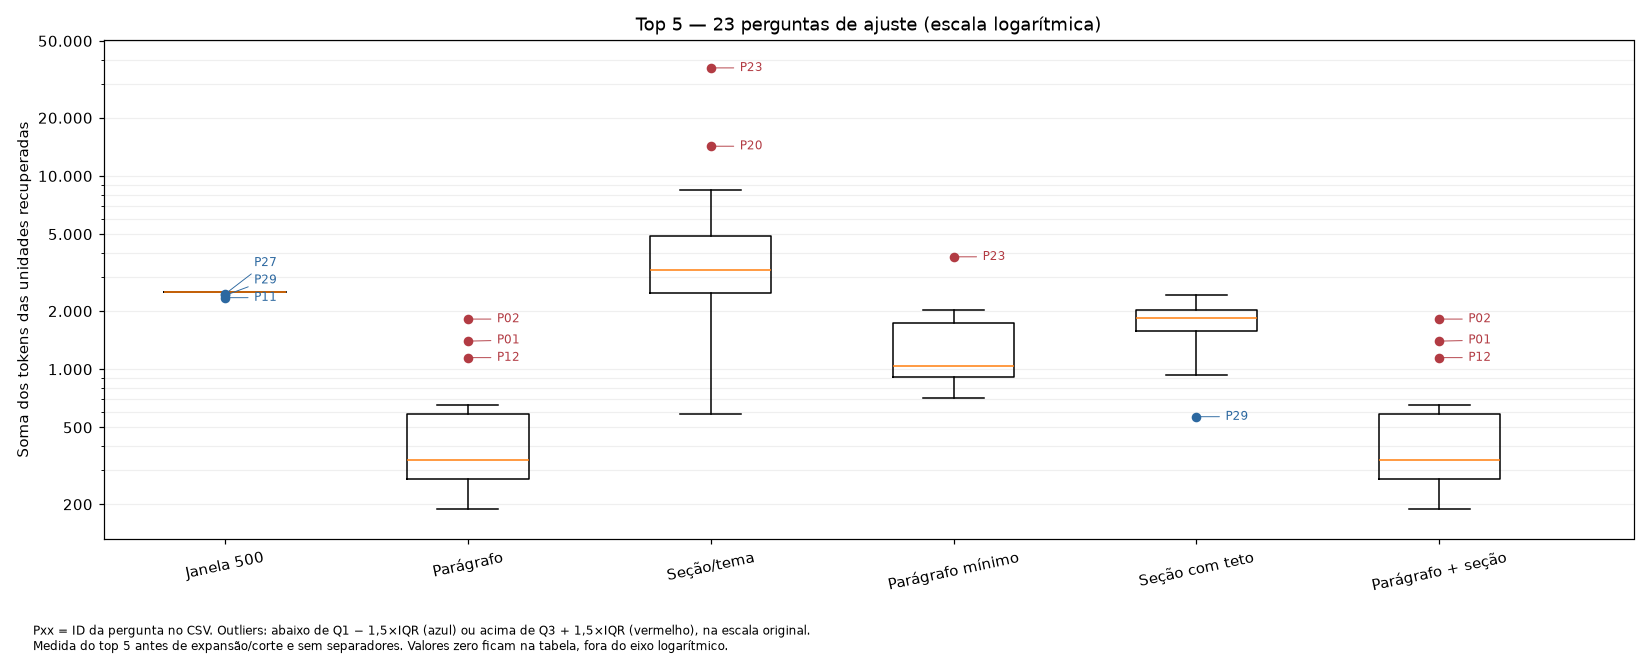

**Mediana, p90 e máximo dos tokens recuperados no top 5:**

,versao,perguntas,mediana_tokens,p90_tokens,maximo_tokens,outliers_altos,outliers_baixos,zero_tokens
0,janela_500,23,2500.0,2500.0,2500,0,3,0
1,paragrafo,23,338.0,1049.4,1818,3,0,0
2,secao_tema,23,3258.0,7998.4,36256,2,0,0
3,paragrafo_minimo,23,1043.0,1967.0,3817,1,0,0
4,secao_teto,23,1850.0,2258.4,2430,0,1,0
5,paragrafo_secao,23,338.0,1049.4,1818,3,0,0


**Perguntas marcadas no gráfico e acórdão com maior contribuição em tokens:**

,rotulo_pergunta,query_id,versao,tokens_top5,tipo_outlier,alvo_chunking,fundamentacao_longa,acordao_dominante,tribunal,arquivo_id,maior_chunk_tokens,tokens_acordao_dominante,fracao_tokens_acordao_dominante
1,P27,juris_027,janela_500,2447,baixo,deve abster-se se não houver evidência,False,1c04b86db32e890058c31cac908041f2182a9346c8a76c...,TST,f12,500,500,0.204
2,P29,juris_029,janela_500,2408,baixo,deve recusar prometer resultado,False,c5358b9b71a230a145e9e2d7481a632107fdaf871bad5c...,TST,f19,500,908,0.377
0,P11,juris_011,janela_500,2346,baixo,metadados (tribunal explícito) + ementa,False,5fe13dbb99976555dea4ac8aab799f9a1649a876476413...,TST,f19,500,2346,1.000
4,P02,juris_002,paragrafo,1818,alto,fundamentação longa,True,23dc35039954744131671cddd679415cb86a8514c636be...,STF,f04,1260,1260,0.693
3,P01,juris_001,paragrafo,1398,alto,fundamentação longa,True,add2cf364568dfb927988652f1e12ed56b14269c455a8a...,TST,f15,655,1398,1.000
5,P12,juris_012,paragrafo,1148,alto,tese curta / ementa,False,eb5d41f51a85f1b0e26dee967e473774b8c783906d8876...,TRT-17,f10,782,1148,1.000
8,P23,juris_023,paragrafo_minimo,3817,alto,tese curta / ementa,False,23dc35039954744131671cddd679415cb86a8514c636be...,STF,f04,1260,3502,0.917
11,P02,juris_002,paragrafo_secao,1818,alto,fundamentação longa,True,23dc35039954744131671cddd679415cb86a8514c636be...,STF,f04,1260,1260,0.693
10,P01,juris_001,paragrafo_secao,1398,alto,fundamentação longa,True,add2cf364568dfb927988652f1e12ed56b14269c455a8a...,TST,f15,655,1398,1.000
12,P12,juris_012,paragrafo_secao,1148,alto,tese curta / ementa,False,eb5d41f51a85f1b0e26dee967e473774b8c783906d8876...,TRT-17,f10,782,1148,1.000


**Alvo declarado no CSV: fundamentação longa versus demais alvos:**

,versao,fundamentacao_longa,perguntas,outliers,outliers_altos,outliers_baixos,mediana_tokens,maximo_tokens,fracao_outliers
0,janela_500,False,19,3,0,3,2500.0,2500,0.158
1,janela_500,True,4,0,0,0,2500.0,2500,0.000
2,paragrafo,False,19,1,1,0,325.0,1148,0.053
3,paragrafo,True,4,2,2,0,887.0,1818,0.500
4,paragrafo_minimo,False,19,1,1,0,1043.0,3817,0.053
5,paragrafo_minimo,True,4,0,0,0,1440.5,2035,0.000
6,paragrafo_secao,False,19,1,1,0,325.0,1148,0.053
7,paragrafo_secao,True,4,2,2,0,887.0,1818,0.500
8,secao_tema,False,19,2,2,0,3897.0,36256,0.105
9,secao_tema,True,4,0,0,0,2793.0,5244,0.000


**Acórdãos associados aos outliers — frequência em perguntas distintas:**

,registro_id,perguntas_outlier_associadas,ocorrencias_estrategia_pergunta,maior_chunk_tokens,tribunal,arquivo_id,perguntas_em_que_aparece_no_top5,fracao_perguntas_associadas_a_outlier
18,e4862879d9564b9ba80e538bf37b00bdcfc7bfba104918...,3,3,2161,TRT-17,f07,11,0.273
1,1ea70dec36a231b4769616bacdd26562e34e16879c0376...,3,4,441,TRT-17,f10,7,0.429
2,23dc35039954744131671cddd679415cb86a8514c636be...,2,4,34034,STF,f04,6,0.333
17,e2172ff5725a001cc58495114e7397473edf82798bc8d5...,2,3,1205,TRT-17,f10,5,0.400
14,c5358b9b71a230a145e9e2d7481a632107fdaf871bad5c...,2,3,1105,TST,f19,2,1.000
15,d6ef2d62d7dc2d287db804ce5ee368a48448a5f3a97a74...,2,3,500,TRT-17,f08,5,0.400
20,feed0a7b9b73ad571a85fe69b9c690da12b828b8423a1c...,1,1,6767,TRT-17,f08,6,0.167
3,27077ec6b641c5505ab36333ac55b96c23db63fa8b00e4...,1,1,3954,TRT-17,f10,3,0.333
19,eb5d41f51a85f1b0e26dee967e473774b8c783906d8876...,1,2,782,TRT-17,f10,2,0.500
13,add2cf364568dfb927988652f1e12ed56b14269c455a8a...,1,2,655,TST,f15,7,0.143


**Leitura dos outliers altos:** 5 perguntas distintas; 2 têm o alvo declarado 'fundamentação longa'. A classificação do alvo vem do CSV e não é uma avaliação da qualidade do acórdão.

**Maior pico:** P23 na estratégia `secao_tema`, com 36,256 tokens. Alvo declarado: **tese curta / ementa**. O acórdão `23dc350399547441` (STF) contribui com 93.9% dos tokens. Essa concentração orienta a investigação do bloco recuperado, sem provar um defeito no documento.

In [15]:
BUSCAS_CSV = pd.concat([
    pd.DataFrame(json.loads((STATE['report'] / (versao + '_buscas_csv.json')).read_text(encoding='utf-8'))).assign(versao=versao)
    for versao in avancado.TITLES
], ignore_index=True)
assert len(BUSCAS_CSV) == len(STATE['queries']) * len(avancado.TITLES)
assert BUSCAS_CSV.groupby('versao').query_id.nunique().eq(len(STATE['queries'])).all()
display(BUSCAS_CSV.groupby('versao').agg(consultas_executadas=('query_id','size'), resultados_recuperados=('resultados','sum'),
    perguntas_com_suporte_anotado=('suporte_anotado','sum'), tokens_top5_mediana=('tokens_top5','median')).round(2))
display(BUSCAS_CSV[['query_id','versao','tipo','resultados','documentos_distintos','tokens_top5','suporte_anotado','status']])
from worker.ingestao.jurisprudencia.contexto_graficos import render
RESUMO_CONTEXTO, OUTLIERS_CONTEXTO, ACORDAOS_OUTLIERS, ALVOS_OUTLIERS = render(ROOT, STATE['report'])
display(Markdown('**Mediana, p90 e máximo dos tokens recuperados no top 5:**'))
display(RESUMO_CONTEXTO[['versao','perguntas','mediana_tokens','p90_tokens','maximo_tokens','outliers_altos','outliers_baixos','zero_tokens']].round(1))
display(Markdown('**Perguntas marcadas no gráfico e acórdão com maior contribuição em tokens:**'))
COLUNAS_OUTLIERS = ['rotulo_pergunta','query_id','versao','tokens_top5','tipo_outlier','alvo_chunking',
                   'fundamentacao_longa','acordao_dominante','tribunal','arquivo_id','maior_chunk_tokens',
                   'tokens_acordao_dominante','fracao_tokens_acordao_dominante']
display(OUTLIERS_CONTEXTO[[c for c in COLUNAS_OUTLIERS if c in OUTLIERS_CONTEXTO]].round(3))
display(Markdown('**Alvo declarado no CSV: fundamentação longa versus demais alvos:**'))
display(ALVOS_OUTLIERS.round(3))
display(Markdown('**Acórdãos associados aos outliers — frequência em perguntas distintas:**'))
display(ACORDAOS_OUTLIERS.head(15).round(3))
ALTOS_DISTINTOS = OUTLIERS_CONTEXTO[OUTLIERS_CONTEXTO.tipo_outlier.eq('alto')].drop_duplicates('query_id')
if not ALTOS_DISTINTOS.empty:
    display(Markdown(f"**Leitura dos outliers altos:** {len(ALTOS_DISTINTOS)} perguntas distintas; "
        f"{int(ALTOS_DISTINTOS.fundamentacao_longa.sum())} têm o alvo declarado 'fundamentação longa'. "
        "A classificação do alvo vem do CSV e não é uma avaliação da qualidade do acórdão."))
if not OUTLIERS_CONTEXTO.empty:
    PICO = OUTLIERS_CONTEXTO.sort_values('tokens_top5', ascending=False).iloc[0]
    display(Markdown(f"**Maior pico:** {PICO['rotulo_pergunta']} na estratégia `{PICO['versao']}`, "
        f"com {int(PICO['tokens_top5']):,} tokens. Alvo declarado: **{PICO['alvo_chunking']}**. "
        f"O acórdão `{str(PICO.get('acordao_dominante', ''))[:16]}` ({PICO.get('tribunal', '')}) "
        f"contribui com {100 * PICO.get('fracao_tokens_acordao_dominante', 0):.1f}% dos tokens. "
        "Essa concentração orienta a investigação do bloco recuperado, sem provar um defeito no documento."))


## 11. Diagnóstico, observações e integração

- **O que foi testado:** três unidades reais de chunking, fidelidade do texto protegido, busca lexical no mesmo corpus, avaliador por suporte exato e regressão que separa menção no relatório de decisão do tribunal.
- **O que o teste não conclui:** qual estratégia terá melhor desempenho com embeddings, reranker ou respostas geradas por LLM. Também não mede recuperação no acervo inteiro, pois o corpus é amostral.
- **Perguntas da avaliação real:** o conjunto CSV de 30 perguntas foi importado e é consultado na partição de ajuste das seis estratégias. Não há importação ou busca exploratória com o conjunto de legislação. Os controles fictícios permanecem separados do conjunto real.
- **Saídas:** chunks protegidos em Parquet local; hashes, tabelas, rankings sem texto real e gráficos em `reports/jurisprudencia/chunking_suporte/`. O ponteiro `ativa.json` só é publicado após a comparação concluída.
- **Próxima comparação com embeddings:** manter as mesmas três unidades e o mesmo conjunto de perguntas/evidências; escolher encoder e política explícita para parágrafos/blocos acima de seu limite; impedir truncamento silencioso; comparar top 5 e tokens entregues ao LLM. Acerto do processo continua separado do suporte à resposta.

As referências esperadas são validadas computacionalmente por IDs, campo, offsets e hashes. O pipeline não infere que uma passagem sustenta juridicamente uma resposta apenas porque contém suas palavras ou está no mesmo processo.


## 12. Estatística pareada e diagnóstico de falhas

Vitórias, empates e derrotas são calculados **por pergunta**, comparando a fração de suporte entre duas estratégias no mesmo orçamento. A reamostragem usa IDs de perguntas inteiras, preservando todos os resultados pareados. O bootstrap percentil tem 2.000 réplicas, seed fixa e intervalo de 95% para a diferença média. A unidade de reamostragem é a pergunta, não o chunk. Esses intervalos não são corrigidos por múltiplas comparações e pressupõem independência entre perguntas; relações temáticas residuais limitam sua interpretação.

Sem referências, não há empates, derrotas, vitórias ou intervalos reais a contabilizar. `sem_gabarito` é diferente de zero. Os quatro controles fictícios demonstram o funcionamento; uma amostra tão pequena não sustenta conclusão de superioridade no acervo real.

**Diagnósticos:** acórdão errado; acórdão correto com trecho sem evidência; evidência atravessando fronteira e perdida na recuperação; perda de suporte simulada se um encoder cortasse em 512/8.192 tokens; seção diferente do rótulo esperado quando tal anotação existe. Ausência de rótulo de seção não vira erro de classificação. O campo de truncamento real fica `não aplicável` porque não houve encoder. Cortes explícitos da montagem do contexto são registrados separadamente.

Arquivos: `suporte_por_pergunta_orcamento.csv`, `comparacao_pareada_bootstrap.csv`, `vitorias_empates_derrotas_por_pergunta.json`, `diagnostico_falhas.json`, `auditoria_unidades.json`, `particoes_perguntas.json` e manifesto do corpus. Todos ficam na pasta versionada desta execução.


In [16]:
FALHAS = pd.DataFrame(STATE['diagnostics'])
display(FALHAS.groupby(['escopo','versao']).agg(perguntas=('query_id','size'),
    perguntas_com_evidencia=('suporte_fracao','count'), suporte_medio=('suporte_fracao','mean')).round(3))
display(FALHAS[FALHAS.escopo.eq('controle_sintetico')].head(12))


perguntas  ...  suporte_medio
escopo                versao                       ...               
controle_sintetico    janela_500                4  ...          1.000
                      paragrafo                 4  ...          0.500
                      paragrafo_minimo          4  ...          0.500
                      paragrafo_secao           4  ...          0.500
                      secao_tema                4  ...          0.750
                      secao_teto                4  ...          0.750
jurisprudencia_ajuste janela_500               23  ...          0.371
                      paragrafo                23  ...          0.031
                      paragrafo_minimo         23  ...          0.187
                      paragrafo_secao          23  ...          0.031
                      secao_tema               23  ...          0.330
                      secao_teto               23  ...          0.179

[12 rows x 3 columns]

,versao,escopo,query_id,suporte_fracao,acordao_errado,trecho_errado,evidencia_atravessa_fronteira,evidencia_cortada_na_recuperacao,secao_mal_classificada,truncamento_encoder_real,perda_suporte_simulada_encoder_512,perda_suporte_simulada_encoder_8192,status
23,janela_500,controle_sintetico,controle_alfa,1.0,False,False,False,False,None,nao_aplicavel_encoder_nao_executado,0.0,0.0,NaN
24,janela_500,controle_sintetico,controle_beta,1.0,False,False,False,False,None,nao_aplicavel_encoder_nao_executado,0.0,0.0,NaN
25,janela_500,controle_sintetico,controle_gama,1.0,False,False,False,False,None,nao_aplicavel_encoder_nao_executado,0.0,0.0,NaN
26,janela_500,controle_sintetico,controle_delta,1.0,False,False,False,False,None,nao_aplicavel_encoder_nao_executado,0.0,0.0,NaN
50,paragrafo,controle_sintetico,controle_alfa,1.0,False,False,False,False,None,nao_aplicavel_encoder_nao_executado,0.0,0.0,NaN
51,paragrafo,controle_sintetico,controle_beta,0.0,False,True,False,False,None,nao_aplicavel_encoder_nao_executado,0.0,0.0,NaN
52,paragrafo,controle_sintetico,controle_gama,1.0,False,False,False,False,None,nao_aplicavel_encoder_nao_executado,0.0,0.0,NaN
53,paragrafo,controle_sintetico,controle_delta,0.0,False,True,False,False,None,nao_aplicavel_encoder_nao_executado,0.0,0.0,NaN
77,secao_tema,controle_sintetico,controle_alfa,1.0,False,False,False,False,False,nao_aplicavel_encoder_nao_executado,0.0,0.0,NaN
78,secao_tema,controle_sintetico,controle_beta,0.0,False,True,False,False,None,nao_aplicavel_encoder_nao_executado,0.0,0.0,NaN


## 13. Testes unitários e limites operacionais

Os testes cobrem união/interseção de intervalos, cobertura parcial, duplicatas, limites 512/8.192, método de fronteira, ambiguidade versus ausência de classificação, reconstrução do texto-base, número de vetores planejados/gerados, híbridas, budgets exatos, separação das partições, diagnósticos e bootstrap pareado. Não requerem LLM, download ou dados pessoais.


In [17]:
import subprocess
TESTES = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', str(ROOT / 'tests'),
    '-p', 'test_jurisprudencia_chunking_avancado.py'], cwd=ROOT, text=True,
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, check=True)
print(TESTES.stdout)


............................
----------------------------------------------------------------------
Ran 28 tests in 0.092s

OK



## 14. Congelamento e execução final

O modo padrão deste notebook executa ajuste. Depois de concluir o ajuste, o comando abaixo salva um protocolo imutável com parâmetros, código, tokenizador, hash do CSV, corpus e partições:

```powershell
.\.venv\Scripts\python.exe scripts/run_chunking_jurisprudencia.py --congelar-protocolo
```

O teste final é uma ação explícita e exige evidências válidas para todas as perguntas reservadas:

```powershell
.\.venv\Scripts\python.exe scripts/run_chunking_jurisprudencia.py --teste-final
```

O marcador `teste_final_iniciado.json` impede repetições silenciosas, inclusive após uma tentativa interrompida. Um novo desenho experimental requer outra versão, sem apagar o registro anterior. A execução atual não congela nem avalia o teste final automaticamente e não gera embeddings: a contagem de vetores é uma projeção do índice, com zero vetores efetivamente gerados.


> **Histórico do primeiro piloto:** as próximas células guardam os resultados anteriores de oito perguntas e nove acórdãos, com seu gabarito por hash. A comparação atual para decidir sobre chunking está na seção **Protocolo atual — orçamento centrado, varredura e diagnóstico por pergunta**, ao final deste notebook. Os corpus diferem; não se atribui uma mudança entre essas execuções apenas à estratégia.

## Piloto versionado: gabarito por caracteres e comparação BM25 × BGE-M3

Esta etapa usa **oito perguntas de ajuste**, incluindo P01, P02, P19, P20 e P23, e acrescenta prova do vínculo, cartões de ponto e intervalo intrajornada. O corpus do piloto contém **sete acórdãos que sustentam os gabaritos e dois distratores**, idênticos para os dois recuperadores. As outras 15 perguntas de ajuste ficam fora das médias de suporte deste piloto; elas não recebem nota zero por ausência de anotação. As **sete perguntas reservadas** não entram nas buscas, na curadoria ou na codificação de consultas.

Cada evidência é um intervalo `[início, fim)` de caracteres Python no **documento integral protegido, antes do chunking**, com SHA-256 do trecho e do documento. Não são offsets do arquivo bruto anterior ao PLN. Intervalos no mesmo grupo são obrigatórios em conjunto; grupos diferentes seriam alternativas. Os gabaritos foram lidos no fundamento próprio e no resultado, evitando confundir alegação, transcrição de outro precedente e decisão efetiva. As respostas esperadas descrevem o julgamento e seu recorte temporal, sem convertê-lo em regra universal atual.

P05 recebeu um complemento temporal durante o ajuste, após a primeira comparação exploratória: o contrato continuou após 2017, mas o acórdão justificou o regime pela data de celebração. Os resultados abaixo usam o **gabarito atualizado**, identificado por hash; as execuções intermediárias permanecem versionadas. Esta etapa não é o teste final.

In [18]:
from pathlib import Path
import sys, json, subprocess
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/jurisprudencia').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from worker.ingestao.jurisprudencia import perguntas_csv
import pyarrow.parquet as pq
QUERIES_HISTORICAS, _ = perguntas_csv.load(ROOT)
from worker.ingestao.jurisprudencia import piloto_bge, piloto_resultados, audit
from worker.ingestao.jurisprudencia import chunking_suporte as suporte_piloto
PONTEIRO_HISTORICO = json.loads((ROOT / 'dados/relatorios/jurisprudencia/piloto_bge/ativa.json').read_text(encoding='utf-8'))
GABARITO_HISTORICO = ROOT / PONTEIRO_HISTORICO['pasta_relatorios'] / 'gabarito_snapshot.jsonl'
GABARITO_PILOTO = [json.loads(linha) for linha in GABARITO_HISTORICO.read_text(encoding='utf-8').splitlines() if linha.strip()]
RESERVADAS_PILOTO = piloto_bge.freeze_guard(ROOT, QUERIES_HISTORICAS)
assert not {q['query_id'] for q in GABARITO_PILOTO} & RESERVADAS_PILOTO
DOCS_HISTORICOS = {d['registro_id']: dict(d, texto_principal_campo=d['campo_texto']) for d in pq.read_table(ROOT / PONTEIRO_HISTORICO['pasta_dados'] / 'documentos_base.parquet').to_pylist()}
suporte_piloto.validate_questions(GABARITO_PILOTO, DOCS_HISTORICOS)
display(pd.DataFrame([{
    'pergunta': q['query_id'], 'intervalos': sum(map(len, q['alternativas_suporte'])),
    'caracteres_evidencia': sum(r['fim']-r['inicio'] for r in q['alternativas_suporte'][0]),
    'resposta_esperada_no_acordao': q['resposta_esperada']
} for q in GABARITO_PILOTO]))
print('Gabarito SHA-256:', audit.hash_file(GABARITO_HISTORICO))
print('Curadoria reproduzível: scripts/preparar_gabarito_chunking_piloto.py')

Gabarito SHA-256: d6b70425ac355e33bed5ff9c3a86f655caaaa967b62bcfcf2cf1e6c254aee3e9
Curadoria reproduzível: scripts/preparar_gabarito_chunking_piloto.py


,pergunta,intervalos,caracteres_evidencia,resposta_esperada_no_acordao
0,juris_001,2,657,"Neste acórdão da Segunda Turma do TST, os requ..."
1,juris_002,1,2493,"No julgamento de 2020, o TST manteve o vínculo..."
2,juris_019,2,3776,"O TRT17 manteve diferenças por equiparação, po..."
3,juris_020,2,1951,O TRT17 considerou a perícia em conjunto com o...
4,juris_023,1,489,"Nesse caso de pretensões condenatórias, o TRT1..."
5,juris_003,2,1347,O TRT17 utilizou depoimentos e circunstâncias ...
6,juris_004,1,615,"Neste caso, a apresentação incompleta de contr..."
7,juris_005,2,557,"Neste acórdão, o TRT17 entendeu inaplicáveis a..."


### Recuperação densa, custo depois da expansão e diagnóstico

O BGE-M3 usa embeddings densos normalizados de 1.024 dimensões, no snapshot `5617a9f61b028005a4858fdac845db406aefb181`, em CPU, com limite de **8.192 tokens incluindo especiais**. A busca densa usa cosseno sobre todas as unidades do mesmo corpus do BM25; não usa pré-filtro lexical nem os IDs do gabarito no ranking. Um cache por hash de texto e snapshot permite retomada e reutiliza vetores entre estratégias.

A medida principal continua sendo **Cobertura@T**, para 500, 1.000, 2.500 e 5.000 tokens. O último trecho é cortado quando o orçamento acaba; não pulamos uma seção grande para procurar uma menor. Na expansão parágrafo → seção, primeiro entra o parágrafo recuperado, depois o contexto da seção, descontando intervalos já incluídos. O custo do top 5 **após a expansão** é medido com o tokenizador sobre o texto montado e deduplicado; é separado do contexto efetivamente limitado por T. O teto de uma variante de chunking não é o limite do encoder.

As curvas e as comparações são exploratórias: bootstrap pareado sobre perguntas, 2.000 réplicas, seed fixa. Cobertura da evidência não equivale à precisão jurídica de uma resposta gerada. Nenhum LLM é necessário neste experimento. Para repetir a codificação e a avaliação, execute `scripts/run_piloto_bge_jurisprudencia.py`; os vetores já calculados serão reutilizados.

**Cobertura média com orçamento de 2.500 tokens — piloto concluído:**

,recuperador,versao,cobertura_media_2500,perguntas,tokens_medios
0,BGE-M3,janela_500,0.4462,8,2500.0
1,BGE-M3,paragrafo,0.3773,8,2500.0
2,BGE-M3,paragrafo_minimo,0.4189,8,2500.0
3,BGE-M3,paragrafo_secao,0.4230,8,2500.0
4,BGE-M3,secao_tema,0.4024,8,2500.0
5,BGE-M3,secao_teto,0.5070,8,2500.0
6,BM25,janela_500,0.3100,8,2500.0
7,BM25,paragrafo,0.1581,8,2500.0
8,BM25,paragrafo_minimo,0.2150,8,2500.0
9,BM25,paragrafo_secao,0.3717,8,2500.0


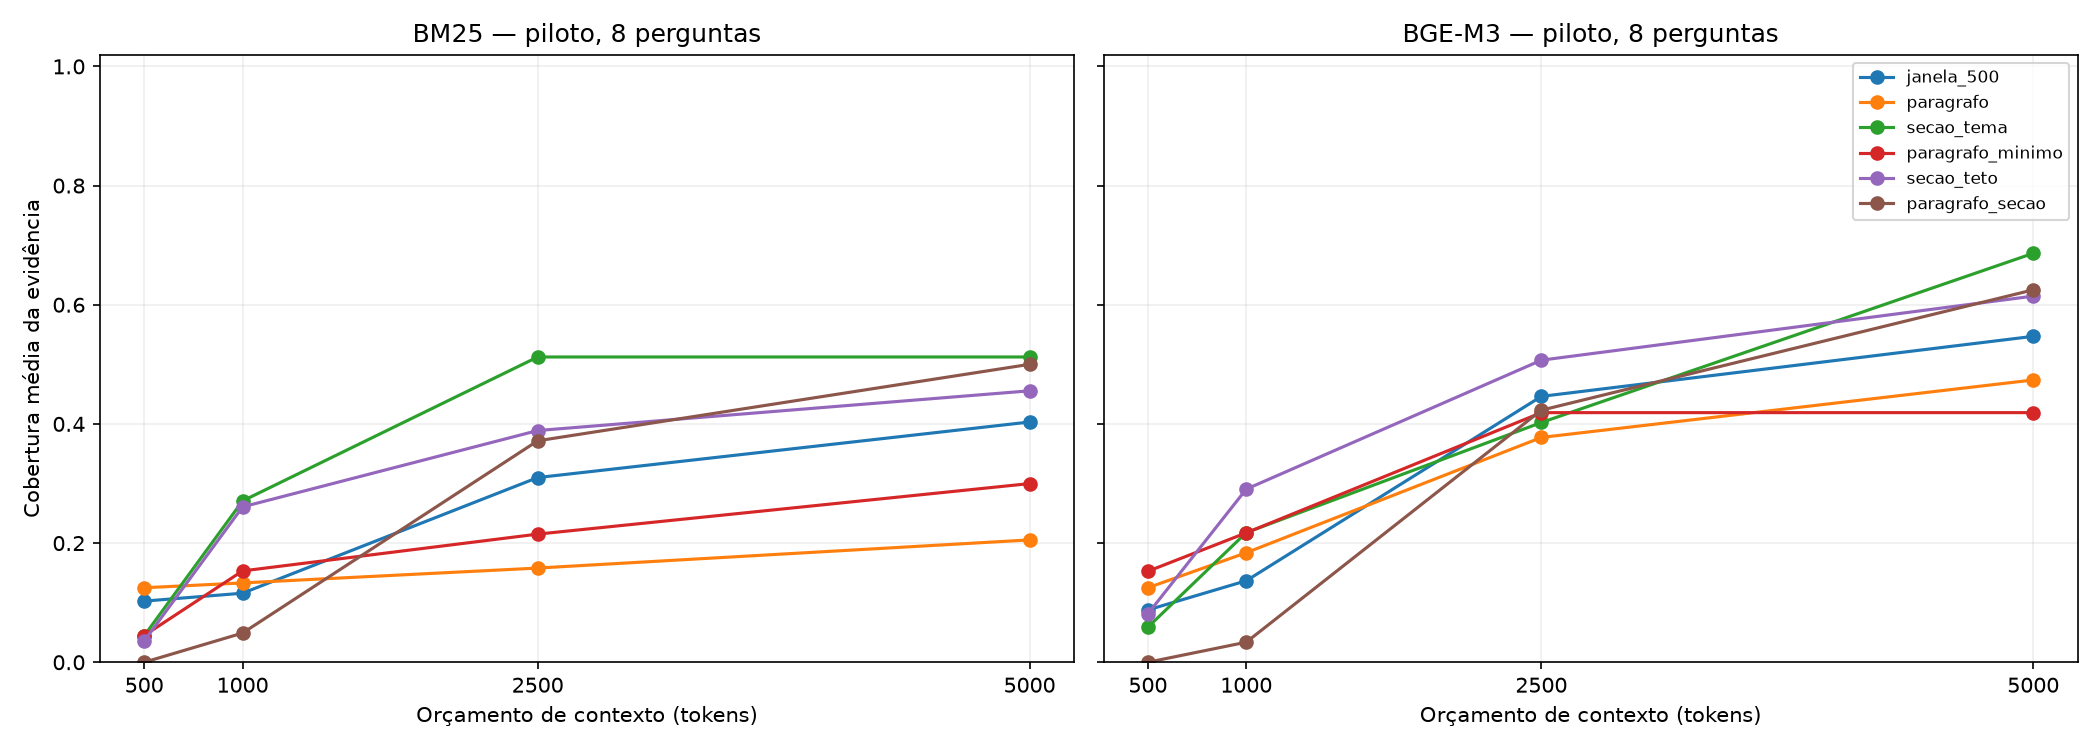

**Diagnóstico:** o maior valor observado foi **51.2%**, com BM25 e `secao_tema`. O melhor BGE (`secao_teto`) contra o melhor BM25 (`secao_tema`) teve 1 vitórias, 5 empates e 2 derrotas; diferença média de -0.5 pontos percentuais, IC bootstrap pareado de 95% [-25.7; 29.8]. O intervalo inclui zero: o piloto não permite declarar uma vantagem consistente entre esses finalistas. Cobertura mede fração dos caracteres da evidência esperada, não taxa de respostas corretas do LLM. Oito perguntas de ajuste, sete documentos de suporte e dois distratores. Amostra enriquecida; não estima a recuperação no corpus integral. Sete perguntas reservadas; nenhuma delas foi buscada, anotada ou codificada nesta etapa.

**Cobertura por pergunta nos dois finalistas observados:**

recuperador,BGE-M3,BM25
query_id,,
juris_001,0.0000,0.0000
juris_002,0.0000,0.0000
juris_003,0.4254,0.4254
juris_004,1.0000,1.0000
juris_005,0.2190,0.6732
juris_019,0.4666,1.0000
juris_020,1.0000,1.0000
juris_023,0.9448,0.0000


**Falha concreta:** juris_001, juris_002 ficaram sem cobertura da evidência esperada nos dois finalistas com 2.500 tokens. Isso impede tratar o maior valor médio como solução suficiente para essas perguntas.

**Expansão de contexto:** recuperar o parágrafo e anexar a seção inteira pode multiplicar o custo. O orçamento corta essa expansão; um acerto de documento ou um trecho narrativo não se transforma automaticamente em suporte do fundamento e do resultado. A tabela seguinte mede esse custo depois da expansão.

**Custo do top 5 após expansão e deduplicação, antes do corte por orçamento:**

,recuperador,versao,mediana,p90,maximo
0,BGE-M3,janela_500,2500.0,2500.0,2500
1,BGE-M3,paragrafo,553.0,753.8,891
2,BGE-M3,paragrafo_minimo,944.0,1202.3,1469
3,BGE-M3,paragrafo_secao,15371.5,34888.5,38553
4,BGE-M3,secao_tema,4983.0,8065.9,8901
5,BGE-M3,secao_teto,1241.0,1898.3,2109
6,BM25,janela_500,2500.0,2500.0,2500
7,BM25,paragrafo,503.5,927.8,981
8,BM25,paragrafo_minimo,996.0,1356.1,1907
9,BM25,paragrafo_secao,13294.5,25480.8,35838


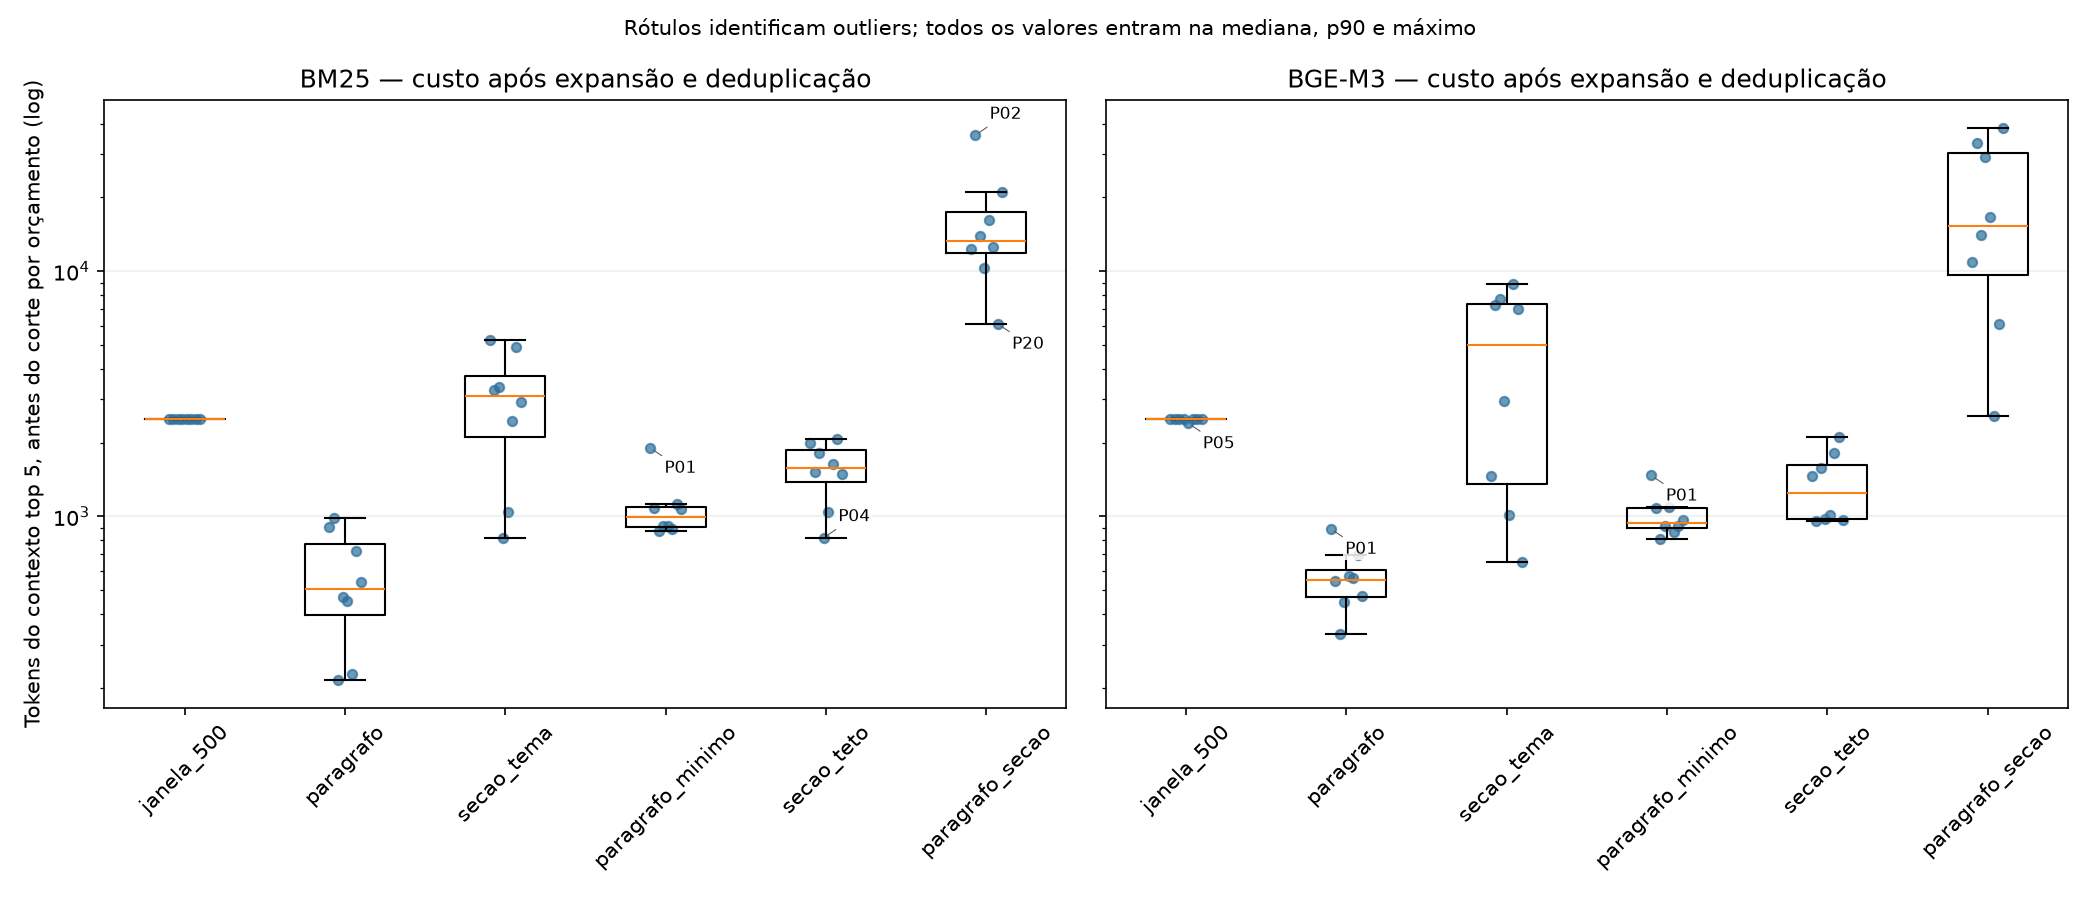

**Perguntas outliers:** Tukey sobre log(1 + tokens), por estratégia e recuperador; os rótulos no gráfico identificam esses pontos. A tabela detalhada liga cada pergunta ao acórdão que mais contribuiu para o custo.

,versao,recuperador,query_id,tokens_indice_top5,tokens_contexto_top5_expandido,segmentos_expandidos,tema,alvo_chunking,acordao_dominante,tokens_documento_dominante,fundamentacao_longa
0,janela_500,BGE-M3,juris_005,2400,2400,5,intervalo intrajornada,dispositivo (condenação),7efe76b7fda67a38bde972d01b1e3496343fe4a99a8221...,2400,False
1,paragrafo,BGE-M3,juris_001,891,891,5,vínculo de emprego,fundamentação longa,add2cf364568dfb927988652f1e12ed56b14269c455a8a...,891,True
2,paragrafo_minimo,BGE-M3,juris_001,1469,1469,5,vínculo de emprego,fundamentação longa,add2cf364568dfb927988652f1e12ed56b14269c455a8a...,1469,True
3,paragrafo_minimo,BM25,juris_001,1907,1907,5,vínculo de emprego,fundamentação longa,add2cf364568dfb927988652f1e12ed56b14269c455a8a...,1907,True
4,paragrafo_secao,BM25,juris_002,981,35838,9,vínculo de emprego (pejotização),fundamentação longa,1ea70dec36a231b4769616bacdd26562e34e16879c0376...,19071,True
5,paragrafo_secao,BM25,juris_020,725,6115,3,insalubridade / perícia,fundamentação + relatório (perícia),27077ec6b641c5505ab36333ac55b96c23db63fa8b00e4...,6115,False
6,secao_teto,BM25,juris_004,818,818,5,jornada (ônus da prova),tese curta / ementa,7efe76b7fda67a38bde972d01b1e3496343fe4a99a8221...,818,False


**Fragmentação, unidades necessárias e perda de evidência no encoder:**

taxa_fragmentacao  ...  perda_media_encoder
recuperador versao                               ...                     
BGE-M3      janela_500                    0.500  ...               0.0002
            paragrafo                     0.875  ...               0.0051
            paragrafo_minimo              0.625  ...               0.0018
            paragrafo_secao               0.875  ...               0.0051
            secao_tema                    0.375  ...               0.0013
            secao_teto                    0.625  ...               0.0015
BM25        janela_500                    0.500  ...                  NaN
            paragrafo                     0.875  ...                  NaN
            paragrafo_minimo              0.625  ...                  NaN
            paragrafo_secao               0.875  ...                  NaN
            secao_tema                    0.375  ...                  NaN
            secao_teto                    0.625  ...                  NaN

[12 rows x 3 columns]

,unidades,unidades_truncadas,maximo_tokens_com_especiais
versao,,,
janela_500,149,0,502
paragrafo,1139,0,1842
paragrafo_minimo,388,0,1846
paragrafo_secao,1139,0,1842
secao_tema,333,0,4176
secao_teto,396,0,502


O BGE recebeu até 8.192 tokens contando especiais. Zero no piloto significa ausência de truncamento neste recorte; os limites de contexto de 500–5.000 continuam cortando o texto entregue. O controle longo separado verifica um truncamento real e não entra nas médias de jurisprudência.

,unidades,acima_512,acima_8192,risco_encoder_512_com_especiais,risco_encoder_8192_com_especiais,fracao_secao_ambigua,fracao_secao_nao_identificada,fracao_tema_ambiguo,fracao_tema_nao_identificado,reconstrucao_texto_base,vetores_planejados,vetores_gerados,versao,vetores_indexados_bge,textos_vetorizados_unicos_bge
0,149,0,0,0,0,NaN,NaN,NaN,NaN,aprovada,149,149,janela_500,149,149
1,1139,5,0,5,0,NaN,NaN,NaN,NaN,aprovada,1139,1042,paragrafo,1139,1042
2,333,26,0,26,0,0.0,0.1682,0.0961,0.4835,aprovada,333,327,secao_tema,333,327
3,388,6,0,6,0,NaN,NaN,NaN,NaN,aprovada,388,383,paragrafo_minimo,388,383
4,396,0,0,0,0,0.0,0.1616,0.0859,0.5278,aprovada,396,390,secao_teto,396,390
5,1139,5,0,5,0,NaN,NaN,NaN,NaN,aprovada,1139,1042,paragrafo_secao,1139,1042


**Comparações pareadas em Cobertura@2500:** bootstrap sobre as mesmas oito perguntas, 2.000 réplicas, seed fixa; análises exploratórias, sem correção para múltiplas comparações.

,a,b,n,vitorias,empates,derrotas,delta_media,ic95_inf,ic95_sup,seed,replicas
11,BGE-M3 / janela_500,BM25 / paragrafo,8,4,4,0,0.2881,0.0817,0.5267,20261114,2000
13,BGE-M3 / janela_500,BM25 / secao_tema,8,0,5,3,-0.0661,-0.1595,0.0000,20261114,2000
15,BGE-M3 / janela_500,BM25 / paragrafo_minimo,8,4,4,0,0.2312,0.0628,0.3995,20261114,2000
17,BGE-M3 / janela_500,BM25 / secao_teto,8,2,5,1,0.0573,-0.0296,0.1881,20261114,2000
19,BGE-M3 / janela_500,BM25 / paragrafo_secao,8,3,4,1,0.0745,-0.0116,0.1775,20261114,2000
30,BGE-M3 / paragrafo,BM25 / secao_tema,8,1,3,4,-0.1350,-0.4444,0.2129,20261114,2000
32,BGE-M3 / paragrafo,BM25 / paragrafo_minimo,8,3,4,1,0.1623,-0.0490,0.4295,20261114,2000
34,BGE-M3 / paragrafo,BM25 / secao_teto,8,2,3,3,-0.0116,-0.2573,0.3130,20261114,2000
36,BGE-M3 / paragrafo,BM25 / paragrafo_secao,8,2,3,3,0.0056,-0.3146,0.3438,20261114,2000
45,BGE-M3 / secao_tema,BM25 / paragrafo_minimo,8,3,5,0,0.1873,0.0274,0.3908,20261114,2000


In [19]:
# Histórico imutável: oito perguntas e nove acórdãos da execução anterior.
# O protocolo atual, com orçamento centrado e varredura, está nas próximas seções.
RELATORIO_PILOTO = piloto_resultados.render(ROOT)


In [20]:
FALHAS_PILOTO = pd.read_csv(RELATORIO_PILOTO / 'diagnostico_falhas.csv')
display(Markdown('**Diagnóstico secundário do top 5 antes da expansão:** acórdão errado, trecho errado e evidência cortada. A curva por orçamento é a avaliação principal.'))
display(FALHAS_PILOTO.groupby(['recuperador','versao']).agg(
    perguntas=('query_id','size'), acordao_errado=('acordao_errado','sum'),
    trecho_errado=('trecho_errado','sum'), fronteira=('evidencia_cortada_na_recuperacao','sum')
))
display(Markdown('A classificação de seção só é avaliada quando existe rótulo esperado explícito; ausência desse rótulo permanece indefinida. Os controles autorais abaixo têm rótulos de fundamento e dispositivo. Os arquivos CSV guardam o diagnóstico por pergunta.'))

**Diagnóstico secundário do top 5 antes da expansão:** acórdão errado, trecho errado e evidência cortada. A curva por orçamento é a avaliação principal.

perguntas  ...  fronteira
recuperador versao                       ...           
BGE-M3      janela_500                8  ...          4
            paragrafo                 8  ...          7
            paragrafo_minimo          8  ...          5
            paragrafo_secao           8  ...          7
            secao_tema                8  ...          3
            secao_teto                8  ...          5
BM25        janela_500                8  ...          4
            paragrafo                 8  ...          7
            paragrafo_minimo          8  ...          5
            paragrafo_secao           8  ...          7
            secao_tema                8  ...          3
            secao_teto                8  ...          5

[12 rows x 4 columns]

A classificação de seção só é avaliada quando existe rótulo esperado explícito; ausência desse rótulo permanece indefinida. Os controles autorais abaixo têm rótulos de fundamento e dispositivo. Os arquivos CSV guardam o diagnóstico por pergunta.

### Controles fictícios ampliados — separados do gabarito real

Os quatro casos iniciais foram ampliados para **12 casos autorais**. Os novos desafios incluem precedente citado em sentido oposto, negação, dois temas com dispositivo parcial, regime temporal, evidências separadas, fronteira da janela, evidência após 8.192 tokens e seção sem título regular. Fundamento e dispositivo são exigidos em conjunto nos oito casos novos: encontrar apenas o relatório ou uma conclusão genérica não cobre toda a evidência.

As médias dos controles são apresentadas separadamente, com BM25. Um ensaio adicional passa o parágrafo longo do caso Lambda pelo BGE-M3 e verifica, por captura da entrada do modelo, quais tokens chegaram ao encoder. É uma verificação de truncamento real em dado fictício, não uma pergunta adicional do teste final nem um resultado real de jurisprudência.

,perguntas,cobertura_media_2500
versao,,
janela_500,12,0.750000
paragrafo,12,0.416433
paragrafo_minimo,12,0.581853
paragrafo_secao,12,0.437958
secao_tema,12,0.581853
secao_teto,12,0.719686


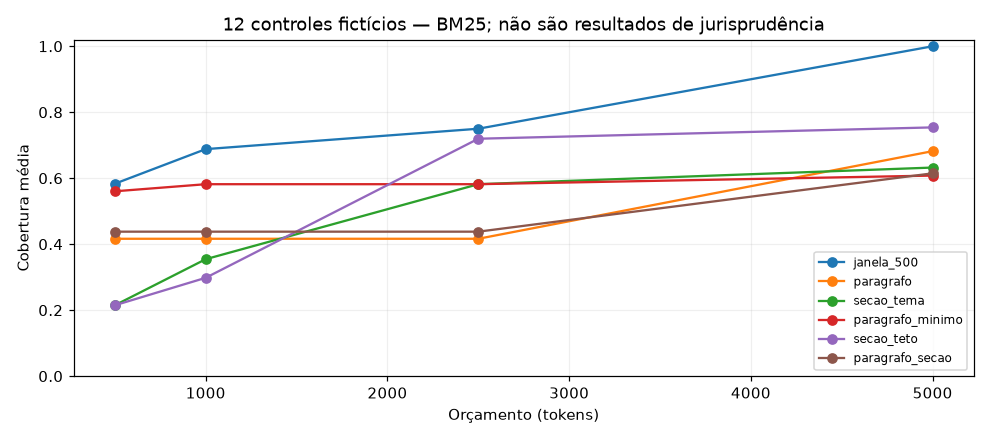

,tokens_com_especiais,tokens_encoder,truncado,inicio_descartado,cobertura_antes,cobertura_apos_encoder,input_ids_reais_conferidos
0,16033,8192,True,41323,0.752747,0.0,True


A cobertura desta linha se refere ao parágrafo longo isolado: o dispositivo está em outra unidade. A perda registra a parte da evidência desse parágrafo que não chegou ao encoder.

In [21]:
CONTROLE_ATIVO = json.loads((ROOT / 'dados/relatorios/jurisprudencia/controles_dificeis/ativa.json').read_text(encoding='utf-8'))
RELATORIO_CONTROLE = ROOT / CONTROLE_ATIVO['pasta_relatorios']
CURVAS_CONTROLE = pd.read_csv(RELATORIO_CONTROLE / 'cobertura.csv')
display(CURVAS_CONTROLE[CURVAS_CONTROLE.orcamento.eq(2500)].groupby('versao').agg(
    perguntas=('query_id','size'), cobertura_media_2500=('cobertura','mean')))
fig, ax = plt.subplots(figsize=(9,4))
for versao, grupo in CURVAS_CONTROLE.groupby('versao', sort=False):
    media = grupo.groupby('orcamento').cobertura.mean()
    ax.plot(media.index, media.values, marker='o', label=versao)
ax.set(xlabel='Orçamento (tokens)', ylabel='Cobertura média', ylim=(0,1.02),
       title='12 controles fictícios — BM25; não são resultados de jurisprudência')
ax.legend(fontsize=8); ax.grid(alpha=.2); fig.tight_layout(); plt.show()
ENCODER_CONTROLE = json.loads((ROOT / 'dados/relatorios/jurisprudencia/controles_dificeis/encoder_real/resultado.json').read_text(encoding='utf-8'))
assert ENCODER_CONTROLE['input_ids_reais_conferidos'] and ENCODER_CONTROLE['truncado']
display(pd.DataFrame([{k: ENCODER_CONTROLE[k] for k in (
    'tokens_com_especiais','tokens_encoder','truncado','inicio_descartado',
    'cobertura_antes','cobertura_apos_encoder','input_ids_reais_conferidos')}]))
display(Markdown('A cobertura desta linha se refere ao parágrafo longo isolado: o dispositivo está em outra unidade. A perda registra a parte da evidência desse parágrafo que não chegou ao encoder.'))

In [22]:
CONFIG_PILOTO = json.loads((RELATORIO_PILOTO / 'configuracao.json').read_text(encoding='utf-8'))
RESERVA_CONFERIDA = piloto_bge.freeze_guard(ROOT, QUERIES_HISTORICAS)
assert len(RESERVA_CONFERIDA) == 7
assert not set(CONFIG_PILOTO['perguntas_avaliadas']) & RESERVA_CONFERIDA
assert CONFIG_PILOTO['teste_final_executado'] is False
assert CONFIG_PILOTO['teste_final_executado'] is False  # Estado desta execução histórica
print('Registro histórico: esta execução avaliou somente ajuste. O teste final é uma etapa posterior separada.')
import subprocess
TESTES_PILOTO = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', str(ROOT / 'tests'),
    '-p', 'test_jurisprudencia_piloto_bge.py'], cwd=ROOT, capture_output=True, text=True)
print(TESTES_PILOTO.stdout + TESTES_PILOTO.stderr)
assert TESTES_PILOTO.returncode == 0

Registro histórico: esta execução avaliou somente ajuste. O teste final é uma etapa posterior separada.
......
----------------------------------------------------------------------
Ran 6 tests in 0.007s

OK



> **Fotografia de ajuste anterior:** esta seção preserva a primeira versão dos 17 gabaritos e seus resultados. As ementas próprias equivalentes de P01/P02/P23 foram acrescentadas no ajuste seguinte. A comparação atual das finalistas e o teste reservado estão nas seções posteriores; os valores antigos não são misturados com o gabarito atualizado.

## Protocolo atual — orçamento centrado, varredura e diagnóstico por pergunta

**Esta é a comparação atual de ajuste.** São executadas buscas BM25 e BGE-M3 para as **23 perguntas de ajuste**, mantendo as **sete perguntas de teste congeladas**. O gabarito por intervalo foi ampliado de oito para **17 perguntas**, incluindo nove novos casos de rescisão indireta, FGTS, gravidez, acidente de trabalho, discriminação, revistas, terceirização, honorários e retaliação. As três perguntas de ajuste ainda sem intervalo e os três controles comportamentais têm suas buscas registradas, mas não recebem uma nota de suporte inventada.

Os dois recuperadores usam o mesmo corpus versionado de **18 acórdãos**. O ranking disponível é percorrido até preencher o orçamento de **500, 1.000, 2.500 ou 5.000 tokens**, com deduplicação de intervalos e corte da última unidade. **Cinco resultados não são um limite para montar o contexto.** Documento@1/@5/@10 aparecem apenas como diagnóstico secundário.

Na expansão, o recorte é **centrado no parágrafo recuperado**, usando sua posição no documento; ele não começa arbitrariamente no início da seção e não usa o intervalo do gabarito para escolher a janela. A variante `paragrafo_secao` fica dentro da seção e do orçamento. Acrescentam-se sete variantes `paragrafo_janela`, com tetos de **256, 500, 512, 1.000, 1.024, 2.500 e 5.000 tokens**. Esses tamanhos retomam os limites dos experimentos anteriores e os orçamentos de contexto. Janelas consecutivas sobrepostas não contam o mesmo texto duas vezes.

São **seis formas de indexação** e **13 configurações de recuperação/montagem de contexto**. As sete janelas reutilizam os vetores dos parágrafos; não requerem sete novos conjuntos de embeddings. O texto jurídico original protegido e seus offsets são preservados.

In [23]:
from pathlib import Path
import sys, json, subprocess
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/jurisprudencia').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from worker.ingestao.jurisprudencia import audit, piloto_bge, perguntas_csv
from worker.ingestao.jurisprudencia import chunking_suporte as suporte_piloto
import pyarrow.parquet as pq
QUERIES_ATUAIS, _ = perguntas_csv.load(ROOT)
from worker.ingestao.jurisprudencia import experimento_orcamento, relatorio_orcamento
RELATORIO_ATUAL, DADOS_ATUAIS = relatorio_orcamento.locate(ROOT)
CONFIG_ATUAL = json.loads((RELATORIO_ATUAL / 'configuracao.json').read_text(encoding='utf-8'))
GABARITO_ATUAL = [json.loads(linha) for linha in (RELATORIO_ATUAL / 'gabarito_snapshot.jsonl').read_text(encoding='utf-8').splitlines() if linha.strip()]
RESERVA_ATUAL = piloto_bge.freeze_guard(ROOT, QUERIES_ATUAIS)
assert CONFIG_ATUAL['gabarito_sha256'] == audit.hash_file(RELATORIO_ATUAL / 'gabarito_snapshot.jsonl')
assert not set(CONFIG_ATUAL['consultas_executadas']) & RESERVA_ATUAL
DOCS_ATUAIS = {d['registro_id']: dict(d, texto_principal_campo=d['campo_texto']) for d in pq.read_table(DADOS_ATUAIS / 'documentos_base.parquet').to_pylist()}
suporte_piloto.validate_questions(GABARITO_ATUAL, DOCS_ATUAIS)
display(pd.DataFrame([{'consultas_ajuste_executadas':len(CONFIG_ATUAL['consultas_executadas']),
    'perguntas_com_intervalos':len(GABARITO_ATUAL),'perguntas_reservadas':len(RESERVA_ATUAL),
    'acordaos_mesmo_corpus':len(CONFIG_ATUAL['documentos']),'configuracoes':len(CONFIG_ATUAL['variantes'])}]))
display(pd.DataFrame([{'query_id':q['query_id'],'intervalos':sum(map(len,q['alternativas_suporte'])),
    'resposta_esperada_circunscrita_ao_acordao':q['resposta_esperada']} for q in GABARITO_ATUAL]))

,consultas_ajuste_executadas,perguntas_com_intervalos,perguntas_reservadas,acordaos_mesmo_corpus,configuracoes
0,23,17,7,18,13


,query_id,intervalos,resposta_esperada_circunscrita_ao_acordao
0,juris_001,2,"Neste acórdão da Segunda Turma do TST, os requ..."
1,juris_002,1,"No julgamento de 2020, o TST manteve o vínculo..."
2,juris_003,2,O TRT17 utilizou depoimentos e circunstâncias ...
3,juris_004,1,"Neste caso, a apresentação incompleta de contr..."
4,juris_005,2,"Neste acórdão, o TRT17 entendeu inaplicáveis a..."
5,juris_010,2,O TRT17 reconheceu rescisão indireta diante do...
6,juris_011,2,A Sétima Turma do TST aplicou o Tema 70 e reco...
7,juris_012,1,O TRT17 manteve a estabilidade da gestante por...
8,juris_013,2,O TRT17 tratou da garantia de emprego decorren...
9,juris_014,2,O TRT17 admitiu a possibilidade de discriminaç...


### Como ler os resultados e os diagnósticos

A métrica principal é **Cobertura@T**, resumida por Cobertura@2500. O bootstrap é **pareado por pergunta**, com 2.000 réplicas e seed fixa; vitórias, empates e derrotas usam a diferença de cobertura na mesma pergunta. A coorte das **oito perguntas originais** é apresentada separadamente da coorte ampliada de **17 perguntas**. A escolha do tamanho da janela ainda pertence ao ajuste, sem usar as sete perguntas reservadas e sem declarar um vencedor definitivo pela maior média.

Cada uma das oito perguntas originais tem uma tabela com todas as configurações: cobertura, acerto de documento, posição do primeiro documento esperado, fragmentação, perda potencial de evidência no encoder e explicação da falha. Os CSVs também conservam o diagnóstico das 17 perguntas, os offsets dos trechos realmente entregues e os controles de orçamento. Encontrar o acórdão não equivale a encontrar o fundamento que sustenta a resposta.

Para seção/tema, registramos separadamente: **unidade acima de 8.192 tokens**, **corte real pelo encoder incluindo tokens especiais**, **acerto apoiado em uma unidade que sofreu truncamento** e **evidência entregue que estava além do prefixo codificado**. Uma ablação remove as unidades truncadas e refaz o preenchimento do orçamento. A auditoria ampla codifica também as **sete seções longas do corpus maior**, sem confundir essa auditoria com a avaliação de recuperação no piloto de 18 acórdãos.

Para reproduzir a etapa atual, execute `scripts/run_chunking_orcamento_centrado.py` e depois `relatorio_orcamento.finalize(ROOT)`. O BGE-M3 usa CPU e cache local por hash de texto e snapshot. Não há LLM na seleção de fronteiras, expansão ou montagem do contexto.

,query_id,pergunta,status
0,juris_001,"Trabalho de motorista de aplicativo todo dia, ...",com_intervalos_e_metricas
1,juris_002,"Fui contratado como PJ, mas tenho horário fixo...",com_intervalos_e_metricas
2,juris_003,Trabalhei dois anos sem carteira assinada. Com...,com_intervalos_e_metricas
3,juris_004,Meu patrão não fazia controle de ponto. Quem p...,com_intervalos_e_metricas
4,juris_005,Eu fazia só 30 minutos de almoço em vez de 1 h...,com_intervalos_e_metricas
5,juris_006,Trabalho em home office e respondo mensagens d...,buscas_executadas_sem_intervalo_anotado
6,juris_007,O banco de horas combinado só de boca vale? Se...,buscas_executadas_sem_intervalo_anotado
7,juris_010,Meu salário atrasa há meses. Posso pedir resci...,com_intervalos_e_metricas
8,juris_011,O TST já decidiu que a falta de depósito do FG...,com_intervalos_e_metricas
9,juris_012,Fui demitida grávida e só descobri a gravidez ...,com_intervalos_e_metricas


,recuperador,versao,cobertura_2500,perguntas,tokens_medios
0,BGE-M3,janela_500,0.5677,17,2500.0
1,BGE-M3,paragrafo,0.3228,17,2500.0
2,BGE-M3,paragrafo_janela_1000,0.3680,17,2500.0
3,BGE-M3,paragrafo_janela_1024,0.3706,17,2500.0
4,BGE-M3,paragrafo_janela_2500,0.4151,17,2500.0
5,BGE-M3,paragrafo_janela_256,0.4892,17,2500.0
6,BGE-M3,paragrafo_janela_500,0.5274,17,2500.0
7,BGE-M3,paragrafo_janela_5000,0.4151,17,2500.0
8,BGE-M3,paragrafo_janela_512,0.5265,17,2500.0
9,BGE-M3,paragrafo_minimo,0.4845,17,2500.0


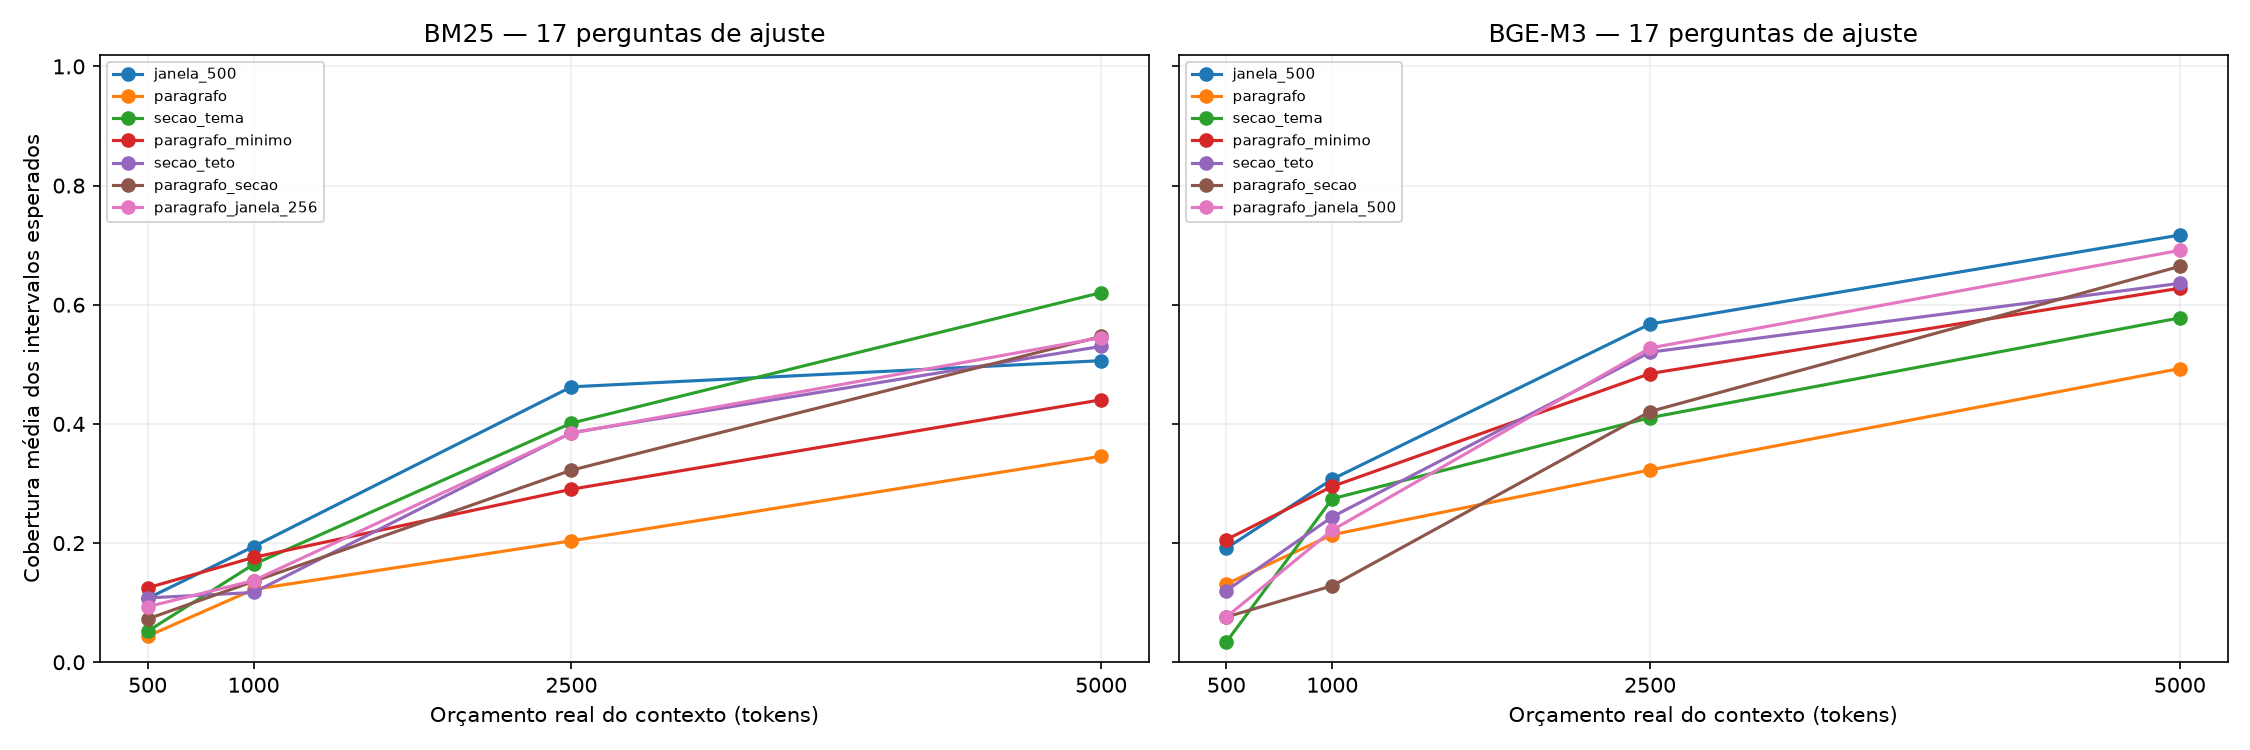

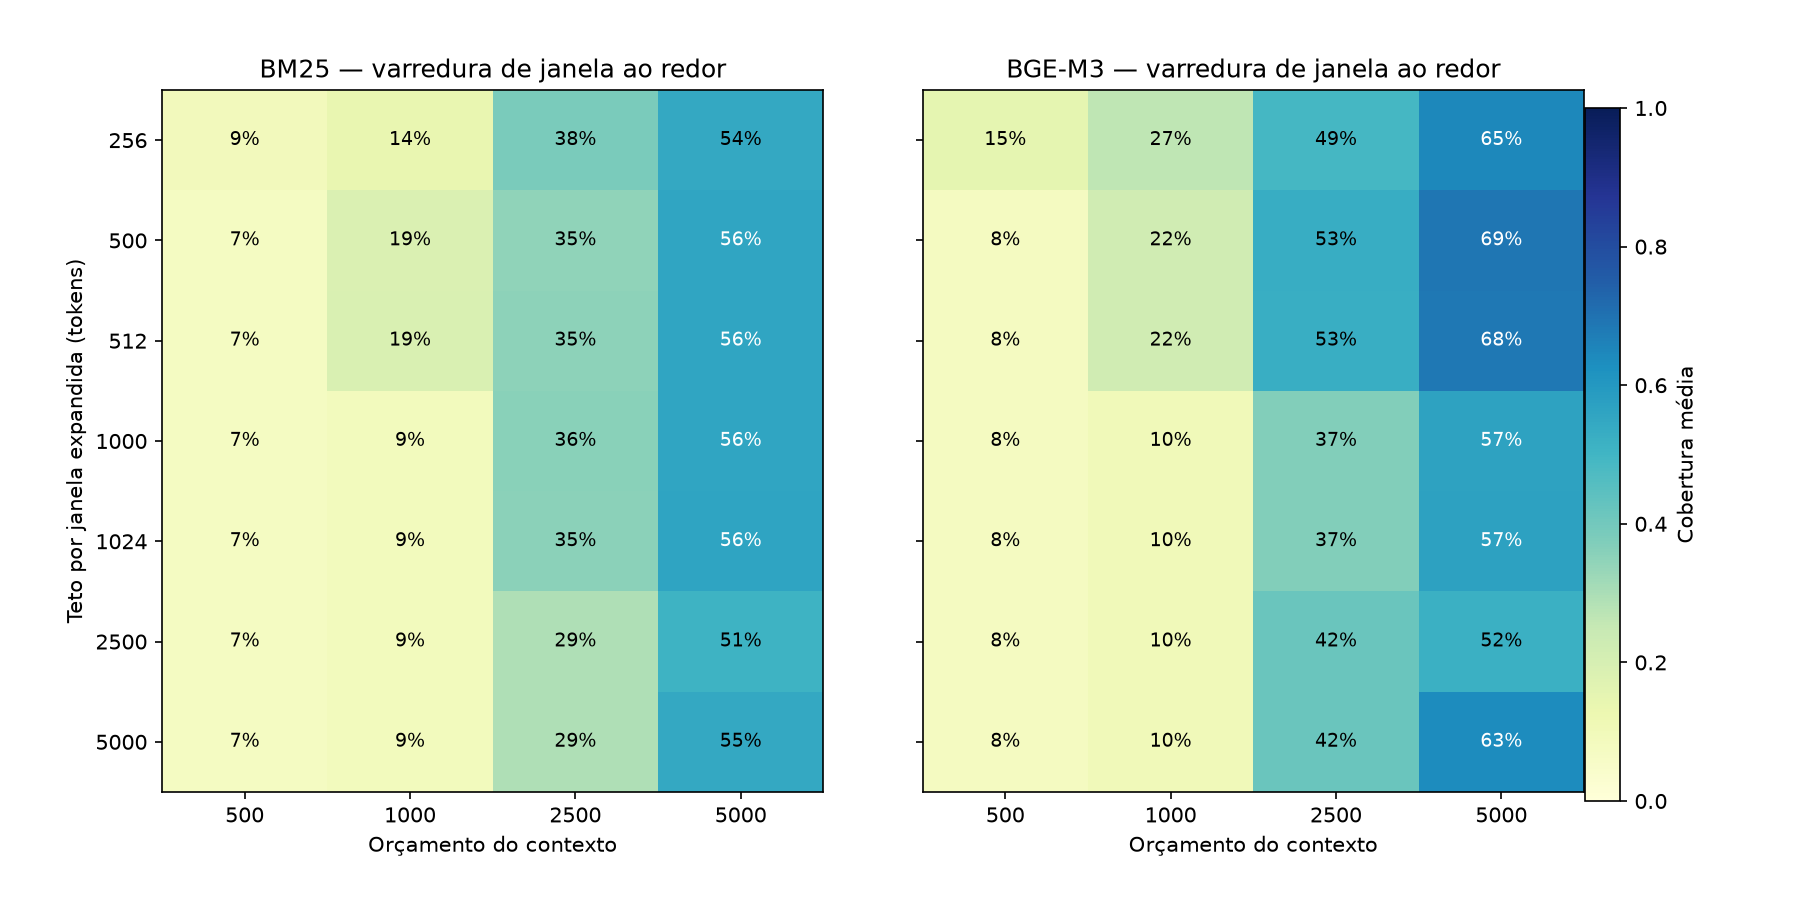

**Leitura do ajuste:** melhor BM25 observado: `janela_500`, 46.2%; melhor BGE-M3: `janela_500`, 56.8%. BGE contra BM25: 4 vitórias, 11 empates e 2 derrotas; diferença média 10.5 p.p., IC bootstrap 95% [-4.9; 27.5]. O intervalo inclui zero; a média não decide sozinha. Varridos e comparados no ajuste, não no teste final. Melhores valores observados não provam superioridade geral; bootstrap exploratório sem correção para múltiplas comparações. Perguntas gerais podem admitir outros trechos válidos: a cobertura mede as referências anotadas, não a exaustividade jurídica do corpus. Cobertura mede evidência recuperada, não respostas geradas por LLM.

**Custo depois da expansão e do corte:** a tabela contabiliza o contexto entregue e o número de unidades distintas. Soma fixa de cinco resultados não é o critério principal.

,recuperador,versao,orcamento,tokens_mediana,tokens_p90,tokens_max,unidades_mediana,unidades_p90,unidades_max
2,BGE-M3,janela_500,2500,2500.0,2500.0,2500,5.0,6.0,6
6,BGE-M3,paragrafo,2500,2500.0,2500.0,2500,18.0,24.8,28
10,BGE-M3,paragrafo_janela_1000,2500,2500.0,2500.0,2500,3.0,4.0,5
14,BGE-M3,paragrafo_janela_1024,2500,2500.0,2500.0,2500,3.0,4.0,5
18,BGE-M3,paragrafo_janela_2500,2500,2500.0,2500.0,2500,1.0,2.0,2
22,BGE-M3,paragrafo_janela_256,2500,2500.0,2500.0,2500,11.0,12.8,16
26,BGE-M3,paragrafo_janela_500,2500,2500.0,2500.0,2500,6.0,8.0,11
30,BGE-M3,paragrafo_janela_5000,2500,2500.0,2500.0,2500,1.0,2.0,2
34,BGE-M3,paragrafo_janela_512,2500,2500.0,2500.0,2500,6.0,8.0,11
38,BGE-M3,paragrafo_minimo,2500,2500.0,2500.0,2500,11.0,14.8,15


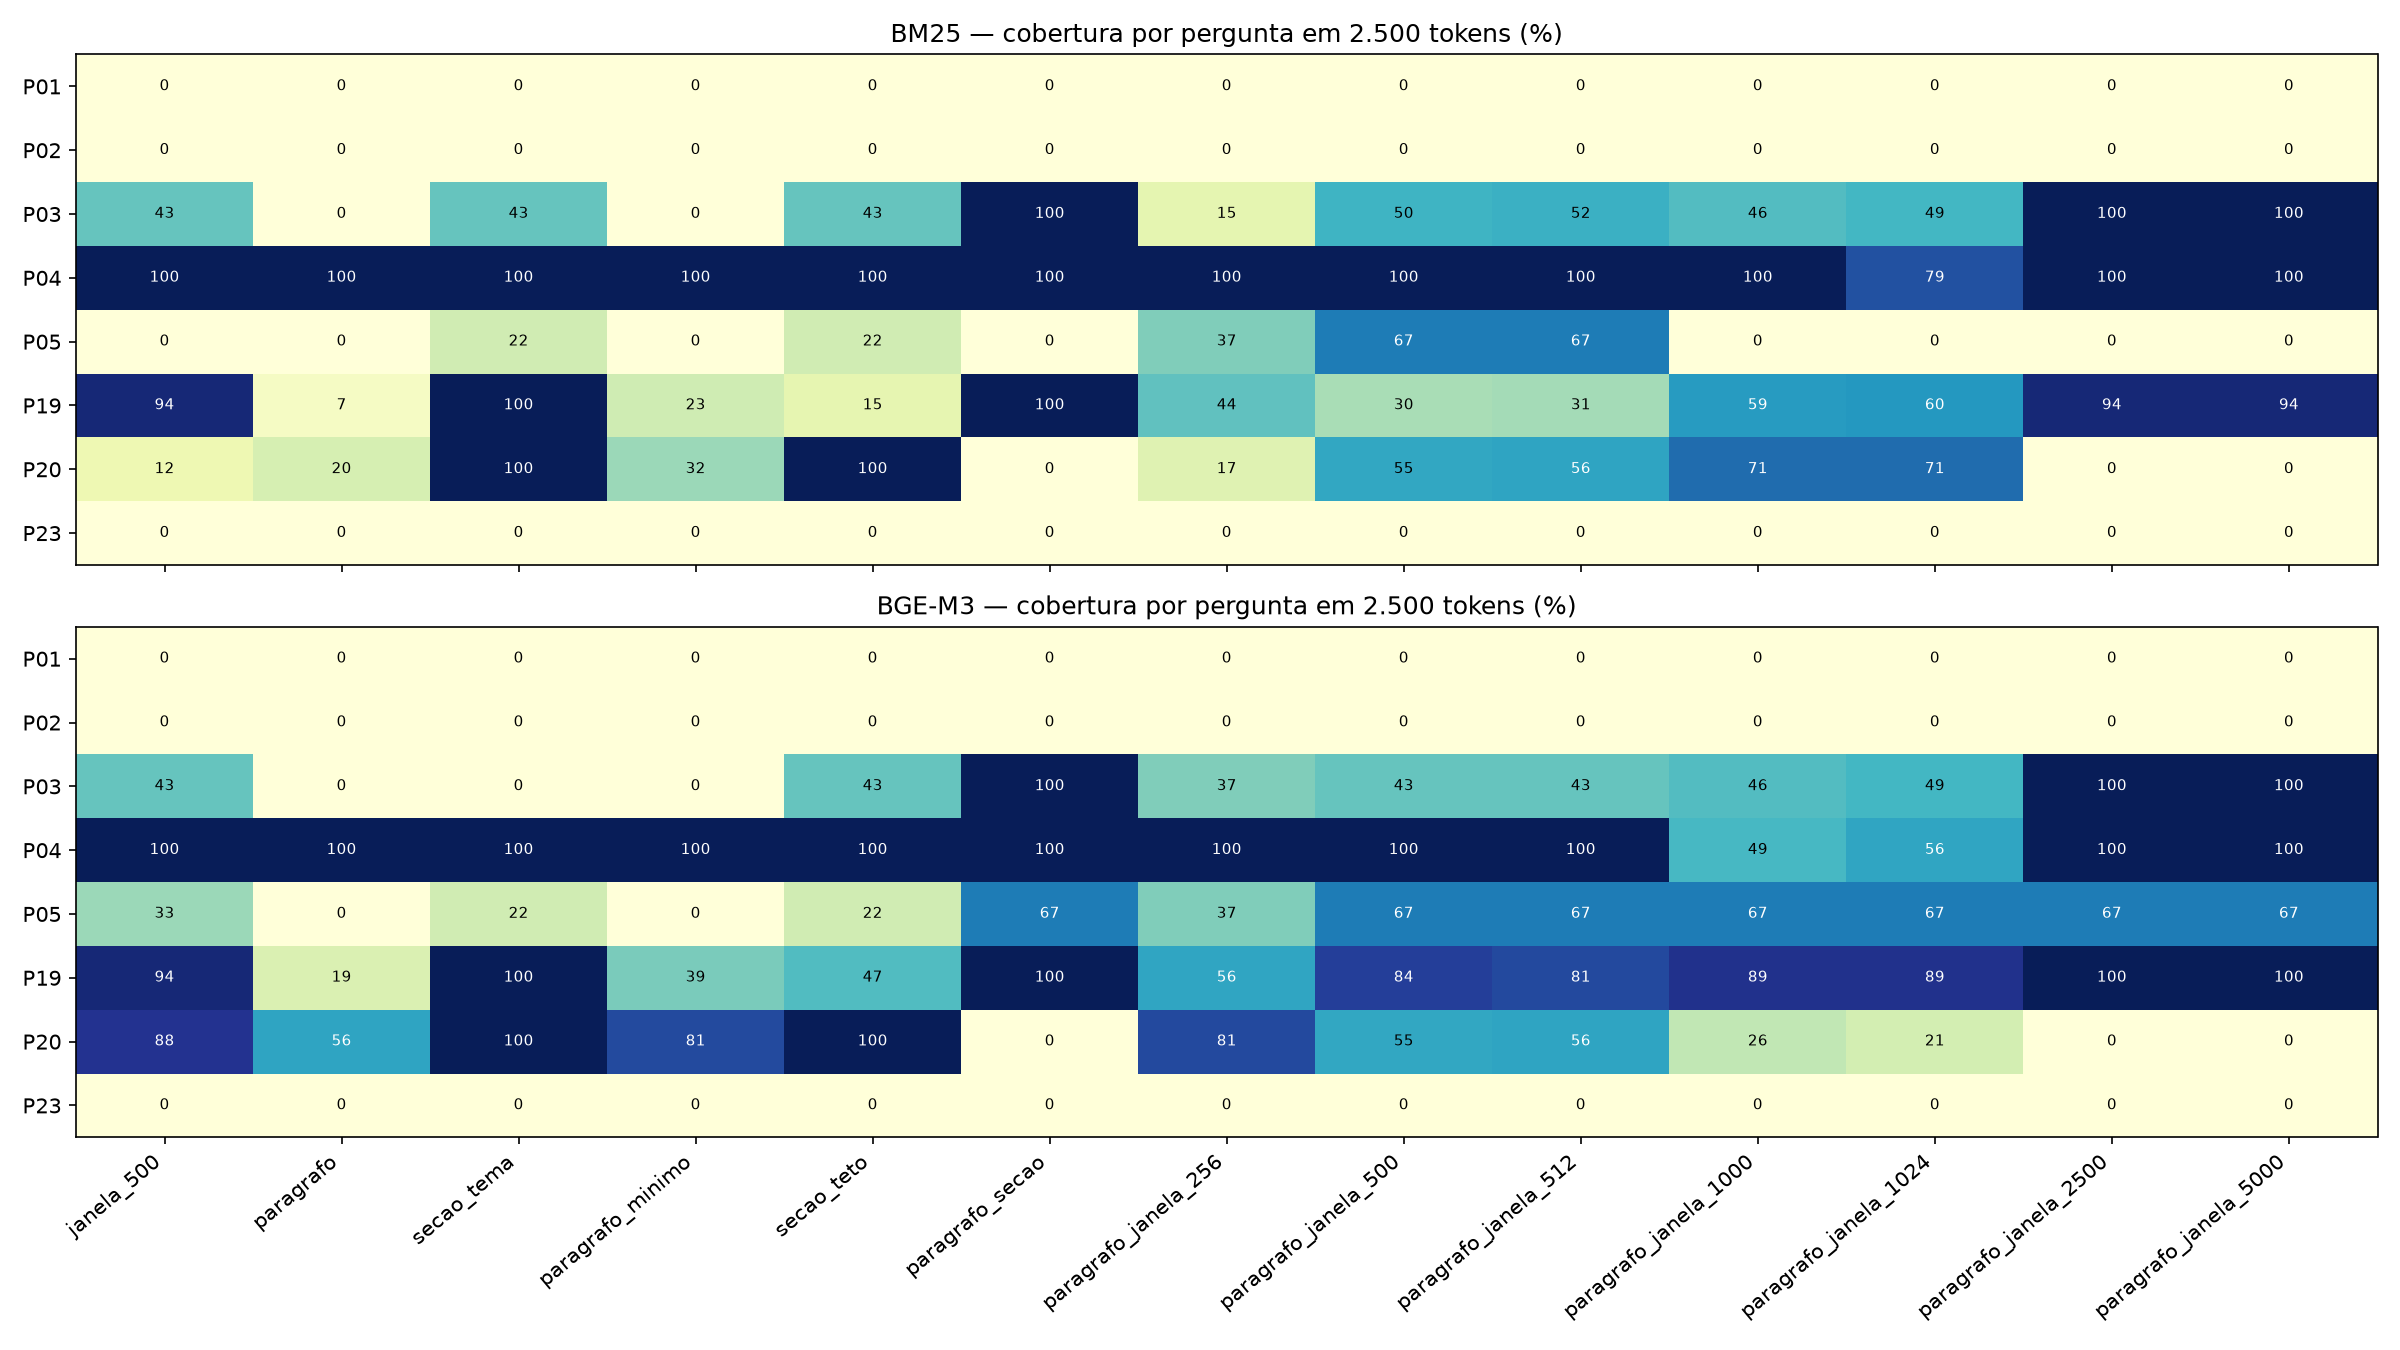

**juris_001 — Trabalho de motorista de aplicativo todo dia, com meta e punição se eu recusar corrida. Dá para pedir vínculo de emprego?**

,recuperador,versao,cobertura,documento_5,primeiro_rank_documento,unidades_minimas,perda_evidencia_encoder,explicacao
0,BM25,janela_500,0.0,True,1,1,NaN,"documento correto no contexto, mas trechos sem..."
17,BGE-M3,janela_500,0.0,True,1,1,0.0,"documento correto no contexto, mas trechos sem..."
34,BM25,paragrafo,0.0,True,1,6,NaN,"documento correto no contexto, mas trechos sem..."
51,BGE-M3,paragrafo,0.0,True,1,6,0.0,"documento correto no contexto, mas trechos sem..."
68,BM25,secao_tema,0.0,True,1,2,NaN,"documento correto no contexto, mas trechos sem..."
85,BGE-M3,secao_tema,0.0,True,1,2,0.0,"documento correto no contexto, mas trechos sem..."
102,BM25,paragrafo_minimo,0.0,True,1,2,NaN,"documento correto no contexto, mas trechos sem..."
119,BGE-M3,paragrafo_minimo,0.0,True,1,2,0.0,"documento correto no contexto, mas trechos sem..."
136,BM25,secao_teto,0.0,True,1,2,NaN,"documento correto no contexto, mas trechos sem..."
153,BGE-M3,secao_teto,0.0,True,1,2,0.0,"documento correto no contexto, mas trechos sem..."


**juris_002 — Fui contratado como PJ, mas tenho horário fixo e um chefe que manda em mim. A justiça reconhece vínculo?**

,recuperador,versao,cobertura,documento_5,primeiro_rank_documento,unidades_minimas,perda_evidencia_encoder,explicacao
1,BM25,janela_500,0.0,False,12,2,NaN,documento esperado não chegou ao contexto dent...
18,BGE-M3,janela_500,0.0,False,10,2,0.0,documento esperado não chegou ao contexto dent...
35,BM25,paragrafo,0.0,False,13,10,NaN,"documento correto no contexto, mas trechos sem..."
52,BGE-M3,paragrafo,0.0,True,1,10,0.0,"documento correto no contexto, mas trechos sem..."
69,BM25,secao_tema,0.0,False,15,1,NaN,documento esperado não chegou ao contexto dent...
86,BGE-M3,secao_tema,0.0,True,4,1,0.0,"documento correto no contexto, mas trechos sem..."
103,BM25,paragrafo_minimo,0.0,False,12,4,NaN,documento esperado não chegou ao contexto dent...
120,BGE-M3,paragrafo_minimo,0.0,False,9,4,0.0,documento esperado não chegou ao contexto dent...
137,BM25,secao_teto,0.0,False,8,2,NaN,"documento correto no contexto, mas trechos sem..."
154,BGE-M3,secao_teto,0.0,False,21,2,0.0,documento esperado não chegou ao contexto dent...


**juris_003 — Trabalhei dois anos sem carteira assinada. Como eu provo que era empregado?**

,recuperador,versao,cobertura,documento_5,primeiro_rank_documento,unidades_minimas,perda_evidencia_encoder,explicacao
2,BM25,janela_500,0.4254,True,1,3,NaN,cobertura parcial dos intervalos esperados; um...
19,BGE-M3,janela_500,0.4254,True,1,3,0.0,cobertura parcial dos intervalos esperados; um...
36,BM25,paragrafo,0.0000,True,1,4,NaN,"documento correto no contexto, mas trechos sem..."
53,BGE-M3,paragrafo,0.0000,True,1,4,0.0,"documento correto no contexto, mas trechos sem..."
70,BM25,secao_tema,0.4254,True,1,2,NaN,cobertura parcial dos intervalos esperados; ho...
87,BGE-M3,secao_tema,0.0000,True,1,2,0.0,"documento correto no contexto, mas trechos sem..."
104,BM25,paragrafo_minimo,0.0000,True,1,2,NaN,"documento correto no contexto, mas trechos sem..."
121,BGE-M3,paragrafo_minimo,0.0000,True,1,2,0.0,"documento correto no contexto, mas trechos sem..."
138,BM25,secao_teto,0.4254,True,1,2,NaN,cobertura parcial dos intervalos esperados; ho...
155,BGE-M3,secao_teto,0.4254,True,1,2,0.0,cobertura parcial dos intervalos esperados


... (14 outputs left out)

,unidades,acima_8192_sem_especiais,truncadas_encoder,maximo_tokens
escopo,,,,
auditoria_ampla_secoes_longas,7,7,7,34036
piloto_secao_tema,531,0,0,4176


,query_id,cobertura,cobertura_sem_unidades_truncadas,delta_remocao,evidencia_em_unidades_truncadas,evidencia_entregue_fora_prefixo_encoder
2,juris_001,0.0000,0.0000,0.0,0.0,0.0
6,juris_002,0.0000,0.0000,0.0,0.0,0.0
10,juris_003,0.0000,0.0000,0.0,0.0,0.0
14,juris_004,1.0000,1.0000,0.0,0.0,0.0
18,juris_005,0.2190,0.2190,0.0,0.0,0.0
22,juris_010,0.4792,0.4792,0.0,0.0,0.0
26,juris_011,0.5802,0.5802,0.0,0.0,0.0
30,juris_012,0.0000,0.0000,0.0,0.0,0.0
34,juris_013,0.0000,0.0000,0.0,0.0,0.0
38,juris_014,1.0000,1.0000,0.0,0.0,0.0


A ablação refaz o preenchimento do orçamento após retirar unidades truncadas. Ela separa depender da unidade longa de depender do conteúdo que o encoder descartou. A auditoria ampla codifica as sete seções longas do corpus maior; os contrafactuais de recuperação se referem ao corpus idêntico do piloto. Não se atribui a essas seções uma vantagem em perguntas para as quais não participaram da busca.

**Reserva:** sete perguntas continuam congeladas. As 23 consultas executadas são somente de ajuste; três controles comportamentais e três perguntas ainda sem intervalo não recebem nota de suporte.

In [24]:
# Resultados da execução efetiva; habilite para repetir usando o cache local.
EXECUTAR_PROTOCOLO_ATUAL = False
if EXECUTAR_PROTOCOLO_ATUAL:
    experimento_orcamento.run(ROOT)
    relatorio_orcamento.finalize(ROOT)
RELATORIO_ATUAL = relatorio_orcamento.render(ROOT)

In [25]:
TESTES_CONTEXTO = subprocess.run([sys.executable,'-m','unittest','discover','-s',str(ROOT/'tests'),
    '-p','test_contexto_centrado.py'],cwd=ROOT,capture_output=True,text=True)
print(TESTES_CONTEXTO.stdout + TESTES_CONTEXTO.stderr)
assert TESTES_CONTEXTO.returncode == 0
CONFIG_ATUAL = json.loads((RELATORIO_ATUAL/'configuracao.json').read_text(encoding='utf-8'))
assert len(piloto_bge.freeze_guard(ROOT, QUERIES_ATUAIS)) == 7
assert len(CONFIG_ATUAL['consultas_executadas']) == 23
assert len(CONFIG_ATUAL['perguntas_com_evidencia']) == 17
assert not CONFIG_ATUAL['teste_final_executado']
assert CONFIG_ATUAL['teste_final_executado'] is False  # Estado deste ajuste histórico
print('Registro histórico conferido: 23 consultas de ajuste e 17 gabaritos; o teste reservado é uma etapa posterior.')

..........
----------------------------------------------------------------------
Ran 10 tests in 0.002s

OK

Registro histórico conferido: 23 consultas de ajuste e 17 gabaritos; o teste reservado é uma etapa posterior.


## Seleção das finalistas — diagnóstico e grade equilibrada

Esta etapa compara **sete configurações por família**, sobre o mesmo corpus versionado de **18 acórdãos** e as mesmas **17 perguntas com gabarito de ajuste**. As 23 perguntas de ajuste têm buscas registradas; perguntas sem referência de suporte não recebem nota inventada.

Para a janela fixa, a grade escolhida é: **256, 500, 1.000, 2.500 e 5.000 tokens sem sobreposição**, e **500 tokens com 50 ou 100 tokens de sobreposição** (10% ou 20%). A outra família mantém os sete tetos já testados para parágrafo + janela ao redor. O custo é comparado pelo contexto efetivamente entregue, com T = 500/1.000/2.500/5.000 tokens, descontando duplicações. A maior janela pode ser cortada pelo orçamento; seu tamanho não dá contexto gratuito.

P01, P02 e P23 receberam diagnóstico de documento, trecho e posição da evidência. O controle com ordenação ideal mostra se os chunks conseguem sustentar a resposta quando a evidência é priorizada; ele **não participa do ranking real**. O gabarito foi complementado com ementas próprias equivalentes, sem confundir alegações, decisão reformada e precedentes citados com o resultado do julgamento. As métricas das duas famílias foram recalculadas com esse mesmo gabarito antes de selecionar as finalistas.

Seleciona-se uma configuração de cada família pelo maior **Cobertura@2500 com BGE-M3** no ajuste. Em empate, considera-se o menor número de vetores e um desempate estável pelo nome. O bootstrap é pareado por pergunta, com 2.000 réplicas e seed fixa. Essa seleção pertence ao ajuste; a reserva não participa dela.

**Diagnóstico de P01, P02 e P23 — janela fixa de 500 sem sobreposição:**

,query_id,documento_rank,primeiro_trecho_evidencia_rank,cobertura_real_2500,cobertura_oraculo_2500
0,juris_001,1,21,0.0,1.0
1,juris_002,10,12,0.0,1.0
2,juris_023,1,40,0.0,1.0


P01 recuperou argumentos da empresa e decisão anterior reformada. P02 priorizou documentos sobre outras relações de emprego. P23 recuperou, entre outros trechos, um precedente de outro processo citado no acórdão. O gabarito considera fundamento/resultado próprios e ementas próprias equivalentes; o oráculo diagnóstico usa o gabarito apenas para estimar a cobertura alcançável, sem entrar na busca real.

**Cautela específica em P23:** o primeiro trecho já expressa a regra de dois anos em um precedente citado e pode ser útil para uma pergunta geral sobre prazo. Zero nos intervalos escolhidos não demonstra resposta jurídica errada. Esta métrica mede recuperação das referências anotadas; não é um gabarito exaustivo de toda passagem juridicamente válida nem uma avaliação de respostas geradas.

,query_id,recuperador,versao,primeiro_rank_documento,primeiro_rank_evidencia,documento_no_contexto,cobertura_2500,cortes_contexto,limite_encoder_real,encoder_truncou_alguma_unidade
0,juris_001,BM25,fixa_256_o0,1,13,True,0.0,1,8192,False
1,juris_002,BM25,fixa_256_o0,12,12,False,0.0,1,8192,False
2,juris_023,BM25,fixa_256_o0,55,151,False,0.0,1,8192,False
3,juris_001,BGE-M3,fixa_256_o0,1,34,True,0.0,1,8192,False
4,juris_002,BGE-M3,fixa_256_o0,5,29,True,0.0,1,8192,False
...,...,...,...,...,...,...,...,...,...,...
79,juris_002,BM25,paragrafo_janela_5000,13,41,False,0.0,1,8192,False
80,juris_023,BM25,paragrafo_janela_5000,26,177,False,0.0,2,8192,False
81,juris_001,BGE-M3,paragrafo_janela_5000,1,40,True,0.0,1,8192,False
82,juris_002,BGE-M3,paragrafo_janela_5000,1,36,True,0.0,2,8192,False


**Comparação equilibrada: sete configurações por família, mesmo corpus de 18 documentos e mesmo orçamento.**

,versao,tamanho_alvo,sobreposicao_alvo,vetores_indice,textos_unicos,tokens_maximo,sobreposicao_mediana,sobreposicao_p90,sobreposicao_maxima,reconstrucao_por_uniao,razao_caracteres_indexados
0,fixa_256_o0,256,0,479,479,256,0.0,0.0,0,aprovada,1.000
1,fixa_500_o0,500,0,249,249,500,0.0,0.0,0,aprovada,1.000
2,fixa_1000_o0,1000,0,129,129,1000,0.0,0.0,0,aprovada,1.000
3,fixa_2500_o0,2500,0,54,54,2500,0.0,0.0,0,aprovada,1.000
4,fixa_5000_o0,5000,0,32,32,5000,0.0,0.0,0,aprovada,1.000
5,fixa_500_o50,500,50,277,277,500,50.0,51.0,51,aprovada,1.109
6,fixa_500_o100,500,100,308,308,500,100.0,101.0,101,aprovada,1.243


A reconstrução considera a união dos intervalos, sem contar a sobreposição duas vezes. A sobreposição-alvo pode variar um token ao retokenizar a fatia; a tabela mostra o valor efetivamente medido e o custo do índice.

,recuperador,versao,cobertura_2500,perguntas,tokens_medios,vetores_indice
0,BGE-M3,fixa_1000_o0,0.4068,17,2500.0,129
1,BGE-M3,fixa_2500_o0,0.5370,17,2500.0,54
2,BGE-M3,fixa_256_o0,0.5652,17,2500.0,479
3,BGE-M3,fixa_5000_o0,0.2177,17,2500.0,32
4,BGE-M3,fixa_500_o0,0.5677,17,2500.0,249
5,BGE-M3,fixa_500_o100,0.5687,17,2500.0,308
6,BGE-M3,fixa_500_o50,0.4910,17,2500.0,277
7,BGE-M3,paragrafo_janela_1000,0.3680,17,2500.0,1826
8,BGE-M3,paragrafo_janela_1024,0.3706,17,2500.0,1826
9,BGE-M3,paragrafo_janela_2500,0.4151,17,2500.0,1826


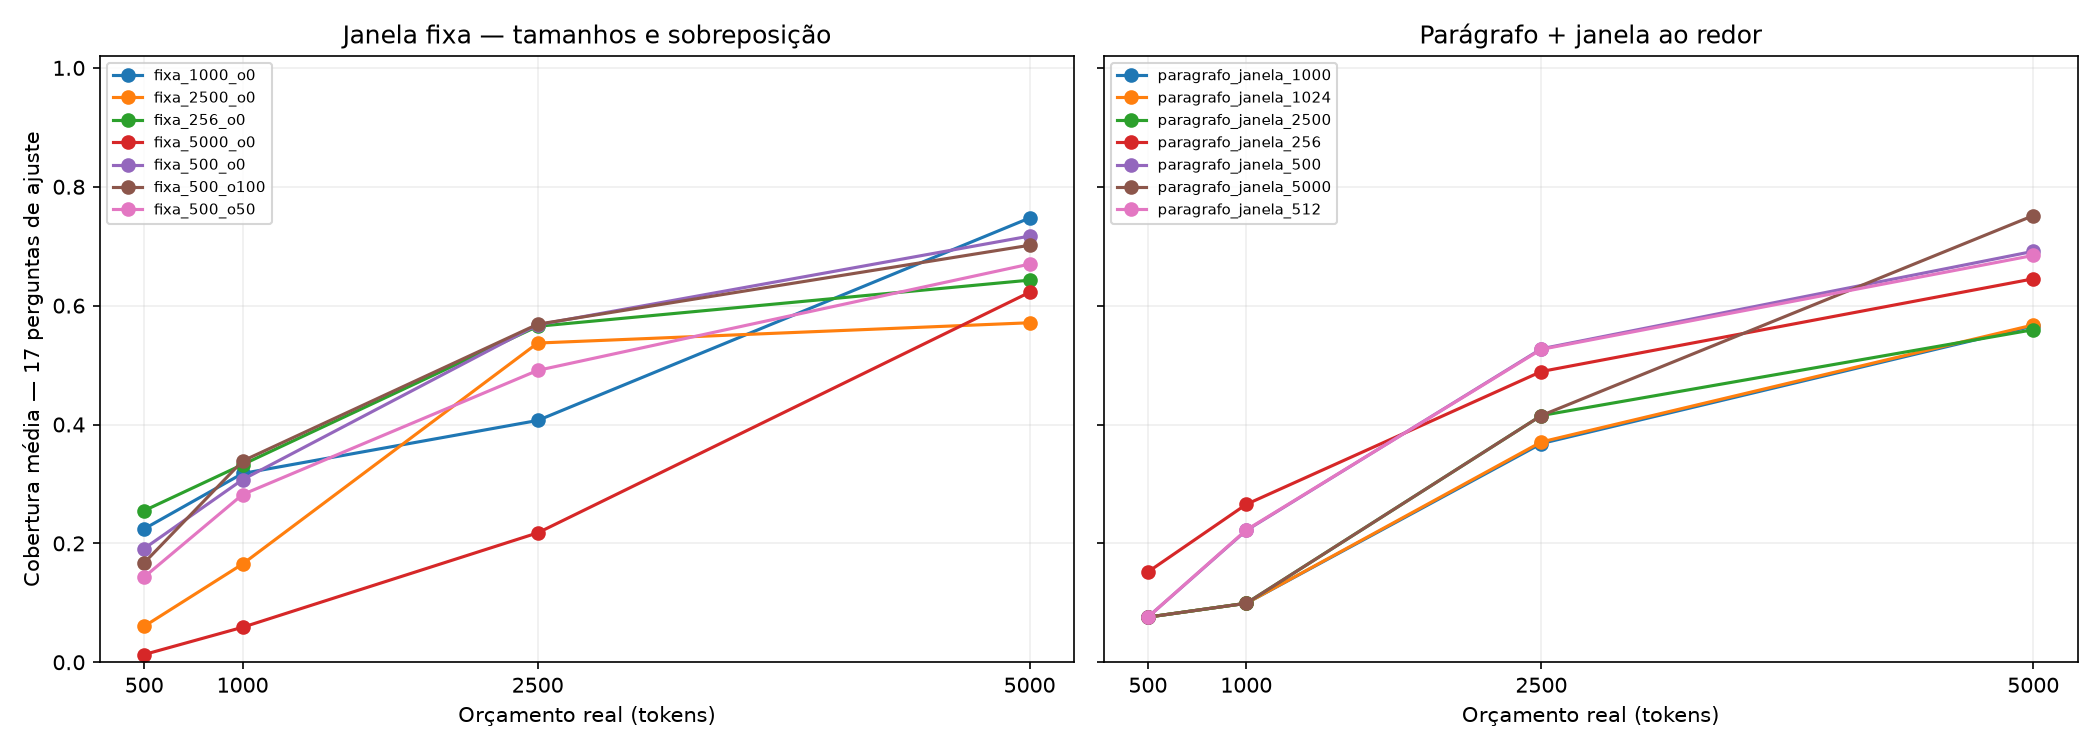

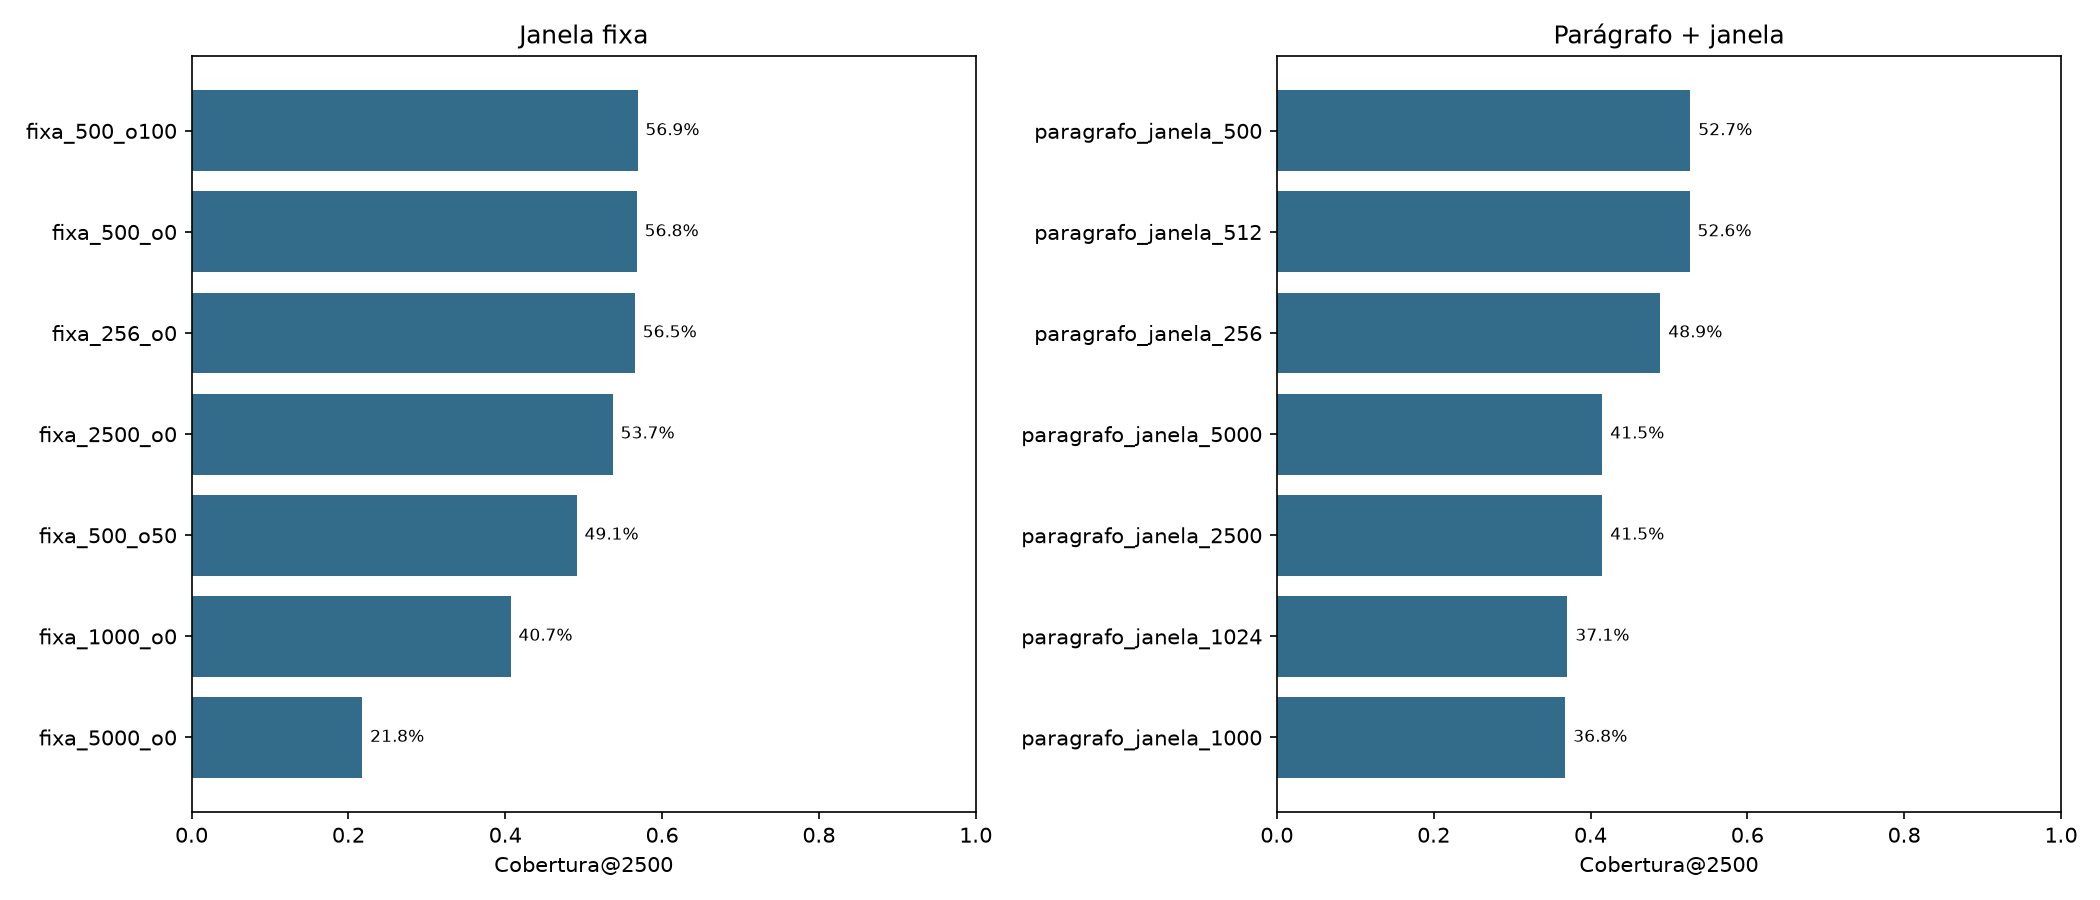

,familia,recuperador,versao,cobertura_2500,perguntas,tokens_medios,vetores_indice
0,fixa,BGE-M3,fixa_500_o100,0.5687,17,2500.0,308
1,paragrafo_janela,BGE-M3,paragrafo_janela_500,0.5274,17,2500.0,1826


**Bootstrap pareado entre as finalistas no ajuste:** 4 vitórias, 10 empates e 3 derrotas para `BGE-M3 / fixa_500_o100` contra `BGE-M3 / paragrafo_janela_500`; diferença 4.1 p.p., IC95% [-16.3; 23.9]. Seleção e comparação são exploratórias nesta fase; o teste reservado vem depois do congelamento.

As alternativas de ementa de P01/P02/P23 foram acrescentadas durante o ajuste. As métricas das duas famílias foram recalculadas com o mesmo gabarito atualizado; não se misturam os valores históricos da versão anterior.

In [26]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/jurisprudencia').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from worker.ingestao.jurisprudencia import finalistas_chunking, teste_final_chunking, relatorio_finalistas
EXECUTAR_VARREDURA = False
if EXECUTAR_VARREDURA:
    if (ROOT/'avaliacao/dados/jurisprudencia/protocolo_congelado.json').exists():
        raise RuntimeError('A seleção foi congelada. Leia os resultados salvos para esta reserva.')
    finalistas_chunking.run(ROOT)
    relatorio_finalistas.finalize_adjustment(ROOT)
RELATORIO_FINALISTAS = relatorio_finalistas.render_adjustment(ROOT)

In [27]:
PROTOCOLO_FINAL = teste_final_chunking.load_protocol(ROOT)
display(pd.DataFrame(PROTOCOLO_FINAL['protocolo']['finalistas']))
print('SHA-256 do protocolo:',PROTOCOLO_FINAL['sha256'])
print('Corpus congelado:',PROTOCOLO_FINAL['protocolo']['corpus_sha256'])
print('Orçamentos:',PROTOCOLO_FINAL['protocolo']['orcamentos'])
print('Congelamento realizado após o ajuste e antes da anotação e busca reservada.')

SHA-256 do protocolo: 0efa04e416e881e983372747b1e3ad1bb8563d9d7682c24f946ab03a47ef16ac
Corpus congelado: 6585a86de48b51ab3339b0a3f4cb541612c07c3134b9a85bd7fb186171710617
Orçamentos: [500, 1000, 2500, 5000]
Congelamento realizado após o ajuste e antes da anotação e busca reservada.


,familia,recuperador,versao,cobertura_2500,perguntas,tokens_medios,vetores_indice
0,fixa,BGE-M3,fixa_500_o100,0.568713,17,2500.0,308
1,paragrafo_janela,BGE-M3,paragrafo_janela_500,0.527387,17,2500.0,1826


## Teste reservado — sete perguntas, duas finalistas congeladas

O teste usa os parâmetros e o corpus congelados **antes da abertura das sete perguntas** nesta etapa. Os gabaritos reservados são registrados antes de executar a busca das finalistas. Fontes encontradas durante a anotação que não estejam no corpus congelado servem como referências de avaliação, sem serem acrescentadas ao índice. Isso permite distinguir falha de cobertura da base de falha de chunking/ordenação.

São executadas as sete consultas em ambas as finalistas, com os mesmos orçamentos. Cobertura por intervalo é calculada para perguntas com referência jurídica; controles comportamentais, quando presentes, têm busca registrada e cobertura indefinida. A resposta de referência exibida é um gabarito, **não uma resposta gerada por LLM**.

O teste é consumido uma vez. O marcador de início e os checkpoints por pergunta são preservados; a leitura das saídas não repete buscas. O executor desta etapa é `scripts/run_chunking_teste_final.py`. Uma retomada técnica mantém os mesmos parâmetros, fontes e gabaritos e pula checkpoints concluídos. Não há nova escolha de tamanho ou sobreposição a partir do resultado reservado.

O histórico anterior registrou exposição em buscas exploratórias antes da reserva prospectiva. Portanto, esta avaliação não deve ser apresentada como um conjunto externo completamente intocado. O resultado permanece limitado ao corpus e à pequena amostra reservada.

Protocolo congelado SHA-256: 0efa04e416e881e983372747b1e3ad1bb8563d9d7682c24f946ab03a47ef16ac


**Teste reservado concluído uma vez.** As saídas abaixo são lidas do relatório; esta célula não faz novas buscas.

,query_id,pergunta,avaliacao,resposta_de_referencia
0,juris_008,Fui demitido por justa causa por faltar duas v...,suporte_intervalos,Duas ausências não determinam automaticamente ...
1,juris_009,A empresa me deu justa causa sem nunca ter me ...,suporte_intervalos,"É possível questionar a justa causa, mas a fal..."
2,juris_015,Meu chefe me xingava na frente dos colegas. Is...,suporte_intervalos,Ofensas e humilhações comprovadas podem fundam...
3,juris_016,Cobrança de metas abusivas com ameaça de demis...,suporte_intervalos,"A cobrança de metas, quando acompanhada de des..."
4,juris_021,Eu recebia parte do salário por fora. Isso ent...,suporte_intervalos,"No acórdão de referência, comissões pagas fora..."
5,juris_025,O que mudou no entendimento sobre horas de des...,suporte_intervalos,O acórdão contrapõe a redação anterior do art....
6,juris_030,Quanto exatamente eu vou receber de indenizaçã...,comportamental,Não garantir valor exato de indenização. O val...


,versao,cobertura_2500,perguntas_com_intervalo,perguntas_fonte_no_corpus
0,fixa_500_o100,0.0,6,0
1,paragrafo_janela_500,0.0,6,0


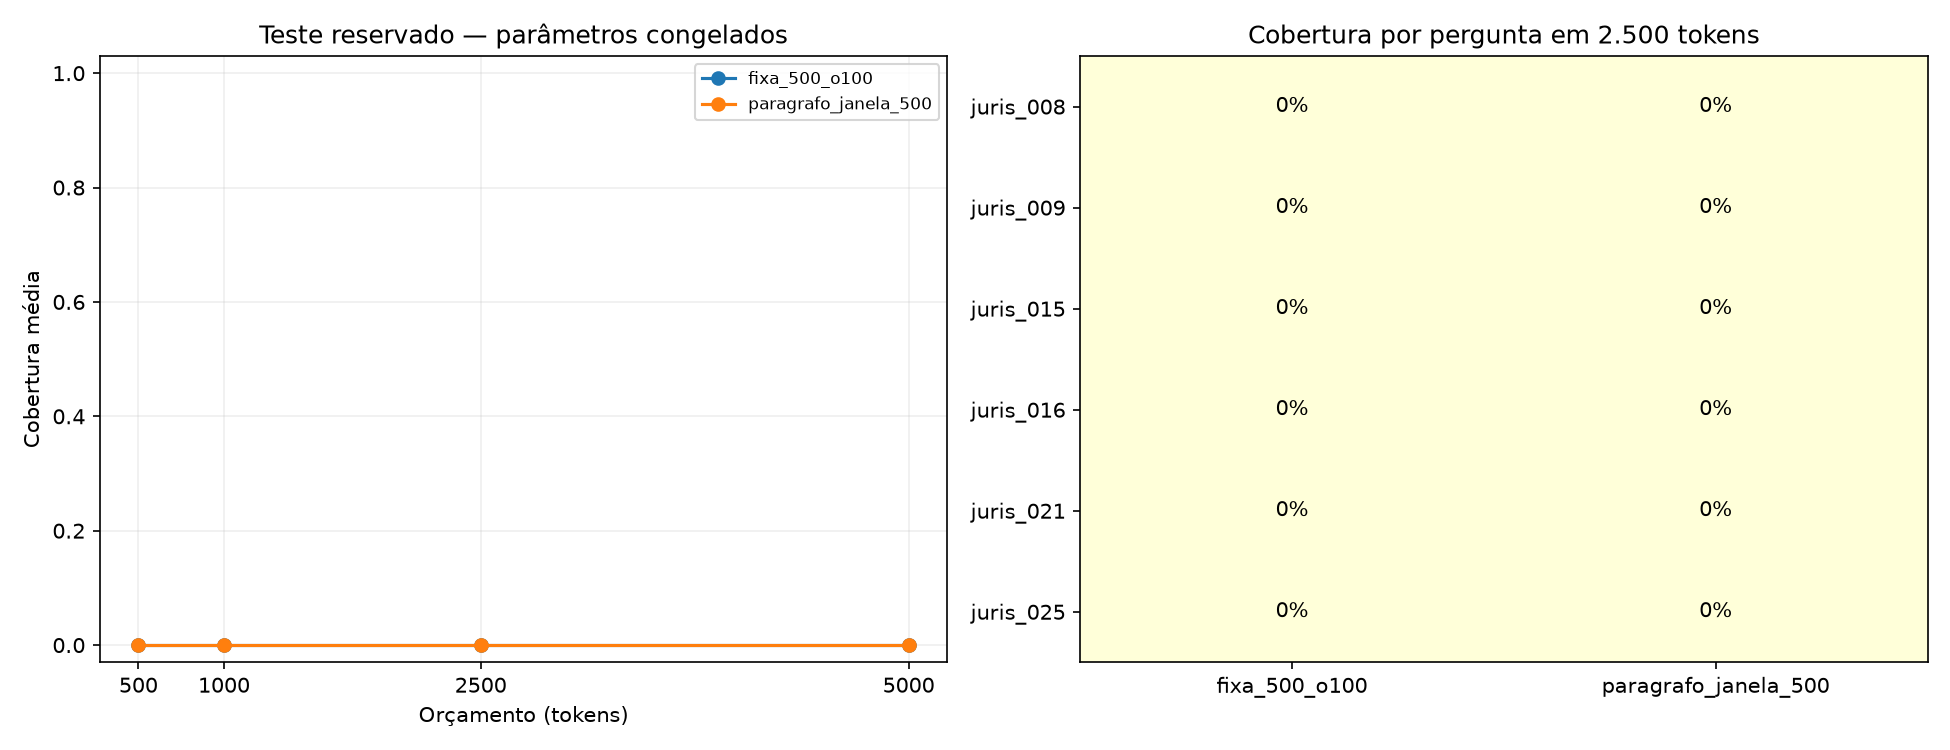

**Diagnóstico secundário: cobertura somente nas perguntas com alguma alternativa integralmente disponível no corpus congelado.**

,versao,cobertura_condicional_2500,perguntas


,query_id,versao,cobertura,documento_suporte_no_corpus,avaliacao,tokens_utilizados
2,juris_008,fixa_500_o100,0.0,False,suporte_intervalos,2500
6,juris_009,fixa_500_o100,0.0,False,suporte_intervalos,2500
10,juris_015,fixa_500_o100,0.0,False,suporte_intervalos,2500
14,juris_016,fixa_500_o100,0.0,False,suporte_intervalos,2500
18,juris_021,fixa_500_o100,0.0,False,suporte_intervalos,2500
22,juris_025,fixa_500_o100,0.0,False,suporte_intervalos,2500
26,juris_030,fixa_500_o100,NaN,NaN,comportamental,2500
30,juris_008,paragrafo_janela_500,0.0,False,suporte_intervalos,2500
34,juris_009,paragrafo_janela_500,0.0,False,suporte_intervalos,2500
38,juris_015,paragrafo_janela_500,0.0,False,suporte_intervalos,2500


,a,b,n,vitorias,empates,derrotas,delta_media,ic95_inf,ic95_sup,seed,replicas
0,BGE-M3 / fixa_500_o100,BGE-M3 / paragrafo_janela_500,6,0,6,0,0.0,0.0,0.0,20261114,2000


**Veredicto:** As fontes de referência não estavam no corpus congelado. O resultado mede ausência de cobertura da base; empate não demonstra equivalência entre os chunkings. Reserva prospectiva, conforme registro histórico. Não é teste externo independente; corpus de 18 documentos e amostra pequena.

As fontes usadas para anotar as sete perguntas foram registradas antes da busca das finalistas. Uma referência externa ao índice não foi acrescentada ao corpus após o congelamento. Perguntas comportamentais, quando presentes, têm busca registrada e cobertura indefinida; não há geração ou julgamento de resposta por LLM nesta etapa.

In [28]:
from pathlib import Path
import sys, json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/jurisprudencia').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from worker.ingestao.jurisprudencia import teste_final_chunking, relatorio_finalistas
EXECUTAR_TESTE_RESERVADO = False
if EXECUTAR_TESTE_RESERVADO:
    teste_final_chunking.run(ROOT)
    relatorio_finalistas.finalize_final(ROOT)
RELATORIO_TESTE_FINAL = relatorio_finalistas.render_final(ROOT)

In [29]:
import subprocess
TESTES_RESERVA = subprocess.run([sys.executable,'-m','unittest','discover','-s',str(ROOT/'tests'),
    '-p','test_finalistas_teste_reservado.py'],cwd=ROOT,capture_output=True,text=True)
print(TESTES_RESERVA.stdout + TESTES_RESERVA.stderr)
assert TESTES_RESERVA.returncode == 0
MARCADOR_FINAL = json.loads((ROOT/'avaliacao/dados/jurisprudencia/teste_final_iniciado.json').read_text(encoding='utf-8'))
PROTOCOLO_FINAL = teste_final_chunking.load_protocol(ROOT)
assert MARCADOR_FINAL['protocolo_sha256'] == PROTOCOLO_FINAL['sha256']
CONCLUSAO_FINAL = json.loads((RELATORIO_TESTE_FINAL/'concluido.json').read_text(encoding='utf-8'))
assert CONCLUSAO_FINAL['consultas'] == 7 and CONCLUSAO_FINAL['finalistas'] == 2
print('Teste reservado concluído e registrado; saídas lidas sem nova execução.')

......
----------------------------------------------------------------------
Ran 6 tests in 0.064s

OK

Teste reservado concluído e registrado; saídas lidas sem nova execução.


## Avaliação complementar das finalistas — corpus com suporte e distratores

Esta etapa responde à limitação observada no teste anterior: as fontes de suporte estavam fora do índice. O resultado anterior, seu corpus, os gabaritos e os marcadores de execução permanecem preservados. **As perguntas já foram expostas; esta rodada é complementar e não constitui novo teste cego.**

O corpus é a união dos 18 acórdãos do piloto com **todo o lote de candidatos levantado para a anotação das perguntas reservadas**. Não são selecionados apenas os documentos que favorecem uma estratégia, nem se muda a base entre os recuperadores. Todos os intervalos de suporte das seis perguntas jurídicas dessa coorte estão presentes e são verificados por hashes no texto protegido anterior ao chunking. Os demais documentos atuam como distratores, inclusive julgados dos mesmos temas.

Mantêm-se as finalistas e seus parâmetros: **janela fixa de 500 tokens com 100 tokens de sobreposição** e **parágrafo indexado com expansão centrada em uma janela de 500 tokens**. Não há nova varredura. O preenchimento de contexto usa T = 500/1.000/2.500/5.000 tokens, desconta sobreposições e limita o texto efetivamente entregue. A expansão depende do acerto recuperado, sem consultar o gabarito. Usam-se BGE-M3 no snapshot anterior como recuperador principal e BM25 como comparação secundária.

São executadas as 30 consultas originais nas duas finalistas e nos dois recuperadores. A comparação principal usa as **seis perguntas jurídicas antes reservadas**, com bootstrap pareado por pergunta (2.000 réplicas, seed fixa). P30 é controle comportamental: a busca é executada, mas cobertura por caracteres não avalia a capacidade de evitar promessa de indenização; não há LLM nesta etapa. As 17 perguntas de ajuste com gabarito aparecem separadamente como diagnóstico, e as seis restantes sem intervalos não recebem nota inventada.

Cobertura mede os intervalos anotados, não a correção integral de uma resposta jurídica. Em especial, P09 usa um julgamento contrastivo com punições anteriores; P15 permite observar um caso de humilhação e um valor concreto, sem estimar valores usuais dos tribunais. O corpus enriquecido é dirigido pelas referências e não representa a distribuição natural de toda a base. A escolha operacional abaixo é limitada a esse experimento e não transforma as perguntas já utilizadas em validação independente.

**Corpus complementar:** 35 acórdãos. Foram mantidos os 18 anteriores e incluído todo o lote de candidatos já levantado, sem filtrar pelo desempenho. Os trechos de referência das seis perguntas estão agora no índice de ambas as estratégias. O teste anterior de cobertura zero permanece preservado. **Esta rodada é complementar, com perguntas já expostas.**

,coorte,recuperador,versao,cobertura_2500,perguntas,tokens_medios
0,ajuste_anterior,BGE-M3,fixa_500_o100,0.539245,17,2500.0
1,ajuste_anterior,BGE-M3,paragrafo_janela_500,0.461553,17,2500.0
2,ajuste_anterior,BM25,fixa_500_o100,0.414053,17,2500.0
3,ajuste_anterior,BM25,paragrafo_janela_500,0.306569,17,2500.0
4,reserva_ja_exposta,BGE-M3,fixa_500_o100,0.378335,6,2500.0
5,reserva_ja_exposta,BGE-M3,paragrafo_janela_500,0.231699,6,2500.0
6,reserva_ja_exposta,BM25,fixa_500_o100,0.076760,6,2500.0
7,reserva_ja_exposta,BM25,paragrafo_janela_500,0.082028,6,2500.0


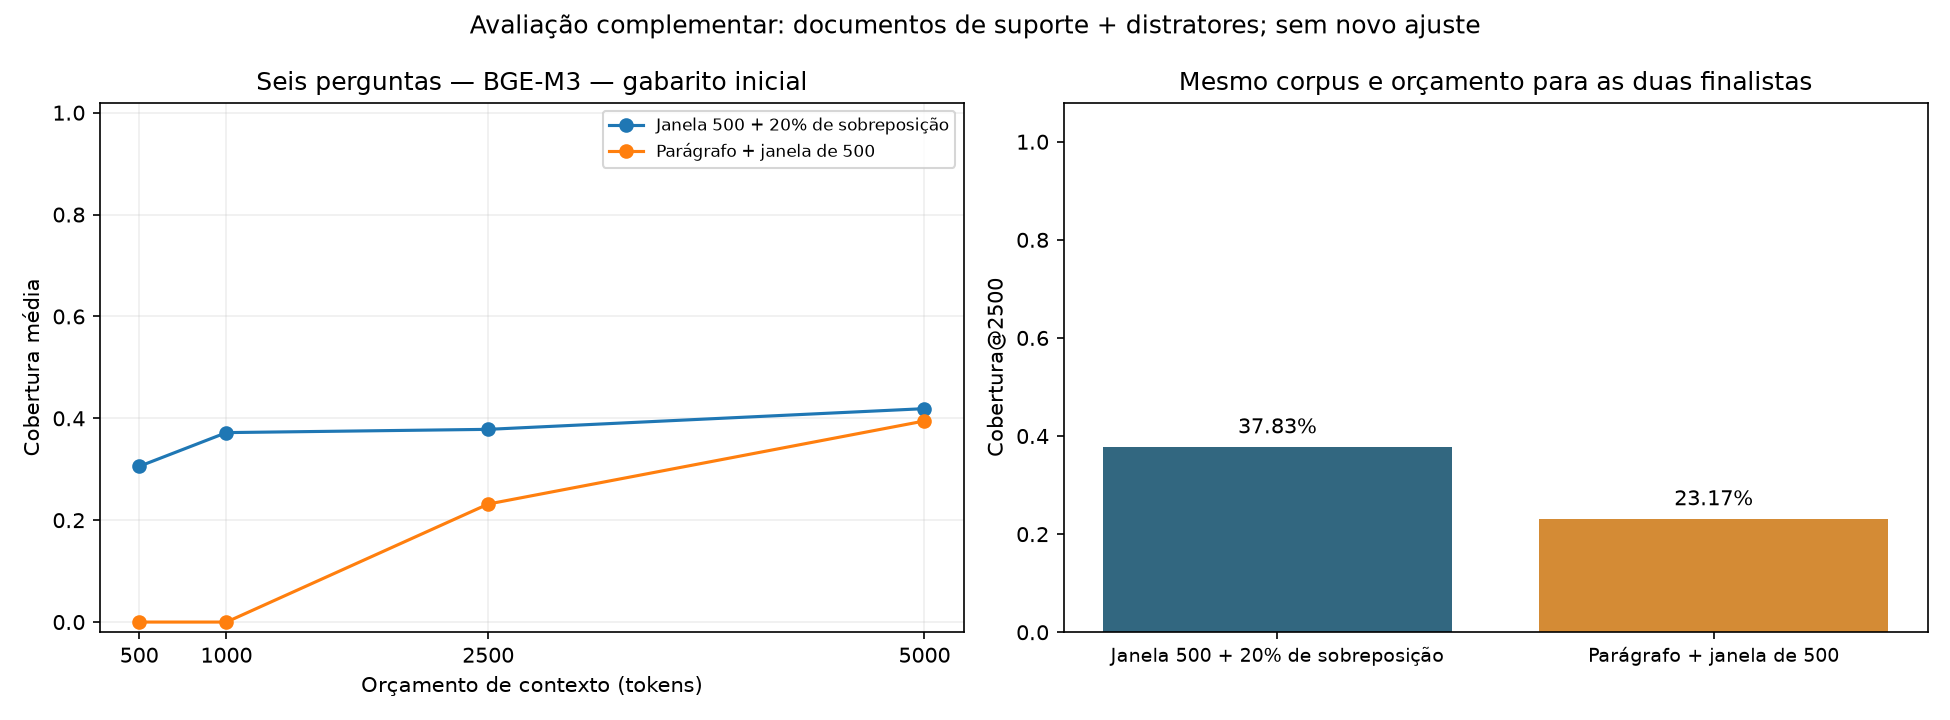

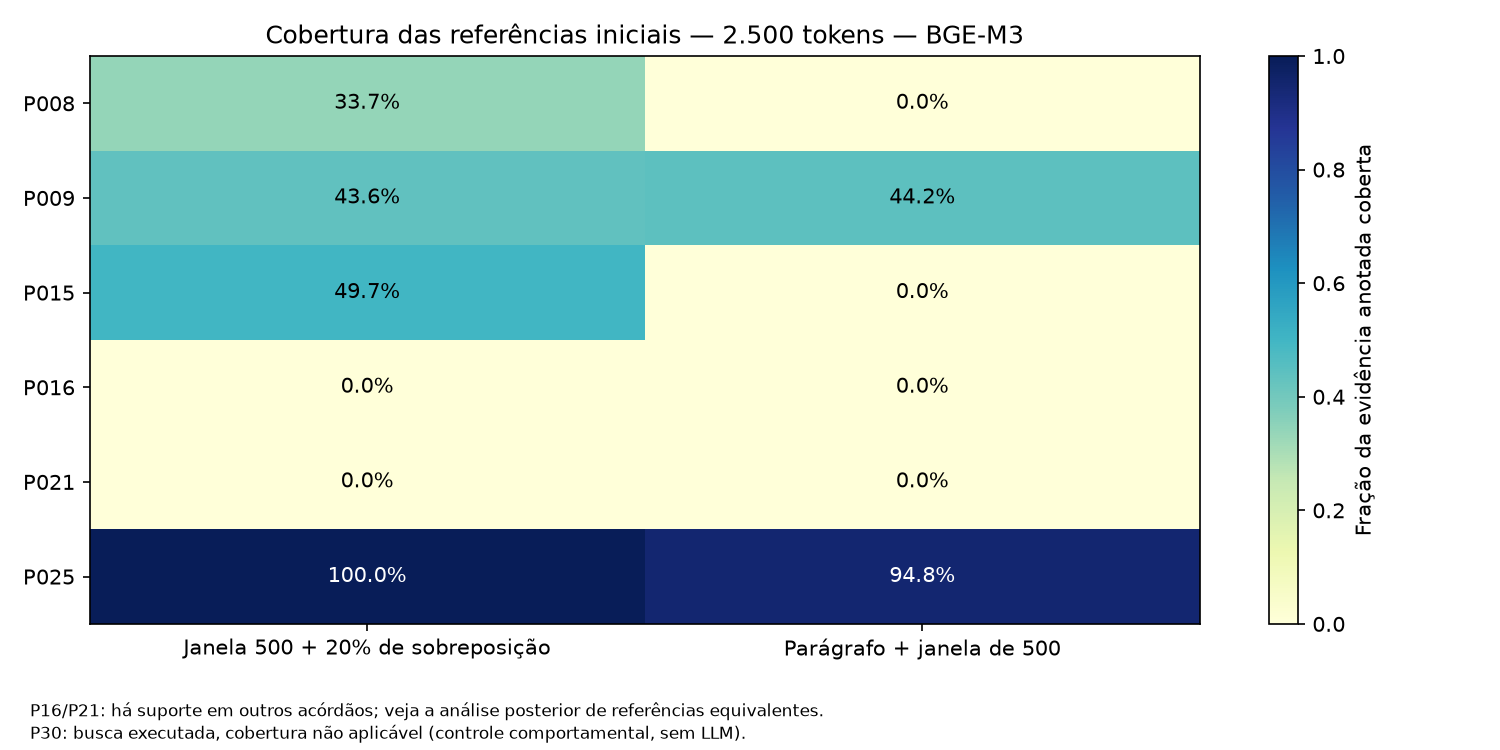

,query_id,fixa_500_o100,paragrafo_janela_500,delta_fixa_menos_paragrafo,resultado
0,juris_008,0.337121,0.000000,0.337121,vitória da janela fixa
1,juris_009,0.435971,0.442206,-0.006235,vitória do parágrafo
2,juris_015,0.496917,0.000000,0.496917,vitória da janela fixa
3,juris_016,0.000000,0.000000,0.000000,empate
4,juris_021,0.000000,0.000000,0.000000,empate
5,juris_025,1.000000,0.947989,0.052011,vitória da janela fixa


**Leitura dos zeros e sensibilidade do gabarito:** P16 e P21 tiveram trechos relevantes de outros acórdãos no contexto. Foram verificadas três alternativas adicionais nesses dois casos, mantendo corpus, rankings, contextos e o gabarito inicial. A tabela abaixo é **posterior à inspeção**, não substitui a comparação principal e não é um novo teste cego. A cobertura mede referências anotadas; não equivale à correção de uma resposta gerada.

,recuperador,versao,cobertura_2500,perguntas
0,BGE-M3,fixa_500_o100,0.711668,6
1,BGE-M3,paragrafo_janela_500,0.398366,6
2,BM25,fixa_500_o100,0.243427,6
3,BM25,paragrafo_janela_500,0.329995,6


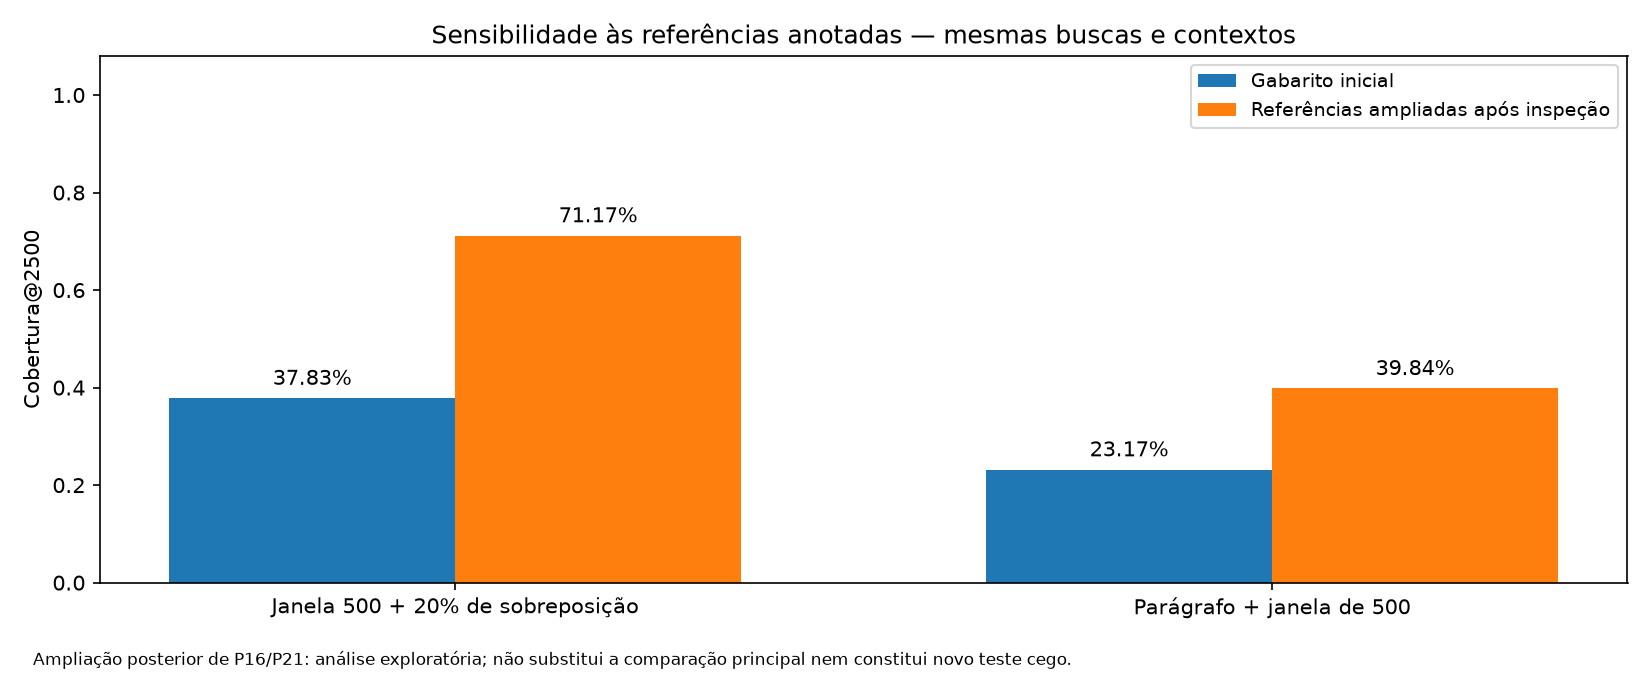

,query_id,versao,cobertura_gabarito_original,cobertura
30,juris_008,fixa_500_o100,0.337121,0.337121
34,juris_009,fixa_500_o100,0.435971,0.435971
58,juris_015,fixa_500_o100,0.496917,0.496917
62,juris_016,fixa_500_o100,0.000000,1.000000
82,juris_021,fixa_500_o100,0.000000,1.000000
98,juris_025,fixa_500_o100,1.000000,1.000000
118,juris_030,fixa_500_o100,NaN,NaN
270,juris_008,paragrafo_janela_500,0.000000,0.000000
274,juris_009,paragrafo_janela_500,0.442206,0.442206
298,juris_015,paragrafo_janela_500,0.000000,0.000000


**Efeito da ampliação do corpus:** a tabela compara as mesmas perguntas e parâmetros em bases diferentes. A diferença não é ganho causado pelo chunking nem um novo resultado cego.

,query_id,versao,cobertura_corpus_18,cobertura_corpus_ampliado
0,juris_008,fixa_500_o100,0.0,0.337121
1,juris_009,fixa_500_o100,0.0,0.435971
2,juris_015,fixa_500_o100,0.0,0.496917
3,juris_016,fixa_500_o100,0.0,0.000000
4,juris_021,fixa_500_o100,0.0,0.000000
5,juris_025,fixa_500_o100,0.0,1.000000
6,juris_008,paragrafo_janela_500,0.0,0.000000
7,juris_009,paragrafo_janela_500,0.0,0.442206
8,juris_015,paragrafo_janela_500,0.0,0.000000
9,juris_016,paragrafo_janela_500,0.0,0.000000


**Bootstrap pareado:** diferença = janela fixa − parágrafo. As coortes não são misturadas.

,coorte,recuperador,a,b,n,vitorias,empates,derrotas,delta_media,ic95_inf,ic95_sup,seed,replicas
0,reserva_ja_exposta,BGE-M3,BGE-M3 / fixa_500_o100,BGE-M3 / paragrafo_janela_500,6,3,2,1,0.146636,0.006590,0.313314,20261114,2000
1,reserva_ja_exposta,BM25,BM25 / fixa_500_o100,BM25 / paragrafo_janela_500,6,1,4,1,-0.005268,-0.031061,0.015257,20261114,2000
2,ajuste_anterior,BGE-M3,BGE-M3 / fixa_500_o100,BGE-M3 / paragrafo_janela_500,17,4,10,3,0.077692,-0.143738,0.291063,20261114,2000
3,ajuste_anterior,BM25,BM25 / fixa_500_o100,BM25 / paragrafo_janela_500,17,5,10,2,0.107485,-0.025205,0.267623,20261114,2000


**Sensibilidade por documento:** P15 e P16 compartilham acórdão. Reamostragem dos cinco grupos documentais, mantendo juntas suas perguntas; leitura complementar ao bootstrap principal por pergunta.

... (5 outputs left out)

,versao,mediana,p90,maximo,unidades_medias
0,fixa_500_o100,2500.0,2500.0,2500,5.833333
1,paragrafo_janela_500,2500.0,2500.0,2500,7.000000


,versao,taxa_fragmentacao_indice,unidades_minimas_media,evidencia_perdida_encoder_media,documento_no_contexto_taxa
0,fixa_500_o100,0.333333,1.666667,0.0,0.833333
1,paragrafo_janela_500,1.000000,5.333333,0.0,1.000000


**Truncamento real do encoder:** BGE-M3 usa limite de 8.192 tokens incluindo os especiais. Unidades acima de 512 tokens não são automaticamente truncadas neste encoder.

,indice,unidades,unidades_truncadas,tokens_encoder_max
0,_paragrafo_index,3064,0,1842
1,fixa_500_o100,488,0,502


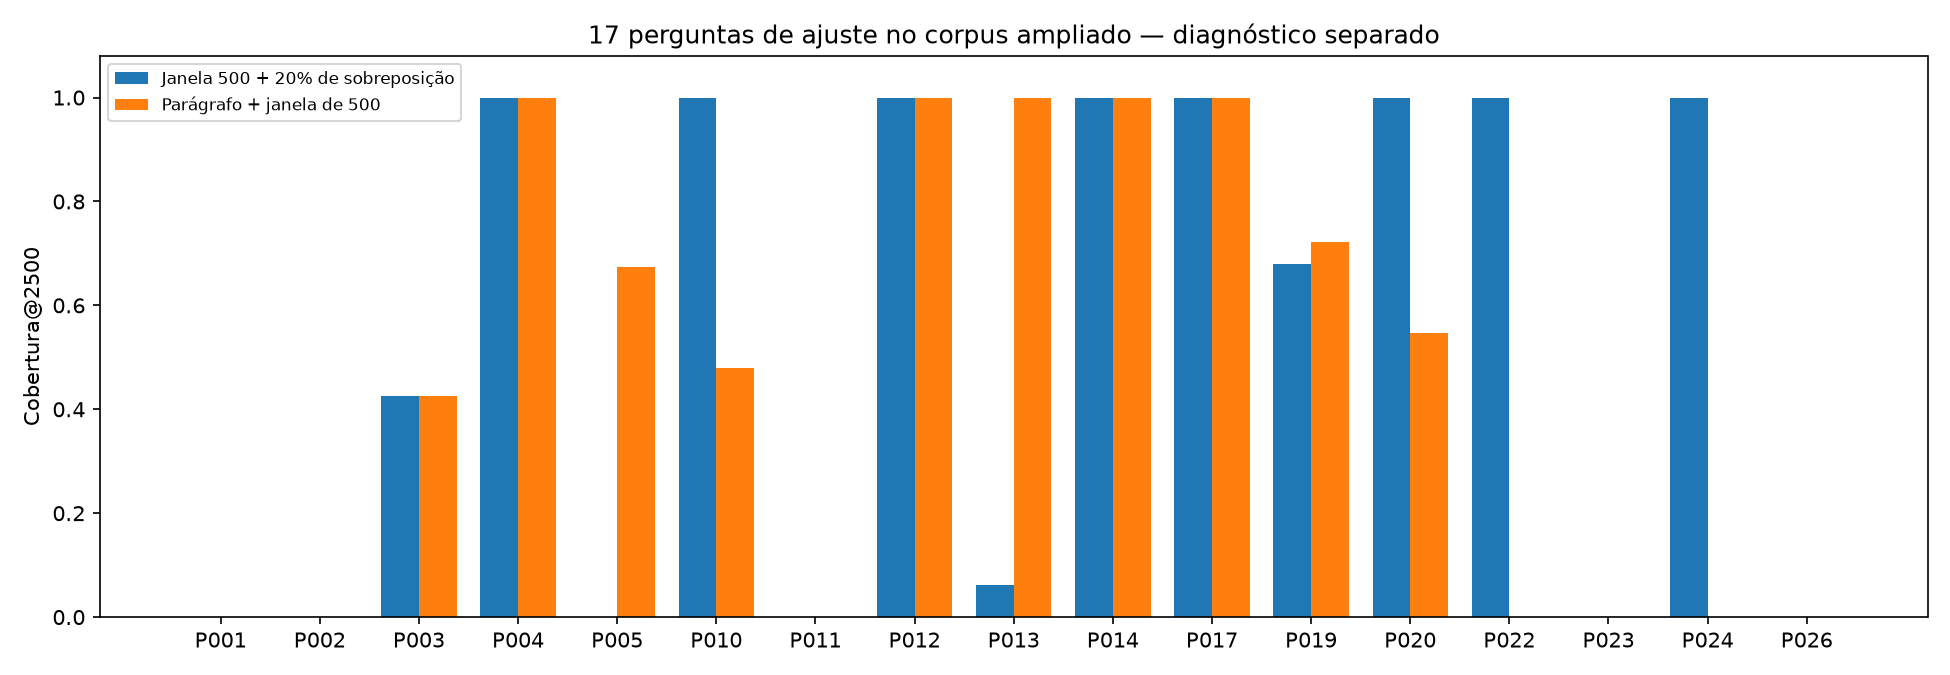

**Veredicto:** A janela fixa teve vantagem pareada com intervalo bootstrap acima de zero nesta avaliação complementar.

**Candidata operacional nesta comparação:** Janela 500 + 20% de sobreposição. Maior cobertura observada na comparação complementar; não houve novo ajuste de tamanho ou sobreposição.

**Limites de interpretação:**

- Avaliação complementar de perguntas já expostas; não é teste cego independente.
- Corpus enriquecido dirigido pelas referências; não representa toda a base nem sua distribuição natural.
- Apenas seis perguntas pontuáveis na coorte principal; bootstrap pequeno não garante estabilidade.
- P15 e P16 compartilham acórdão e evidências. A sensibilidade por documento usa cinco grupos; o bootstrap por pergunta não torna essas observações independentes.
- P09 usa caso contrastivo com punições anteriores, não decisão direta de dispensa sem advertência.
- P15 usa humilhação reiterada e um valor de um julgamento; não estima valores usuais de indenização.
- As 17 perguntas de ajuste são exibidas separadamente; não viram novas perguntas de teste.
- Não houve geração de respostas por LLM nem avaliação comportamental de P30.
- P16 e P21 recuperaram suporte em acórdãos não anotados no gabarito inicial. A análise posterior de alternativas é separada; zero na referência inicial não prova ausência de suporte jurídico.

In [30]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/jurisprudencia').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from worker.ingestao.jurisprudencia import avaliacao_complementar,relatorio_complementar
EXECUTAR_AVALIACAO_COMPLEMENTAR=False
if EXECUTAR_AVALIACAO_COMPLEMENTAR:
    avaliacao_complementar.run(ROOT)
    relatorio_complementar.finalize(ROOT)
RELATORIO_COMPLEMENTAR=relatorio_complementar.render(ROOT)

In [31]:
import subprocess
from worker.ingestao.jurisprudencia.audit import hash_file
TESTES_COMPLEMENTARES=subprocess.run([sys.executable,'-m','unittest','discover','-s',str(ROOT/'tests'),
    '-p','test_avaliacao_complementar.py'],cwd=ROOT,capture_output=True,text=True)
print(TESTES_COMPLEMENTARES.stdout+TESTES_COMPLEMENTARES.stderr)
assert TESTES_COMPLEMENTARES.returncode==0
PRESERVACAO_COMPLEMENTAR=json.loads((RELATORIO_COMPLEMENTAR/'preservacao_notebook.json').read_text(encoding='utf-8'))
for nome,digest in PRESERVACAO_COMPLEMENTAR['arquivos_protegidos'].items():assert hash_file(ROOT/nome)==digest,nome
CONCLUSAO_COMPLEMENTAR=json.loads((RELATORIO_COMPLEMENTAR/'concluido.json').read_text(encoding='utf-8'))
assert CONCLUSAO_COMPLEMENTAR['consultas']==30 and CONCLUSAO_COMPLEMENTAR['finalistas']==2
assert CONCLUSAO_COMPLEMENTAR['recuperadores']==2
print('30 consultas × 2 finalistas × 2 recuperadores concluídas. Teste anterior e demais notebooks preservados.')

.....
----------------------------------------------------------------------
Ran 5 tests in 0.026s

OK

30 consultas × 2 finalistas × 2 recuperadores concluídas. Teste anterior e demais notebooks preservados.


## DECISAO DE ESTRATEGIA DE CHUNKING

### Decisão: estratégia de chunking do RAG de jurisprudência

**Decisão.** Adotar a **janela fixa de 500 tokens**, contados pelo tokenizador do **BGE-M3**, com **sobreposição de 20% (100 tokens)**, sem classificação de seção ou tema. Esta é a estratégia padrão selecionada para a próxima etapa do RAG de jurisprudência; a estratégia de legislação permanece preservada.

**Alternativas comparadas.** Janela fixa em vários tamanhos e sobreposições, parágrafo, seção e tema, parágrafo mínimo, seção com teto de tamanho, parágrafo + seção e parágrafo + janela ao redor. As finalistas foram a janela fixa de 500 tokens com 100 de sobreposição e o parágrafo indexado com expansão centrada em uma janela de 500 tokens.

**Método.** Perguntas em linguagem de trabalhador, com gabarito por intervalo de caracteres no documento-base protegido, anterior ao chunking. A métrica principal foi **Cobertura@T**: a fração da evidência anotada coberta pelo contexto recuperado, limitado a T = 500, 1.000, 2.500 e 5.000 tokens, com o mesmo orçamento para todas as estratégias. O resumo principal é a cobertura média em T = 2.500. Usaram-se BM25 e BGE-M3, sem LLM; BGE-M3 foi o recuperador principal na seleção das finalistas. Nenhuma pergunta de legislação foi usada como substituta.

**Resultados com BGE-M3 — Cobertura@2.500.**

| Conjunto e corpus | Janela 500 | Parágrafo + janela 500 |
| --- | ---: | ---: |
| Ajuste: 17 perguntas, 18 acórdãos, sobreposição de 100 tokens | **56,9%** | 52,7% |
| Ajuste: 17 perguntas, 18 acórdãos, janela sem sobreposição | 56,8% | — |
| Reavaliação do ajuste: 17 perguntas, corpus ampliado de 35 acórdãos | **53,9%** | 46,2% |
| Avaliação complementar: 6 perguntas antes reservadas, 35 acórdãos, referências iniciais | **37,8%** | 23,2% |
| Mesmas 6 perguntas e contextos, referências ampliadas após inspeção — exploratório | **71,2%** | 39,8% |

As médias de corpus diferentes não medem uma mudança causada apenas pelo chunking. O teste original das sete consultas no corpus de 18 acórdãos teve cobertura zero nas seis perguntas pontuáveis porque suas fontes de referência estavam fora do índice; ele foi preservado. Os resultados de 37,8% e 23,2% pertencem à **avaliação complementar**, não a um novo teste cego. P30 teve busca executada, mas sua natureza comportamental não é avaliada por cobertura de caracteres.

**Onde as seis alternativas não escolhidas deixaram de avançar.** “Não escolhida” significa não adotada como padrão nesta decisão, sem afirmar inferioridade universal. As cinco primeiras linhas resumem a triagem com orçamento centrado, 17 perguntas e o gabarito daquela etapa; a última descreve a comparação complementar das finalistas. Cada resumo é restrito à sua etapa.

| Alternativa | Etapa e resultado que fundamentaram a não adoção |
| --- | --- |
| **Parágrafo sem expansão** | No ajuste com orçamento centrado, obteve **32,3%**, contra **56,8%** da janela 500 sem sobreposição. O parágrafo isolado não foi levado à comparação final; sua expansão continuou sendo investigada. |
| **Seção e tema** | No mesmo ajuste, obteve **41,0%**. Reunir texto por seção/tema não compensou a limitação de contexto; seções extensas também motivaram o teste de uma variante com teto. |
| **Parágrafo mínimo** | No mesmo ajuste, obteve **48,5%**. Agrupar parágrafos curtos na mesma seção melhorou o parágrafo isolado, mas não superou a janela fixa nem o parágrafo com janela de 500. |
| **Seção com teto de tamanho** | No mesmo ajuste, obteve **52,0%**. Limitar a seção melhorou a versão sem teto, mas permaneceu abaixo da janela fixa (**56,8%**) e da alternativa parágrafo + janela 500 (**52,7%**). |
| **Parágrafo + seção** | No mesmo ajuste, obteve **42,1%**. Entregar a seção expandida consumiu orçamento sem vantagem de cobertura suficiente; a investigação avançou com expansão local limitada por janela. |
| **Parágrafo + janela ao redor** | Avançou como finalista, com teto de **500 tokens**. Na comparação complementar, ficou em **23,2%**, contra **37,8%** da janela fixa, e exigiu **3.064 vetores**, contra **488**; não foi adotado como padrão. |

As demais configurações de janela fixa deixaram de avançar na **grade equilibrada de sete configurações por família**: 500 tokens com 100 de sobreposição teve a maior cobertura de ajuste. A diferença para 500 sem sobreposição foi de apenas **0,1 ponto percentual**, portanto não constitui prova de ganho significativo causado pela sobreposição.

**Justificativa.**

- Maior Cobertura@2.500 com **BGE-M3** nas comparações das finalistas, inclusive na avaliação complementar; a ordenação não foi a mesma em todas as comparações com BM25.
- Unidades indexadas limitadas a **500 tokens**, com contexto final controlado por orçamento. Não se impôs top 5 fixo: deduplicação das sobreposições, separadores e cortes podem exigir mais de cinco unidades para preencher 2.500 tokens.
- As janelas têm até 500 tokens de texto (**502 com os tokens especiais**). Não houve truncamento dessas unidades no BGE-M3, cujo limite usado foi **8.192 tokens**; o corte do contexto pelo orçamento é uma operação diferente.
- Dispensa heurísticas de classificação de seção ou tema e usa menos vetores que a finalista de parágrafos, favorecendo simplicidade de implementação e manutenção.

**Limitações e leitura estatística.**

- A amostra é pequena. No ajuste com 17 perguntas, o intervalo bootstrap da diferença entre as finalistas incluiu zero. Na avaliação complementar com seis perguntas, a janela teve **3 vitórias, 2 empates e 1 derrota**: diferença média de **+14,7 pontos percentuais**, com IC bootstrap de 95% **[+0,7; +31,3]**. A sensibilidade por documento também ficou acima de zero (**[+0,9; +25,1]**), mas há apenas cinco grupos documentais, pois P15 e P16 compartilham acórdão.
- Esse resultado complementar favorece a janela **neste experimento**, sem estabelecer superioridade geral. As perguntas já estavam expostas e o corpus foi enriquecido com fontes de referência e distratores; não é uma avaliação independente em toda a base.
- Na reavaliação do ajuste com 35 acórdãos, **P01, P02, P11, P23 e P26** tiveram Cobertura@2.500 zero nas duas finalistas com BGE-M3. Isso significa ausência de cobertura dos intervalos anotados, não necessariamente ausência de jurisprudência ou de outra evidência útil.
- As referências de **P16 e P21** foram ampliadas depois da inspeção dos resultados. Essa sensibilidade permanece separada e exploratória; os rankings, os contextos, a comparação principal e os gabaritos anteriores foram preservados. Mesmo o gabarito ampliado não é um julgamento exaustivo de todos os trechos relevantes.
- P09 usa um caso contrastivo com punições anteriores; P15 observa um caso de humilhação e um valor de indenização, sem estimar valores usuais dos tribunais. A métrica mede cobertura de evidências anotadas, não a correção integral de uma resposta jurídica.
- Houve busca densa e lexical, **sem RRF nem reranker**. Com BM25, na coorte complementar de seis perguntas, as médias foram **7,7%** para a janela e **8,2%** para o parágrafo com janela, sem diferença bootstrap conclusiva.
- As vitórias alternadas entre as finalistas sugerem investigar complementaridade. Uma combinação das estratégias é possibilidade de trabalho futuro; seu benefício não foi testado.

**Escopo da conclusão.** A **janela fixa de 500 tokens com 100 tokens de sobreposição foi selecionada como estratégia padrão**, por decisão operacional apoiada nos resultados acima. Houve vantagem bootstrap na pequena avaliação complementar com BGE-M3, mas não se afirma superioridade estatística geral sobre todas as alternativas, nem validação independente para todo o corpus. A decisão não altera o processamento já adotado em legislação.